In [1]:
# ============================================================================
# CELL S0 — BOOTSTRAP / PACKAGE INSTALL   (v2 — numpy-pinning fix)
# Run order : 1  (must be the FIRST cell you run, on a FRESH kernel)
# Needs     : Internet ON (Kaggle ▸ Settings ▸ Internet). GPU not needed here.
# Provides  : every pip dependency, installed in ONE resolver pass:
#             SAM3 (official GitHub repo, cloned + pip install -e), transformers, accelerate, gradio,
#             rasterio, geopandas, shapely, pillow, huggingface_hub
#
# ⚠️ WHAT CHANGED IN v2 (fixes the S1 crash you hit):
#   The SAM3 repo's pyproject.toml pins "numpy>=1.26,<2". Its editable install
#   therefore DOWNGRADED the image's numpy 2.1.3 → 1.26.4. torch / torchvision /
#   rasterio in the Kaggle image are compiled against numpy 2.x, so S1 died at
#   `from transformers import pipeline` with a ValueError deep inside
#   torch._dynamo ("numpy.dtype size changed …").
#   v2 therefore: (a) records the session-start versions of numpy / torch /
#   torchvision, (b) FORCE-RESTORES numpy after every pip step, and
#   (c) verifies the EXACT imports that crashed (transformers.pipeline +
#   torchvision + numpy version) in a clean subprocess before S0 reports OK.
#
# ⚠️ KNOWN KAGGLE PITFALL — WHY THIS CELL IS PARANOID:
#   pip installing geo/segmentation stacks tends to move shared dependencies
#   underneath an already-running kernel. Any module already imported keeps
#   stale in-memory objects while its on-disk dependencies silently change;
#   the session later dies with confusing errors.
#
#   RULE ENFORCED HERE:
#     • Install FIRST (before any model cell ever imports anything).
#     • If sam3 / samgeo / groundingdino / supervision is ALREADY imported when
#       this cell starts → STOP immediately and print
#           Kernel ▸ Restart now, then re-run
#     • This cell itself NEVER imports the fragile modules; install
#       verification runs in a throwaway subprocess with its own sys.modules,
#       so this kernel stays pristine.
# ============================================================================

import os, sys, socket, subprocess, time

_T0 = time.time()
os.environ.setdefault("PIP_DISABLE_PIP_VERSION_CHECK", "1")
os.environ.setdefault("PIP_ROOT_USER_ACTION", "ignore")
# Less VRAM fragmentation for SAM3 (must be set BEFORE torch initialises CUDA;
# this cell never imports torch in the kernel, so it applies to S1-S3).
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

# ---------------------------------------------------------------------------
# Tunables (edit here, not below)
# ---------------------------------------------------------------------------
WORK_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.getcwd()

PIP_PACKAGES = [
    "transformers",                  # Qwen2.5-1.5B-Instruct (S1) + Qwen2.5-VL-3B (S2)
    "accelerate",                    # device_map="auto" across 2x T4
    "gradio",                        # 3-tab UI
    "rasterio",                      # GeoTIFF read/write for masks + scores
    "geopandas",                     # mask -> polygon -> GeoJSON (S4)
    "shapely",                       # geometry engine
    "pillow",                        # evidence rendering (S4)
    "huggingface_hub",               # HF_TOKEN login + gated SAM3 download (S1/S3)
]

SAM3_GIT_URL  = "https://github.com/facebookresearch/sam3.git"   # official SAM3 code
SAM3_ZIP_URL  = "https://github.com/facebookresearch/sam3/archive/refs/heads/main.zip"   # fallback #2
SAM3_REPO_DIR = os.path.join(WORK_DIR, "sam3_repo")                # clone location (S3 uses the same path)

# The packages that MUST NOT move after the installs. numpy is the known victim
# (SAM3 pins numpy<2 in pyproject.toml); torch/torchvision moving would be
# equally fatal, so they are recorded and guarded too.
PINNED_GUARDS = ("numpy", "torch", "torchvision")

# ---------------------------------------------------------------------------
# 0) Record the session-start versions of the guarded packages (BEFORE pip).
#    pip show imports nothing -> this kernel stays pristine.
# ---------------------------------------------------------------------------
def _pip_version(pkg):
    try:
        out = subprocess.run([sys.executable, "-m", "pip", "show", pkg],
                             capture_output=True, text=True, timeout=120).stdout or ""
    except Exception:
        return None
    for line in out.splitlines():
        if line.startswith("Version:"):
            return line.split(":", 1)[1].strip()
    return None

VERSIONS_AT_START = {p: _pip_version(p) for p in PINNED_GUARDS}
print("[S0] session-start versions:", VERSIONS_AT_START, flush=True)
NUMPY_EXPECTED = VERSIONS_AT_START.get("numpy")
if NUMPY_EXPECTED is None:
    print("❌ could not read the preinstalled numpy version — is pip broken?")
    sys.exit("S0 stopped — cannot determine baseline numpy")

# Verified in the step-4 subprocess — these MUST import cleanly, including
# the exact chain that crashed S1 last time.
CRITICAL_MODULES = {
    "sam3", "sam3.builder", "transformers", "transformers.pipeline",
    "accelerate", "gradio", "rasterio", "geopandas", "shapely", "PIL",
    "huggingface_hub", "torch", "numpy", "numpy-version", "torchvision",
}

def _restore_pinned():
    """Force the guarded packages back to their session-start versions.
    numpy is auto-restored (the SAM3 install is known to downgrade it to a
    numpy 1.x that torch/torchvision/rasterio cannot run on). A moved
    torch/torchvision cannot be safely repaired here -> hard stop."""
    changed = []
    for pkg in PINNED_GUARDS:
        start, now = VERSIONS_AT_START[pkg], _pip_version(pkg)
        if start and now and now != start:
            changed.append((pkg, start, now))
    for pkg, start, now in changed:
        if pkg == "numpy":
            print(f"[S0] ⚠️  numpy was moved {start} -> {now} by a pip step "
                  f"(SAM3 pins numpy<2).", flush=True)
            print(f"[S0]    force-restoring numpy=={start} — torch/torchvision/"
                  "rasterio are compiled against it.", flush=True)
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                                   f"numpy=={start}"])
        else:
            print(f"❌ {pkg} was moved {start} -> {now} and cannot be auto-repaired.", flush=True)
            sys.exit(f"S0 stopped — {pkg} drifted; restart kernel and re-run")
    if not changed:
        print("[S0] numpy / torch / torchvision unchanged by installs ✓", flush=True)

# ---------------------------------------------------------------------------
# 1) Poisoned-kernel guard — BEFORE any pip activity
# ---------------------------------------------------------------------------
_stale = sorted(m for m in ("sam3", "samgeo", "groundingdino", "supervision")
                if m in sys.modules)
if _stale:
    print("=" * 74)
    print("✋ REFUSING TO INSTALL — this kernel has already imported:")
    print("      " + ", ".join(_stale))
    print()
    print("  pip would move shared dependencies underneath those live modules")
    print("  and the session would later crash in confusing ways.")
    print("=" * 74)
    print("Kernel ▸ Restart now, then re-run")
    sys.exit("S0 stopped — poisoned kernel (no pip install was attempted)")

# ---------------------------------------------------------------------------
# 2) Fail fast if Internet is OFF
# ---------------------------------------------------------------------------
def _internet_ok(host="pypi.org", port=443, timeout=4):
    try:
        socket.create_connection((host, port), timeout=timeout).close()
        return True
    except OSError:
        return False

if not _internet_ok():
    print("❌ Internet is OFF. Kaggle ▸ Settings ▸ Internet ▸ ON")
    print("   (requires a phone-verified Kaggle account), then re-run this cell.")
    sys.exit("S0 stopped — internet is OFF")

# ---------------------------------------------------------------------------
# 3) Install everything in ONE pip call (single resolver pass -> coherent set)
#    argv list => no shell involved. NOTE: pip may print red "dependency
#    resolver" warnings (gym/dopamine etc.) — those are pre-existing Kaggle
#    image quirks and harmless here. The subprocess verification in step 4 is
#    the source of truth.
# ---------------------------------------------------------------------------
print("[S0] pip installing:", ", ".join(PIP_PACKAGES), flush=True)
try:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           *PIP_PACKAGES])
except subprocess.CalledProcessError as exc:
    print(f"\n❌ pip install failed (return code {exc.returncode}).")
    print("   Safe to re-run this cell as-is — nothing was imported yet.")
    sys.exit("S0 stopped — pip failed")
print("[S0] pip install finished.", flush=True)

# ---------------------------------------------------------------------------
# 3b) SAM3 from the OFFICIAL GitHub repo: git clone + pip install -e .
#     (code only — the checkpoint is downloaded later by S3 from the gated HF
#     repo facebook/sam3 using the token S1 logs in with)
#     README prerequisites: Python >= 3.12, PyTorch >= 2.7, CUDA >= 12.6.
#     ⚠️  sam3's pyproject.toml pins numpy<2, so IMMEDIATELY after this step
#     the numpy downgrade is detected and reverted (see _restore_pinned()).
# ---------------------------------------------------------------------------
print(f"[S0] python {sys.version.split()[0]} (SAM3 README asks for >= 3.12)", flush=True)
if sys.version_info < (3, 12):
    print("⚠️  Python < 3.12 — will try anyway; if the install or import fails, "
          "this Kaggle image is too old for SAM3.")
def _fetch_sam3_code():
    """GitHub fallback chain: (1) git clone  (2) zip download from github.com
    (3) pip install git+https://… (no local clone). Returns the method used."""
    # (1) git clone / pull
    try:
        subprocess.check_call(["git", "--version"], stdout=subprocess.DEVNULL)
        if os.path.isdir(os.path.join(SAM3_REPO_DIR, ".git")):
            print(f"[S0] {SAM3_REPO_DIR} exists — git pull", flush=True)
            subprocess.call(["git", "-C", SAM3_REPO_DIR, "pull", "--ff-only", "-q"])
            return "git"
        print(f"[S0] git clone {SAM3_GIT_URL} → {SAM3_REPO_DIR}", flush=True)
        subprocess.check_call(["git", "clone", "--depth", "1", "-q", SAM3_GIT_URL, SAM3_REPO_DIR])
        return "git"
    except Exception as exc:
        print(f"[S0] git clone failed ({type(exc).__name__}) — trying zip download", flush=True)
    # (2) zip archive straight from github.com
    try:
        import urllib.request, zipfile, shutil, tempfile
        _zip = os.path.join(tempfile.gettempdir(), "sam3_main.zip")
        urllib.request.urlretrieve(SAM3_ZIP_URL, _zip)
        _tmp = tempfile.mkdtemp()
        with zipfile.ZipFile(_zip) as zf:
            zf.extractall(_tmp)
        _top = os.path.join(_tmp, os.listdir(_tmp)[0])
        shutil.rmtree(SAM3_REPO_DIR, ignore_errors=True)
        shutil.move(_top, SAM3_REPO_DIR)
        return "zip"
    except Exception as exc:
        print(f"[S0] zip download failed ({type(exc).__name__}: {exc}) — trying pip+git", flush=True)
    # (3) pip straight from the GitHub URL (no local clone folder)
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+" + SAM3_GIT_URL])
        return "pip-git"
    except Exception as exc:
        print(f"\n❌ all GitHub methods failed: {type(exc).__name__}: {exc}")
        print("   Check Internet is ON and github.com is reachable, then re-run this cell.")
        sys.exit("S0 stopped — could not fetch facebookresearch/sam3")

_how = _fetch_sam3_code()
if _how != "pip-git":
    _pip_sam3 = [sys.executable, "-m", "pip", "install", "-q", "-e", SAM3_REPO_DIR]
    try:
        subprocess.check_call(_pip_sam3)
    except subprocess.CalledProcessError:
        print("[S0] normal install failed — retrying with --ignore-requires-python …", flush=True)
        try:
            subprocess.check_call(_pip_sam3 + ["--ignore-requires-python"])
        except subprocess.CalledProcessError as exc:
            print(f"\n❌ pip install -e sam3 failed (return code {exc.returncode}).")
            sys.exit("S0 stopped — SAM3 install failed")
print("[S0] SAM3 (GitHub) installed.", flush=True)

# ---------------------------------------------------------------------------
# 3c) THE FIX — detect and revert the numpy downgrade (and any other move of
#     the guarded trio) BEFORE anything imports them.
#     SAM3 pins numpy>=1.26,<2 in pyproject.toml; without this step S1 dies at
#     `from transformers import pipeline` (ValueError inside torch._dynamo).
# ---------------------------------------------------------------------------
_restore_pinned()

# ---------------------------------------------------------------------------
# 4) Verify in a THROWAWAY subprocess — this kernel stays pristine.
#    This now reproduces the EXACT import chain that crashed S1:
#    transformers.pipelines -> image_processing_utils -> video_utils ->
#    torchvision -> torch._dynamo, plus the numpy version itself.
# ---------------------------------------------------------------------------
_VERIFY_SCRIPT = '''
import importlib, importlib.util, sys
mods = ["sam3", "transformers", "accelerate", "gradio", "rasterio",
        "geopandas", "shapely", "PIL", "huggingface_hub", "torch", "numpy"]
critical = set(__CRITICAL__)
failed = []
for m in mods:
    try:
        v = getattr(importlib.import_module(m), "__version__", "?")
        print("   %-22s %s" % (m, v))
    except Exception as e:
        failed.append(m)
        print("   %-22s IMPORT FAILED -> %s: %s" % (m, type(e).__name__, e))

# numpy must still be the version the image shipped with — torch/torchvision
# are compiled against it (this is the exact failure that killed S1 before).
try:
    import numpy as _np
    expected = __NUMPY__
    if expected and _np.__version__ != expected:
        failed.append("numpy-version")
        print("   %-22s %s != expected %s  (DOWNGRADED!)" % ("numpy-version", _np.__version__, expected))
    else:
        print("   %-22s %s (as shipped by the image)" % ("numpy-version", _np.__version__))
except Exception:
    pass  # already recorded above

# torchvision: only critical if it is INSTALLED but broken — transformers'
# video_utils imports it, which is the chain that crashed S1 last time.
try:
    import torchvision as _tv
    print("   %-22s %s" % ("torchvision", getattr(_tv, "__version__", "?")))
except Exception as e:
    if importlib.util.find_spec("torchvision") is not None:
        failed.append("torchvision")
        print("   %-22s IMPORT FAILED -> %s: %s" % ("torchvision", type(e).__name__, e))
    else:
        print("   %-22s not installed (transformers will simply skip it)" % "torchvision")

# THE EXACT import that crashed S1 in the previous session:
try:
    from transformers import pipeline as _p
    print("   %-22s from transformers import pipeline OK" % "transformers.pipeline")
except Exception as e:
    failed.append("transformers.pipeline")
    print("   %-22s IMPORT FAILED -> %s: %s" % ("transformers.pipeline", type(e).__name__, e))

try:
    from sam3.model_builder import build_sam3_image_model
    from sam3.model.sam3_image_processor import Sam3Processor
    print("   %-22s builder + processor present — ready for cell S3" % "sam3 API")
except Exception as e:
    failed.append("sam3.builder")
    print("   %-22s IMPORT FAILED -> %s: %s" % ("sam3 API", type(e).__name__, e))

sys.exit(1 if (set(failed) & critical) else 0)
'''.replace("__CRITICAL__", repr(sorted(CRITICAL_MODULES))
            ).replace("__NUMPY__", repr(NUMPY_EXPECTED))

print("[S0] verifying imports in a clean subprocess (this kernel stays pristine)…",
      flush=True)
_vr = subprocess.run([sys.executable, "-c", _VERIFY_SCRIPT],
                     capture_output=True, text=True)
print(_vr.stdout.rstrip())
if _vr.returncode != 0:
    if _vr.stderr.strip():
        print(_vr.stderr.strip()[-3000:])
    print("\n❌ A CRITICAL import failed in the verification subprocess.")
    print("   1) Re-run this cell once more (pip sometimes needs a 2nd pass).")
    print("   2) If it fails identically: Kernel ▸ Restart now, then re-run S0.")
    sys.exit("S0 stopped — verification failed")

# ---------------------------------------------------------------------------
# 5) Snapshot the resolved environment (best-effort, for reproducibility)
# ---------------------------------------------------------------------------
try:
    _freeze = os.path.join(WORK_DIR, "s0_pip_freeze.txt")
    with open(_freeze, "w") as fh:
        subprocess.check_call([sys.executable, "-m", "pip", "freeze"], stdout=fh)
    print(f"[S0] dependency snapshot → {_freeze}")
except Exception:
    pass

# ---------------------------------------------------------------------------
# 6) Done
# ---------------------------------------------------------------------------
print()
print("=" * 74)
print(f"✅ S0 bootstrap complete in {time.time() - _T0:.0f}s — all critical imports verified,")
print(f"   numpy pinned at {NUMPY_EXPECTED} (torch/torchvision ABI intact).")
print("   This kernel is still pristine (only os/sys/socket/subprocess/time were")
print("   imported), so NO restart is needed — continue straight to S1.")
print("   If you re-run S0 later in the session, the guard in step 1 will demand")
print("   a kernel restart — that is intentional and correct.")
print("=" * 74)
print("➡️  Next: S1 — HF login (HF_TOKEN secret) + load Planner/Judge Qwen2.5-1.5B-Instruct")

[S0] session-start versions: {'numpy': '2.1.3', 'torch': '2.11.0+cu128', 'torchvision': '0.26.0+cu128'}
[S0] pip installing: transformers, accelerate, gradio, rasterio, geopandas, shapely, pillow, huggingface_hub


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


[S0] pip install finished.
[S0] python 3.13.15 (SAM3 README asks for >= 3.12)
[S0] git clone https://github.com/facebookresearch/sam3.git → /kaggle/working/sam3_repo


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
bayesian-optimization 3.4.0 requires numpy>=2.1.3; python_full_version == "3.13.*", but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 4.14.0.94 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
mne 1.13.2 requires numpy<3,>=2.1, but you have numpy 1.26.4 which is incompatible.
opencv-python 4.14.0.94 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
kaggle-environments 1.32.7 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
cesium 0.12.4 requires numpy<3.0,>=2.0, but you have numpy 1.26.4 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatib

[S0] SAM3 (GitHub) installed.
[S0] ⚠️  numpy was moved 2.1.3 -> 1.26.4 by a pip step (SAM3 pins numpy<2).
[S0]    force-restoring numpy==2.1.3 — torch/torchvision/rasterio are compiled against it.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
sam3 0.1.0 requires numpy<2,>=1.26, but you have numpy 2.1.3 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


[S0] verifying imports in a clean subprocess (this kernel stays pristine)…
   sam3                   0.1.0
   transformers           5.16.1
   accelerate             1.14.0
   gradio                 6.26.0
   rasterio               1.5.1
   geopandas              1.1.4
   shapely                2.1.2
   PIL                    12.3.0
   huggingface_hub        1.29.0
   torch                  2.11.0+cu128
   numpy                  2.1.3
   numpy-version          2.1.3 (as shipped by the image)
   torchvision            0.26.0+cu128
   transformers.pipeline  from transformers import pipeline OK
   sam3 API               builder + processor present — ready for cell S3
[S0] dependency snapshot → /kaggle/working/s0_pip_freeze.txt

✅ S0 bootstrap complete in 321s — all critical imports verified,
   numpy pinned at 2.1.3 (torch/torchvision ABI intact).
   This kernel is still pristine (only os/sys/socket/subprocess/time were
   imported), so NO restart is needed — continue straight to S1.
   I

In [2]:
# ============================================================================
# CELL S1 — HF LOGIN + PLANNER/JUDGE LLM (Qwen2.5-1.5B-Instruct)
# Run order : 2 of 7
# Needs     : S0 ✅ (packages installed, kernel NOT restarted since then).
#             GPU T4 ×2 ON. HF_TOKEN secret attached (Kaggle ▸ Add-ons ▸
#             Secrets) — otherwise you'll be prompted via getpass.
#             SAM3 is a GATED repo: make sure you have ALSO clicked
#             "Request access" at https://huggingface.co/facebook/sam3 with
#             the same account that owns this token (approval is usually
#             quick). This cell pre-checks that access so you fail HERE,
#             not 5 minutes later in S3.
# Provides  : TEXT_LLM + TEXT_TOKENIZER (Planner stage 1 / Judge stage 4),
#             text_llm_generate()  — single deterministic call helper,
#             gpu_stats()          — VRAM snapshot (reused by Health tab),
#             unload_text_llm()    — purge + empty_cache (memory hygiene),
#             HF_STATE             — login/SAM3-access dict for Health tab.
# ============================================================================

import gc, os, sys, torch
from getpass import getpass

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

# ---------------------------------------------------------------------------
# Tunables (swap the Planner/Judge model by editing ONE line)
# ---------------------------------------------------------------------------
PLANNER_JUDGE_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"   # stage 1 Planner + stage 4 Judge
LLM_GPU             = "cuda:1"                       # ALL non-SAM3 models live here (SAM3 = cuda:0)
SAM3_REPO           = "facebook/sam3"                # gated repo consumed by S3
LLM_MAX_NEW_TOKENS  = 256                            # reply cap for planner/judge

# ---------------------------------------------------------------------------
# 1) Obtain the HF token: Kaggle secret → env var → getpass → stop
# ---------------------------------------------------------------------------
def _get_hf_token():
    # (a) Kaggle Secrets (Add-ons ▸ Secrets ▸ tick HF_TOKEN for THIS notebook)
    #     Same call as Kaggle's own "Code Snippet", but the error is PRINTED
    #     instead of swallowed, and common label variants are tried.
    try:
        from kaggle_secrets import UserSecretsClient
        _client = UserSecretsClient()
        _errs = []
        for _label in ("HF_TOKEN", "HF_Token", "hf_token", "HUGGINGFACE_TOKEN",
                       "HUGGING_FACE_HUB_TOKEN"):
            try:
                tok = _client.get_secret(_label)
                if tok and tok.strip():
                    print(f"[S1] HF token loaded from Kaggle Secrets (label {_label!r}) ✓")
                    return tok.strip()
            except Exception as e:
                _errs.append(f"{_label}: {type(e).__name__}: {e}")
        print("[S1] Kaggle Secrets reachable but no usable HF token. Details:")
        for _e in _errs[:2]:
            print("     ", _e[:200])
        print("      → Add-ons ▸ Secrets: HF_TOKEN must be TICKED (attached) and the")
        print("        value must be non-empty. If you just ticked it, re-run this cell.")
    except Exception as e:
        print(f"[S1] kaggle_secrets unavailable: {type(e).__name__}: {e}")
    # (b) environment variables
    for var in ("HF_TOKEN", "HUGGING_FACE_HUB_TOKEN"):
        tok = os.environ.get(var, "").strip()
        if tok:
            print(f"[S1] HF_TOKEN loaded from env var {var} ✓")
            return tok
    # (c) interactive fallback
    print("[S1] Falling back to manual entry — enter your HF read token.")
    print("     Create one at https://huggingface.co/settings/tokens (scope: read)")
    try:
        tok = getpass("  HF token (input hidden): ").strip()
        if tok:
            return tok
    except Exception:
        pass
    return None

HF_TOKEN = _get_hf_token()

if torch.cuda.device_count() < 2:
    print(f"❌ Need 2 GPUs (SAM3 on cuda:0, everything else on {LLM_GPU}); found {torch.cuda.device_count()}.")
    print("   Kaggle ▸ Settings ▸ Accelerator ▸ GPU T4 ×2, then restart and re-run S0→S3.")
    sys.exit("S1 stopped — 2 GPUs required")

_sam3_ok, _user, _masked = False, "(anonymous)", "none"
if HF_TOKEN:
    _masked = (HF_TOKEN[:5] + "…" + HF_TOKEN[-4:]) if len(HF_TOKEN) > 12 else "hf_…"
    print(f"[S1] using token {_masked} (length {len(HF_TOKEN)})")

    # -----------------------------------------------------------------------
    # 2) huggingface_hub.login(token=...) + identity check
    # -----------------------------------------------------------------------
    from huggingface_hub import login, whoami
    login(token=HF_TOKEN, add_to_git_credential=False)   # caches token for S3's SAM3 download
    try:
        _user = whoami(token=HF_TOKEN).get("name", "?")
        print(f"[S1] HF login OK — account: {_user}")
    except Exception as e:
        print(f"⚠️  HF login check failed: {type(e).__name__}: {e}")
        print("   Token rejected → continuing WITHOUT it (see fallback below).")
        HF_TOKEN = None

if HF_TOKEN:
    # -----------------------------------------------------------------------
    # 3) Pre-check gated SAM3 access NOW (fail early, not in S3)
    # -----------------------------------------------------------------------
    def _check_sam3_access(token):
        from huggingface_hub import model_info
        try:
            model_info(SAM3_REPO, token=token)
            return True, "access granted — S3 will be able to download SAM3 weights"
        except Exception as e:
            n, s = type(e).__name__, str(e).lower()
            if "gated" in n.lower() or "gated" in s or "403" in s or "401" in s:
                return False, "this token has NO access to the gated repo facebook/sam3"
            if "notfound" in n.lower() or "404" in s:
                return False, "facebook/sam3 not visible with this token (no access yet)"
            return False, f"{n}: {e}"
    _sam3_ok, _sam3_why = _check_sam3_access(HF_TOKEN)
    if _sam3_ok:
        print(f"[S1] gated repo {SAM3_REPO}: {_sam3_why} ✓")
    else:
        print(f"⚠️  SAM3 ACCESS CHECK FAILED — {_sam3_why}")
        print("   → request access at https://huggingface.co/facebook/sam3 with THIS account.")
else:
    print("⚠️  No usable HF token. The Qwen models are public, so S1/S2 continue.")
    print("   SAM3 weights are gated: S3 will look for a LOCAL checkpoint instead")
    print("   (upload sam3.pt as a Kaggle Dataset and attach it to this notebook).")

HF_STATE = {"logged_in": bool(HF_TOKEN), "user": _user, "token_preview": _masked,
            "sam3_repo": SAM3_REPO, "sam3_access": _sam3_ok}

# ---------------------------------------------------------------------------
# 4) Load Planner/Judge — transformers pipeline, fp16, auto device map
# ---------------------------------------------------------------------------
from transformers import pipeline as _hf_pipeline

print(f"[S1] loading {PLANNER_JUDGE_MODEL} (fp16, pinned to {LLM_GPU}) …", flush=True)
def _load_text_llm():
    """transformers v5 renamed torch_dtype -> dtype; support both.
    v5's default dtype is 'auto' (fp16 for Qwen2.5-1.5B), but we pin fp16
    explicitly so VRAM maths in the header comments stay true."""
    common = dict(model=PLANNER_JUDGE_MODEL, device_map={"": LLM_GPU})
    try:                                   # transformers >= 5 (this image: 5.16.1)
        return _hf_pipeline("text-generation", dtype=torch.float16, **common)
    except TypeError:                      # transformers 4.x fallback
        return _hf_pipeline("text-generation", torch_dtype=torch.float16, **common)

try:
    TEXT_LLM = _load_text_llm()
    TEXT_TOKENIZER = TEXT_LLM.tokenizer
except Exception as e:
    print(f"❌ model load failed: {type(e).__name__}: {e}")
    sys.exit("S1 stopped — could not load the Planner/Judge model")

_load_dtype = next(TEXT_LLM.model.parameters()).dtype
print(f"[S1] loaded parameter dtype: {_load_dtype}"
      + ("" if _load_dtype == torch.float16 else
         "  ⚠️  not fp16 — VRAM budget in this header is no longer accurate"))

_nparams = sum(p.numel() for p in TEXT_LLM.model.parameters()) / 1e9
print(f"[S1] {PLANNER_JUDGE_MODEL} loaded — {_nparams:.2f}B params, fp16 ≈ 3 GB VRAM")

# ---------------------------------------------------------------------------
# 5) Single generation entry point for Planner (stage 1) & Judge (stage 4).
#    temperature 0 ⇒ do_sample=False (greedy) — fully deterministic output.
#    Prompt is rendered via the chat template; return_full_text=False makes
#    the output contain ONLY the assistant reply, never the echoed prompt.
# ---------------------------------------------------------------------------
def text_llm_generate(messages, max_new_tokens=None, temperature=0.0):
    """Chat-format call to the Planner/Judge model.

    messages : list of {"role": "system"|"user"|"assistant", "content": str}
    Returns  : assistant reply text (str).
    Raises   : RuntimeError with a re-run hint if S1 was never executed.
    """
    llm = globals().get("TEXT_LLM")
    tok = globals().get("TEXT_TOKENIZER")
    if not callable(llm) or tok is None:
        raise RuntimeError("TEXT_LLM not loaded — (re-)run cell S1 first")
    prompt = tok.apply_chat_template(messages, tokenize=False,
                                     add_generation_prompt=True)
    kwargs = dict(max_new_tokens=max_new_tokens or LLM_MAX_NEW_TOKENS,
                  return_full_text=False,
                  pad_token_id=tok.eos_token_id)
    if temperature and temperature > 0:
        kwargs.update(do_sample=True, temperature=float(temperature), top_p=0.9)
    else:
        kwargs.update(do_sample=False)            # temperature 0 → greedy
    out = llm(prompt, **kwargs)
    return out[0]["generated_text"].strip()

# ---------------------------------------------------------------------------
# 6) GPU snapshot helper (reused by the Health tab in S5) + explicit purge
# ---------------------------------------------------------------------------
def gpu_stats():
    """Per-GPU VRAM snapshot: total / reserved / free, as a list of dicts."""
    rows = []
    if torch.cuda.is_available():
        for i in range(torch.cuda.device_count()):
            free_b, total_b = torch.cuda.mem_get_info(i)
            rows.append({"gpu": i,
                         "name": torch.cuda.get_device_name(i),
                         "total_gb": round(total_b / 1e9, 1),
                         "reserved_gb": round(torch.cuda.memory_reserved(i) / 1e9, 2),
                         "free_gb": round(free_b / 1e9, 1)})
    return rows

def unload_text_llm():
    """Purge the Planner/Judge stack from GPU (spec: purge + empty_cache)."""
    global TEXT_LLM, TEXT_TOKENIZER
    TEXT_LLM, TEXT_TOKENIZER = None, None
    gc.collect()
    torch.cuda.empty_cache()

print("[S1] GPU snapshot after load:")
for _r in gpu_stats():
    print(f"   GPU {_r['gpu']}: {_r['name']} — reserved {_r['reserved_gb']} GB "
          f"/ {_r['total_gb']} GB, free {_r['free_gb']} GB")

# ---------------------------------------------------------------------------
# 7) Smoke test — greedy generation + raw-JSON obedience (contract basis)
# ---------------------------------------------------------------------------
try:
    _smoke = text_llm_generate(
        [{"role": "system",
          "content": "You are a strict JSON API. Output raw JSON only — no markdown, no prose."},
         {"role": "user",
          "content": 'Reply with exactly this JSON object and nothing else: {"ok": true}'}],
        max_new_tokens=16)
    print(f"[S1] smoke test output → {_smoke!r}")
    if not _smoke:
        raise ValueError("model returned an empty string")
    _ok = "true" in _smoke.lower()
    print(f"[S1] smoke test {'PASSED ✓' if _ok else 'OK (not literal JSON — S4 parses defensively anyway)'}")
except Exception as e:
    print(f"❌ smoke test failed: {type(e).__name__}: {e}")
    sys.exit("S1 stopped — Planner/Judge model is not generating")

print()
print("=" * 74)
print(f"✅ S1 complete — Planner/Judge ready: {PLANNER_JUDGE_MODEL}")
print(f"   HF user: {_user}")
print(f"   SAM3 gated access: {'GRANTED ✓' if _sam3_ok else 'NOT GRANTED ⚠️ (S3 will need a local checkpoint)'}")
print("➡️  Next: S2 — load Qwen2.5-VL-3B-Instruct (vision answerer).")
print("=" * 74)

[S1] HF token loaded from Kaggle Secrets (label 'HF_TOKEN') ✓
[S1] using token hf_jq…cjuc (length 37)
[S1] HF login OK — account: DkjhS
[S1] gated repo facebook/sam3: access granted — S3 will be able to download SAM3 weights ✓
[S1] loading Qwen/Qwen2.5-1.5B-Instruct (fp16, pinned to cuda:1) …


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

...

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'do_sample', 'pad_token_id', 'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


[S1] loaded parameter dtype: torch.float16
[S1] Qwen/Qwen2.5-1.5B-Instruct loaded — 1.54B params, fp16 ≈ 3 GB VRAM
[S1] GPU snapshot after load:
   GPU 0: Tesla T4 — reserved 3.11 GB / 15.6 GB, free 12.4 GB
   GPU 1: Tesla T4 — reserved 3.15 GB / 15.6 GB, free 12.4 GB


[transformers] Both `max_new_tokens` (=16) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[S1] smoke test output → '{"ok": true}'
[S1] smoke test PASSED ✓

✅ S1 complete — Planner/Judge ready: Qwen/Qwen2.5-1.5B-Instruct
   HF user: DkjhS
   SAM3 gated access: GRANTED ✓
➡️  Next: S2 — load Qwen2.5-VL-3B-Instruct (vision answerer).


In [3]:
# ============================================================================
# CELL S2 — VISION ANSWERER (Qwen/Qwen2.5-VL-3B-Instruct)  — pipeline stage 3
# Run order : 3 of 7
# Needs     : S0 ✅ (packages). S1 recommended (reuses gpu_stats() and keeps
#             the memory budget honest). GPU T4 ×2 ON.
# Provides  : VL_LLM + VL_PROCESSOR,
#             vl_generate()  — image(PIL|path) + system + user → answer text,
#             unload_vl()    — purge + empty_cache (memory hygiene).
# Memory    : VL-3B fp16 ≈ 7 GB VRAM. Together with S1's 1.5B (≈3 GB) we are
#             at ~10 GB of the 2×15 GB budget — SAM3 in S3 (~3–4 GB) still
#             fits. NEVER load any other model stack on top of these.
# ============================================================================

import sys, torch
from PIL import Image

# ---------------------------------------------------------------------------
# Tunables (swap the vision model by editing ONE line)
# ---------------------------------------------------------------------------
VL_MODEL        = "Qwen/Qwen2.5-VL-3B-Instruct"   # stage 3 vision answerer
LLM_GPU         = "cuda:1"                         # ALL non-SAM3 models live here (SAM3 = cuda:0)
VL_MAX_NEW_TOKENS = 256                            # stage-3 answers are 2–4 sentences
VL_MAX_PIXELS     = 1024 * 1024                    # cap vision tokens (~1.3k) so huge
                                                   # drone/raster uploads can't OOM a T4

# ---------------------------------------------------------------------------
# 1) Load model — Qwen2_5_VLForConditionalGeneration, fp16, auto device map
# ---------------------------------------------------------------------------
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor

print(f"[S2] loading {VL_MODEL} (fp16, pinned to {LLM_GPU}) …", flush=True)
def _load_vl():
    """transformers v5 renamed torch_dtype -> dtype; support both (fp16
    pinned explicitly so the ≈7 GB VRAM budget in the header stays true)."""
    common = dict(device_map={"": LLM_GPU})
    try:                                   # transformers >= 5 (this image: 5.16.1)
        return Qwen2_5_VLForConditionalGeneration.from_pretrained(
            VL_MODEL, dtype=torch.float16, **common)
    except TypeError:                      # transformers 4.x fallback
        return Qwen2_5_VLForConditionalGeneration.from_pretrained(
            VL_MODEL, torch_dtype=torch.float16, **common)

try:
    VL_LLM = _load_vl()
except Exception as e:
    print(f"❌ VL model load failed: {type(e).__name__}: {e}")
    sys.exit("S2 stopped — could not load Qwen2.5-VL-3B-Instruct")

# ---------------------------------------------------------------------------
# 2) Load processor — with a max_pixels cap (fallback if kwarg unsupported)
# ---------------------------------------------------------------------------
try:
    VL_PROCESSOR = AutoProcessor.from_pretrained(VL_MODEL, max_pixels=VL_MAX_PIXELS)
except TypeError:
    VL_PROCESSOR = AutoProcessor.from_pretrained(VL_MODEL)

_nparams = sum(p.numel() for p in VL_LLM.parameters()) / 1e9
print(f"[S2] {VL_MODEL} loaded — {_nparams:.2f}B params, fp16 ≈ 7 GB VRAM")

# Warn if accelerate offloaded layers to CPU (happens when the budget was blown
# by another stack — generation would still work, but glacially slowly).
_on_cpu = [n for n, p in VL_LLM.named_parameters() if p.device.type == "cpu"]
if _on_cpu:
    print(f"⚠️  {len(_on_cpu)} parameter tensors were offloaded to CPU (slow!).")
    print("   Free VRAM (restart kernel, re-run S0→S3 in order) and try again.")

# ---------------------------------------------------------------------------
# 3) Generation helper — single entry point for the vision answerer (S4).
#    Accepts a PIL image OR a path; renders the Qwen2.5-VL chat template with
#    an image placeholder; returns ONLY the newly generated assistant text
#    (prompt tokens are trimmed exactly like the official model-card example).
# ---------------------------------------------------------------------------
def vl_generate(image, system_prompt, user_prompt,
                max_new_tokens=None, temperature=0.0):
    """Vision-language call to Qwen2.5-VL-3B-Instruct.

    image        : PIL.Image.Image or a path (str) — converted to RGB.
    system_prompt: str (stage-3 rules are supplied by S4).
    user_prompt  : str (question + VERIFIED FACTS JSON are supplied by S4).
    Returns      : assistant reply text (str).
    Raises       : RuntimeError with a re-run hint if S2 was never executed.
    """
    model = globals().get("VL_LLM")
    processor = globals().get("VL_PROCESSOR")
    if model is None or processor is None:
        raise RuntimeError("VL_LLM not loaded — (re-)run cell S2 first")
    if not isinstance(image, Image.Image):
        image = Image.open(image).convert("RGB")
    else:
        image = image.convert("RGB")

    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": [
            {"type": "image"},
            {"type": "text", "text": user_prompt},
        ]},
    ]
    text = processor.apply_chat_template(messages, tokenize=False,
                                         add_generation_prompt=True)
    inputs = processor(text=[text], images=[image],
                       return_tensors="pt").to(model.device)

    if temperature and temperature > 0:
        gen_kwargs = dict(max_new_tokens=max_new_tokens or VL_MAX_NEW_TOKENS,
                          do_sample=True, temperature=float(temperature), top_p=0.9)
    else:
        gen_kwargs = dict(max_new_tokens=max_new_tokens or VL_MAX_NEW_TOKENS,
                          do_sample=False)          # greedy = deterministic

    with torch.inference_mode():
        out_ids = model.generate(**inputs, **gen_kwargs)
    gen_ids = out_ids[:, inputs["input_ids"].shape[1]:]   # trim the prompt
    return processor.batch_decode(gen_ids, skip_special_tokens=True,
                                  clean_up_tokenization=False)[0].strip()

# ---------------------------------------------------------------------------
# 4) Explicit purge (spec: never co-load stacks; purge + empty_cache)
# ---------------------------------------------------------------------------
def unload_vl():
    """Purge the vision stack from GPU (spec: purge + empty_cache)."""
    global VL_LLM, VL_PROCESSOR
    VL_LLM, VL_PROCESSOR = None, None
    import gc; gc.collect()
    torch.cuda.empty_cache()

# ---------------------------------------------------------------------------
# 5) Memory snapshot (S1's helper if available)
# ---------------------------------------------------------------------------
if callable(globals().get("gpu_stats")):
    print("[S2] GPU snapshot after load:")
    for _r in gpu_stats():
        print(f"   GPU {_r['gpu']}: {_r['name']} — reserved {_r['reserved_gb']} GB "
              f"/ {_r['total_gb']} GB, free {_r['free_gb']} GB")

# ---------------------------------------------------------------------------
# 6) Vision smoke test — synthetic image, no download needed
# ---------------------------------------------------------------------------
try:
    from PIL import ImageDraw
    _img = Image.new("RGB", (224, 224), "white")
    ImageDraw.Draw(_img).rectangle([32, 32, 192, 192], fill="red")
    _ans = vl_generate(
        _img,
        system_prompt="You are a helpful assistant.",
        user_prompt="What color is the large square? Answer with one word.",
        max_new_tokens=8,
    )
    print(f"[S2] vision smoke test output → {_ans!r}")
    if "red" not in _ans.lower():
        raise ValueError(f"expected 'red', got {_ans!r}")
    print("[S2] vision smoke test PASSED ✓")
except Exception as e:
    print(f"❌ vision smoke test failed: {type(e).__name__}: {e}")
    sys.exit("S2 stopped — the VL model is not seeing images correctly")

print()
print("=" * 74)
print(f"✅ S2 complete — vision answerer ready: {VL_MODEL}")
print("   VRAM budget so far: Qwen2.5-1.5B (~3 GB) + Qwen2.5-VL-3B (~7 GB).")
print("➡️  Next: S3 — load SAM3 from the official GitHub code (gated HF weights; needs S1's access check green).")
print("=" * 74)

[S2] loading Qwen/Qwen2.5-VL-3B-Instruct (fp16, pinned to cuda:1) …


config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[S2] Qwen/Qwen2.5-VL-3B-Instruct loaded — 3.75B params, fp16 ≈ 7 GB VRAM
[S2] GPU snapshot after load:
   GPU 0: Tesla T4 — reserved 3.11 GB / 15.6 GB, free 12.4 GB
   GPU 1: Tesla T4 — reserved 7.52 GB / 15.6 GB, free 8.0 GB
[S2] vision smoke test output → 'Red'
[S2] vision smoke test PASSED ✓

✅ S2 complete — vision answerer ready: Qwen/Qwen2.5-VL-3B-Instruct
   VRAM budget so far: Qwen2.5-1.5B (~3 GB) + Qwen2.5-VL-3B (~7 GB).
➡️  Next: S3 — load SAM3 from the official GitHub code (gated HF weights; needs S1's access check green).


In [4]:
# ============================================================================
# CELL S3 — SEGMENTER: META SAM3 FROM THE OFFICIAL GITHUB REPO — pipeline stage 2
# Run order : 4 of 7
# Needs     : S0 ✅ (SAM3 cloned from github.com/facebookresearch/sam3 and
#             installed), S1 ✅ (HF login cached; access to the GATED repo
#             facebook/sam3 must be GRANTED — GitHub holds the CODE, the
#             checkpoint is still downloaded from Hugging Face), GPU ON.
# Provides  : SAM3 — an object exposing the SAME three calls S4 already uses
#             (set_image / generate_masks / save_masks), backed by the official
#             sam3.model_builder.build_sam3_image_model + Sam3Processor.
#             unload_sam3() — purge + empty_cache (memory hygiene).
# GPU       : SAM3 runs ALONE on cuda:0 (all other models are on cuda:1).
#
# FIX (v2): "mat1 and mat2 must have the same dtype, but got BFloat16 and Float"
#   SAM3's official code expects bfloat16 autocast (the official Roboflow
#   tutorial turns it on globally). This version:
#     1) enables bf16 autocast once for the session,
#     2) also wraps set_image / generate_masks in autocast explicitly,
#     3) auto-retries the smoke test with the model cast to bf16 if the
#        dtype error still appears.
# ============================================================================

import gc, inspect, os, sys, time
import numpy as np
import rasterio
import torch
from PIL import Image, ImageDraw

_T0 = time.time()
WORK_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.getcwd()

# ---------------------------------------------------------------------------
# Tunables
# ---------------------------------------------------------------------------
SAM3_DEVICE   = "cuda:0"    # SAM3 alone on GPU 0 (all other models are on cuda:1)
SAM3_CKPT     = None        # None → official download from HF repo facebook/sam3
SAM3_FROM_HF  = True        # download the checkpoint from the gated HF repo (needs S1's login)
SAM3_CONF     = 0.5         # Sam3Processor confidence threshold (lower = more objects, more false positives)
SAM3_REPO_DIR = os.path.join(WORK_DIR, "sam3_repo")   # same path S0 cloned into
SAM3_MAX_OBJECTS = 65535    # uint16 id raster limit

# ---------------------------------------------------------------------------
# 0a) bf16 autocast — THE FIX. Enabled once per kernel (guarded so re-running
#     this cell does not stack autocast contexts).
# ---------------------------------------------------------------------------
if torch.cuda.is_available() and not globals().get("_SAM3_AUTOCAST_ON"):
    torch.autocast(device_type="cuda", dtype=torch.bfloat16).__enter__()
    _SAM3_AUTOCAST_ON = True
    print("[S3] bf16 autocast enabled (required by SAM3's official code)")
if torch.cuda.is_available() and torch.cuda.get_device_properties(0).major >= 8:
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

# ---------------------------------------------------------------------------
# 0b) Preflight — S1 must have run and SAM3 access must be granted
# ---------------------------------------------------------------------------
_hf = globals().get("HF_STATE")
if _hf is None:
    print("⚠️  HF_STATE not found — S1 has not been run in this kernel.")
    sys.exit("S3 stopped — run S1 first")

def _find_local_ckpt():
    """Fallback weights: SAM3_CKPT, or a sam3*.pt/.pth/.safetensors found under
    /kaggle/input (Kaggle Dataset you attached). GitHub itself hosts no weights."""
    if SAM3_CKPT and os.path.isfile(SAM3_CKPT):
        return SAM3_CKPT
    for root, _d, files in os.walk("/kaggle/input"):
        if root.count(os.sep) > 7:
            continue
        for f in files:
            if f.lower().startswith("sam3") and f.lower().endswith((".pt", ".pth", ".safetensors")):
                return os.path.join(root, f)
    return None

_LOCAL_CKPT = _find_local_ckpt()
_hf_ok = bool(_hf.get("logged_in")) and _hf.get("sam3_access") is not False
if not _hf_ok and not _LOCAL_CKPT:
    print("⚠️  No way to get the SAM3 weights:")
    print("   • HF: no token / no access to facebook/sam3 (request access at")
    print("     https://huggingface.co/facebook/sam3, re-run S1), OR")
    print("   • local: attach a Kaggle Dataset containing sam3.pt (searched /kaggle/input).")
    sys.exit("S3 stopped — SAM3 weights unavailable")
print(f"[S3] weights source: {'HF (gated repo)' if _hf_ok else 'LOCAL ' + str(_LOCAL_CKPT)}"
      + (f" | local fallback ready: {_LOCAL_CKPT}" if (_hf_ok and _LOCAL_CKPT) else ""))
if not torch.cuda.is_available():
    print("⚠️  No CUDA visible — SAM3 on CPU will be extremely slow.")
    print("   Kaggle ▸ Settings ▸ Accelerator ▸ GPU T4 ×2, restart, re-run S0→S3.")
elif torch.cuda.device_count() < 2:
    print(f"⚠️  Only {torch.cuda.device_count()} GPU visible — expected 2 (SAM3 on cuda:0, LLMs on cuda:1).")

if callable(globals().get("gpu_stats")):
    print("[S3] GPU snapshot before SAM3 load:")
    for _r in gpu_stats():
        print(f"   GPU {_r['gpu']}: {_r['name']} — reserved {_r['reserved_gb']} GB "
              f"/ {_r['total_gb']} GB, free {_r['free_gb']} GB")

# ---------------------------------------------------------------------------
# 1) Import the official sam3 package (editable installs are not on sys.path
#    of an already-running kernel → add the clone dir explicitly)
# ---------------------------------------------------------------------------
if os.path.isdir(SAM3_REPO_DIR) and SAM3_REPO_DIR not in sys.path:
    sys.path.insert(0, SAM3_REPO_DIR)
try:
    from sam3.model_builder import build_sam3_image_model
    from sam3.model.sam3_image_processor import Sam3Processor
except Exception as e:
    print(f"❌ importing sam3 failed: {type(e).__name__}: {e}")
    print(f"   Expected the GitHub clone at {SAM3_REPO_DIR} (created by S0).")
    print("   → re-run S0 on a fresh kernel (Kernel ▸ Restart), then S1→S3.")
    sys.exit("S3 stopped — sam3 import failed")

# ---------------------------------------------------------------------------
# 2) Compatibility wrapper — keeps the S4 contract unchanged:
#       SAM3.set_image(path) → SAM3.generate_masks(prompt=…) →
#       SAM3.save_masks(output=…, unique=True, save_scores=…)
#    unique-id raster: uint16, 0 = background, k = k-th object (overlaps are
#    won by the higher-score object). Scores raster: float32, each pixel holds
#    its object's score. Both inherit the input image's CRS/transform.
# ---------------------------------------------------------------------------
def _ac():
    """bf16 autocast context used around every SAM3 model call."""
    return torch.autocast(device_type="cuda", dtype=torch.bfloat16,
                          enabled=torch.cuda.is_available())

class Sam3Compat:
    def __init__(self, processor, device):
        self.processor, self.device = processor, device
        self._state = None
        self._h = self._w = 0
        self._crs = self._transform = None
        self._masks = None      # (N, H, W) bool
        self._scores = None     # (N,) float32

    def set_image(self, image_path, **kwargs):
        path = str(image_path)
        self._crs = self._transform = None
        try:
            with rasterio.open(path) as src:
                self._h, self._w = src.height, src.width
                self._crs, self._transform = src.crs, src.transform
                if src.count >= 3:
                    rgb = np.dstack([src.read(i) for i in (1, 2, 3)])
                else:
                    g = src.read(1)
                    rgb = np.dstack([g, g, g])
        except Exception:
            rgb = np.array(Image.open(path).convert("RGB"))
            self._h, self._w = rgb.shape[:2]
        if rgb.dtype != np.uint8:
            lo, hi = np.percentile(rgb, 1), np.percentile(rgb, 99)
            rgb = np.clip((rgb.astype(np.float32) - lo) / max(hi - lo, 1e-6) * 255,
                          0, 255).astype(np.uint8)
        with torch.inference_mode(), _ac():
            self._state = self.processor.set_image(Image.fromarray(rgb))
        self._masks = self._scores = None

    def generate_masks(self, prompt, **kwargs):
        if self._state is None:
            raise RuntimeError("call set_image() before generate_masks()")
        with torch.inference_mode(), _ac():
            if hasattr(self.processor, "reset_all_prompts"):
                try:
                    self.processor.reset_all_prompts(self._state)
                except Exception:
                    pass
            out = self.processor.set_text_prompt(state=self._state, prompt=str(prompt))
        state = out if isinstance(out, dict) else self._state
        masks, scores = state.get("masks"), state.get("scores")
        if masks is None or len(masks) == 0:
            self._masks = np.zeros((0, self._h, self._w), dtype=bool)
            self._scores = np.zeros((0,), dtype=np.float32)
            return 0
        m = masks.detach().float().cpu().numpy() if hasattr(masks, "detach") else np.asarray(masks)
        if m.ndim == 4:
            m = m[:, 0]
        m = m.astype(bool)
        s = (scores.detach().float().cpu().numpy() if hasattr(scores, "detach")
             else np.asarray(scores, dtype=np.float32)).reshape(-1)
        n = min(len(m), len(s), SAM3_MAX_OBJECTS)
        m, s = m[:n], s[:n].astype(np.float32)
        if m.shape[1:] != (self._h, self._w):          # safety: re-align to the image
            m = np.stack([np.array(Image.fromarray(x.astype(np.uint8) * 255)
                                   .resize((self._w, self._h), Image.NEAREST)) > 0
                          for x in m])
        self._masks, self._scores = m, s
        return n

    def save_masks(self, output, unique=True, save_scores=None, **kwargs):
        if self._masks is None:
            raise RuntimeError("call generate_masks() before save_masks()")
        h, w, n = self._h, self._w, len(self._masks)
        lab = np.zeros((h, w), dtype=np.uint16)
        sc = np.zeros((h, w), dtype=np.float32)
        for i in np.argsort(self._scores):             # low score first → high score wins
            lab[self._masks[i]] = i + 1
            sc[self._masks[i]] = self._scores[i]
        if not unique:
            lab = (lab > 0).astype(np.uint16)

        def _write(path, arr, dtype):
            os.makedirs(os.path.dirname(os.path.abspath(path)), exist_ok=True)
            prof = dict(driver="GTiff", height=h, width=w, count=1, dtype=dtype, compress="lzw")
            if self._crs is not None:
                prof.update(crs=self._crs, transform=self._transform)
            with rasterio.open(path, "w", **prof) as dst:
                dst.write(arr.astype(dtype), 1)
        _write(output, lab, "uint16")
        if save_scores:
            _write(save_scores, sc, "float32")
        return output

# ---------------------------------------------------------------------------
# 3) Build the model from the official builder — pinned to cuda:0
#    (first run downloads the checkpoint from the gated HF repo facebook/sam3)
# ---------------------------------------------------------------------------
print(f"[S3] python {sys.version.split()[0]} | torch {torch.__version__}")
print(f"[S3] building SAM3 from the official GitHub code on {SAM3_DEVICE} "
      f"(first run downloads the checkpoint — please wait) …", flush=True)
def _build(ckpt, from_hf):
    # ⚠️  build_sam3_image_model's internal device setup only honours the
    # EXACT string "cuda" — passing "cuda:0" leaves the weights on CPU.
    # So: build with "cuda" (torch.cuda.set_device below makes that GPU 0),
    # then pin to SAM3_DEVICE explicitly.
    _model = build_sam3_image_model(device="cuda", eval_mode=True,
                                    checkpoint_path=ckpt, load_from_HF=from_hf)
    if SAM3_DEVICE != "cuda":
        _model = _model.to(torch.device(SAM3_DEVICE))
    _proc = Sam3Processor(_model, device=SAM3_DEVICE, confidence_threshold=SAM3_CONF)
    return Sam3Compat(_proc, SAM3_DEVICE)

if SAM3_DEVICE.startswith("cuda") and torch.cuda.is_available():
    torch.cuda.set_device(torch.device(SAM3_DEVICE))

SAM3, _err = None, None
if _hf_ok and SAM3_FROM_HF:
    try:
        SAM3 = _build(SAM3_CKPT, True)
    except Exception as e:
        _err = e
        print(f"⚠️  HF download/load failed: {type(e).__name__}: {e}")
if SAM3 is None and _LOCAL_CKPT:
    print(f"[S3] trying LOCAL checkpoint {_LOCAL_CKPT} …", flush=True)
    gc.collect(); torch.cuda.empty_cache()
    try:
        SAM3 = _build(_LOCAL_CKPT, False)
    except Exception as e:
        _err = e
        print(f"⚠️  local checkpoint load failed: {type(e).__name__}: {e}")
if SAM3 is None:
    _s = str(_err).lower()
    print(f"❌ SAM3 load failed: {type(_err).__name__}: {_err}")
    if "401" in _s or "403" in _s or "gated" in _s or "acces" in _s:
        print("   → Token lacks access to facebook/sam3. Request access, re-run S1, then S3.")
    elif "out of memory" in _s or "oom" in _s:
        print("   → Not enough free VRAM on cuda:0. Restart the kernel and re-run S0→S3 in order.")
    sys.exit("S3 stopped — SAM3 could not load")

print(f"[S3] SAM3 ready in {time.time() - _T0:.0f}s (type: {type(SAM3).__name__})")

# device sanity check — SAM3 must be on cuda:0, NOT CPU (the builder silently
# keeps the model on CPU for any device string other than the exact "cuda")
try:
    _sam3_module = SAM3.processor.model
    _first_dev = next(_sam3_module.parameters()).device
    print(f"[S3] SAM3 parameter device: {_first_dev}")
    if str(_first_dev) != SAM3_DEVICE:
        print(f"[S3] ⚠️  model is on {_first_dev}, moving it to {SAM3_DEVICE} …", flush=True)
        _sam3_module.to(torch.device(SAM3_DEVICE))
        SAM3.processor.device = SAM3_DEVICE
except Exception as e:
    print(f"[S3] device sanity check skipped: {type(e).__name__}: {e}")

# ---------------------------------------------------------------------------
# 4) API-contract check — the three methods S4 depends on must exist
# ---------------------------------------------------------------------------
_missing = [m for m in ("set_image", "generate_masks", "save_masks")
            if not callable(getattr(SAM3, m, None))]
if _missing:
    print(f"❌ SAM3 wrapper lacks expected methods: {_missing}")
    sys.exit("S3 stopped — SAM3 API mismatch")
for _m in ("set_image", "generate_masks", "save_masks"):
    print(f"[S3] API check: SAM3.{_m}{inspect.signature(getattr(SAM3, _m))}")

# ---------------------------------------------------------------------------
# 5) Smoke test on a synthetic image — full S4 flow. A concept prompt may
#    legitimately find 0 objects on a synthetic doodle; only API/CUDA errors fail.
#    If the bf16/float dtype error still shows up, the model is cast to bf16
#    and the test is retried once automatically.
# ---------------------------------------------------------------------------
_smoke_dir = os.path.join(WORK_DIR, "smoke_s3")
os.makedirs(_smoke_dir, exist_ok=True)
_smoke_img = os.path.join(_smoke_dir, "synthetic.png")
_img = Image.new("RGB", (512, 512), "forestgreen")
ImageDraw.Draw(_img).rectangle([96, 96, 416, 416], fill="gray")  # a "road"
_img.save(_smoke_img)

def _run_smoke():
    SAM3.set_image(_smoke_img)
    print("[S3] set_image ✓ (image encoder ran)")
    SAM3.generate_masks(prompt="road")
    _mask_tif  = os.path.join(_smoke_dir, "masks.tif")
    _score_tif = os.path.join(_smoke_dir, "scores.tif")
    SAM3.save_masks(output=_mask_tif, unique=True, save_scores=_score_tif)
    print("[S3] generate_masks + save_masks ✓")
    with rasterio.open(_mask_tif) as _src:
        _arr = _src.read(1)
    _ids = [int(v) for v in np.unique(_arr) if v > 0]
    print(f"[S3] unique-id mask raster: {len(_ids)} object(s) — ids {_ids} ✓")
    if os.path.exists(_score_tif):
        with rasterio.open(_score_tif) as _src:
            print(f"[S3] scores raster written ✓ shape={_src.read(1).shape}")

try:
    try:
        _run_smoke()
    except RuntimeError as e:
        if "dtype" in str(e).lower():
            print(f"[S3] ⚠️  dtype error persists ({e}) → casting model to bf16 and retrying …")
            SAM3.processor.model.to(torch.bfloat16)
            _run_smoke()
        else:
            raise
except Exception as e:
    print(f"❌ SAM3 smoke test failed: {type(e).__name__}: {e}")
    import traceback; traceback.print_exc()
    sys.exit("S3 stopped — SAM3 smoke test failed")

# ---------------------------------------------------------------------------
# 6) Explicit purge (memory hygiene)
# ---------------------------------------------------------------------------
def unload_sam3():
    """Purge SAM3 from GPU (purge + empty_cache)."""
    global SAM3
    SAM3 = None
    gc.collect()
    torch.cuda.empty_cache()

# ---------------------------------------------------------------------------
# 7) Done — full stack budget report
# ---------------------------------------------------------------------------
if callable(globals().get("gpu_stats")):
    print("[S3] GPU snapshot after SAM3 load (full stack now resident):")
    for _r in gpu_stats():
        print(f"   GPU {_r['gpu']}: {_r['name']} — reserved {_r['reserved_gb']} GB "
              f"/ {_r['total_gb']} GB, free {_r['free_gb']} GB")

_loaded = [n for n, ok in (("Planner/Judge (S1)", callable(globals().get("TEXT_LLM"))),
                           ("Vision VL-3B (S2)",   globals().get("VL_LLM") is not None),
                           ("SAM3 (S3)",           globals().get("SAM3") is not None))
           if ok]
print()
print("=" * 74)
print(f"✅ S3 complete in {time.time() - _T0:.0f}s — resident stacks: {', '.join(_loaded)}")
print("   Layout: cuda:0 = SAM3 only | cuda:1 = Planner/Judge + Vision-Language")
print("➡️  Next: S4 — pipeline functions (tiling, facts builder, judge).")
print("=" * 74)

[S3] bf16 autocast enabled (required by SAM3's official code)
[S3] weights source: HF (gated repo)
[S3] GPU snapshot before SAM3 load:
   GPU 0: Tesla T4 — reserved 3.11 GB / 15.6 GB, free 12.4 GB
   GPU 1: Tesla T4 — reserved 7.56 GB / 15.6 GB, free 7.9 GB


/kaggle/working/sam3_repo/sam3/model_builder.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/kaggle/working/sam3_repo/sam3/model/model_misc.py:71: UserWarning: Flash Attention is disabled as it requires a GPU with Ampere (8.0) CUDA capability.
  OLD_GPU, USE_FLASH_ATTN, MATH_KERNEL_ON = get_sdpa_settings()


[S3] python 3.13.15 | torch 2.11.0+cu128
[S3] building SAM3 from the official GitHub code on cuda:0 (first run downloads the checkpoint — please wait) …


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


config.json:   0%|          | 0.00/25.8k [00:00<?, ?B/s]

...

sam3.pt: downloading bytes:           |  0.00B            

[S3] SAM3 ready in 36s (type: Sam3Compat)
[S3] SAM3 parameter device: cuda:0
[S3] API check: SAM3.set_image(image_path, **kwargs)
[S3] API check: SAM3.generate_masks(prompt, **kwargs)
[S3] API check: SAM3.save_masks(output, unique=True, save_scores=None, **kwargs)


/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


[S3] set_image ✓ (image encoder ran)
[S3] generate_masks + save_masks ✓
[S3] unique-id mask raster: 0 object(s) — ids [] ✓
[S3] scores raster written ✓ shape=(512, 512)
[S3] GPU snapshot after SAM3 load (full stack now resident):
   GPU 0: Tesla T4 — reserved 10.78 GB / 15.6 GB, free 4.7 GB
   GPU 1: Tesla T4 — reserved 7.56 GB / 15.6 GB, free 7.9 GB

✅ S3 complete in 40s — resident stacks: Planner/Judge (S1), Vision VL-3B (S2), SAM3 (S3)
   Layout: cuda:0 = SAM3 only | cuda:1 = Planner/Judge + Vision-Language
➡️  Next: S4 — pipeline functions (tiling, facts builder, judge).


/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:377: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = writer(


In [5]:
# ============================================================================
# CELL S4 — PIPELINE FUNCTIONS (the verified-QA core, stages 1→4)
# Run order : 5 of 7
# Needs     : S1 (Planner/Judge + text_llm_generate), S2 (vl_generate),
#             S3 (SAM3) for the full pipeline — but every function degrades
#             safely and returns "[REFUSED] re-run cell SX" instead of raising.
#             Pure functions (JSON parsing, guard, confidence) need nothing.
# Provides  : run_planner()            — stage 1: viability + concept (strict JSON)
#             run_segmentation()       — stage 2: SAM3 → VERIFIED FACTS + evidence
#                                         JPG (45/55 blend) + EPSG:4326 GeoJSON
#             run_vision_answer()      — stage 3: image + facts → answer
#             run_judge() + number_guard() — stage 4: hard guard, then LLM judge
#             compute_confidence(), format_final(), answer_question(),
#             segment_direct()         — backend for the "Segment (direct)" tab
#             + a self-test of all pure logic (no GPU needed).
# SCOPE     : SINGLE-IMAGE mode only. Before/after comparison (forest loss,
#             urban, disaster, generic) lives entirely in U3; S4 does not touch it.
# v1.3.0    : removed the unused forest-change witness helper — nothing in
#             S0-S3, U0-U3 or W referenced it. No other behaviour change.
# v1.2.0 (code-only patch, NO new imports / packages / installs):
#   • planner prompt: real few-shot refusal reasons (the old placeholder reason
#     "I can't answer this one . Try other one" was being copied by the 1.5B
#     model); "structures near water" removed from the viable list (S4 segments
#     ONE concept per question — it cannot compute spatial relations)
#   • vision prompt: explicit rule for quantities missing from the facts
#   • number_guard: decimals / thousands separators parsed correctly, plus a
#     deterministic quantity_guard for %, hectares, m², km² claims
#   • no ground scale + area-unit question  →  UNCERTAIN (was not implemented)
#   • threshold accepts 0-100 (canonical) AND 0-1 floats (so a caller passing
#     60/100.0 no longer silently becomes 0)
#   • answer_question meta now carries a numeric "confidence" key
# ============================================================================

import colorsys, json, os, re, sys, time
import numpy as np
import rasterio
from rasterio.features import shapes as rio_shapes
from PIL import Image
import geopandas as gpd
from shapely.geometry import shape as shapely_shape

WORK_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.getcwd()

# ---------------------------------------------------------------------------
# TUNABLES — everything you might want to change lives HERE (one edit each)
# ---------------------------------------------------------------------------
PIPELINE_VERSION     = "1.3.0"
DEFAULT_THRESHOLD    = 60        # ANSWERED requires PASS and confidence ≥ this
ALLOWED_CONCEPTS     = ["building", "car", "tree", "road", "water", "ship",
                        "swimming pool", "bridge", "solar panel"]   # singular, lowercase
GUARD_TOLERANCE      = 0.15      # ±15% of facts["count"] for the hard number guard
EVIDENCE_MASK_ALPHA  = 0.45      # colorized masks blended 45 …
EVIDENCE_IMAGE_ALPHA = 0.55      # … over the original image (55)
PLANNER_MAX_NEW_TOKENS = 128
JUDGE_MAX_NEW_TOKENS   = 128

CONCEPT_ALIASES = {              # planner/typo normalization → allowed concepts
    "buildings": "building", "house": "building", "houses": "building",
    "structure": "building", "structures": "building",
    "cars": "car", "vehicle": "car", "vehicles": "car", "trucks": "car",
    "trees": "tree", "forest": "tree", "forests": "tree",
    "vegetation": "tree", "canopy": "tree", "tree canopy": "tree",
    "woodland": "tree", "woodlands": "tree", "greenery": "tree",
    "roads": "road", "street": "road", "streets": "road",
    "lake": "water", "lakes": "water", "river": "water", "rivers": "water",
    "flood": "water", "floods": "water", "flooded": "water",
    "floodwater": "water", "floodwaters": "water",
    "water body": "water", "water bodies": "water", "surface water": "water",
    "floodplain": "water", "flood plain": "water",
    "boat": "ship", "boats": "ship", "ships": "ship", "vessels": "ship",
    "pool": "swimming pool", "pools": "swimming pool", "swimming pools": "swimming pool",
    "bridges": "bridge", "solar panels": "solar panel", "panel": "solar panel",
    "panels": "solar panel",
}

# ---------------------------------------------------------------------------
# JSON utilities (defensive: regex the first {...} block + json.loads)
# ---------------------------------------------------------------------------
def parse_json_block(text):
    """Defensive LLM-JSON parser.
    Order: whole text (fences stripped) → first {...} block → first{-to-last}.
    Returns a dict, or None if nothing parses."""
    if not text or not isinstance(text, str):
        return None
    t = text.replace("```json", "").replace("```JSON", "").replace("```", "").strip()
    candidates = [t]
    m1 = re.search(r"\{.*?\}", t, re.DOTALL)
    if m1:
        candidates.append(m1.group(0))
    m2 = re.search(r"\{.*\}", t, re.DOTALL)
    if m2:
        candidates.append(m2.group(0))
    for c in candidates:
        try:
            data = json.loads(c)
            if isinstance(data, dict):
                return data
        except Exception:
            continue
    return None

def normalize_concept(noun):
    """Map any noun to an ALLOWED_CONCEPT (singular, lowercase) or None."""
    if not noun or not isinstance(noun, str):
        return None
    n = noun.strip().lower()
    if n in ALLOWED_CONCEPTS:
        return n
    if n in CONCEPT_ALIASES:
        return CONCEPT_ALIASES[n]
    if n.endswith("s") and n[:-1] in ALLOWED_CONCEPTS:
        return n[:-1]
    if n.endswith("es") and n[:-2] in ALLOWED_CONCEPTS:
        return n[:-2]
    return None

# ---------------------------------------------------------------------------
# Deterministic refusal gates — pre-LLM, pure regex (no model, no GPU)
# ---------------------------------------------------------------------------
HARD_REFUSE_PATTERNS = [
    ("population/demographics",
     re.compile(r"\b(population|residents|inhabitants|demographics?|"
                r"people (?:live|living|reside)|how many people)\b", re.I)),
    ("market/economic value",
     re.compile(r"\b(land price|property (?:price|value)|market value|"
                r"rental(?: (?:price|fee|rate))?|economic value|most expensive|"
                r"how much .{0,30}\b(?:cost|costs|worth|price)\b)", re.I)),
    ("ownership/title/administrative records",
     re.compile(r"\b(who owns|owner of|owned by|ownership|land title|"
                r"property title|title deed|survey number|registration status|"
                r"parcel record|building permit|construction permit)\b", re.I)),
    ("legal conclusion",
     re.compile(r"\b(illegal|illegally|unauthori[sz]ed|authori[sz]ed|permitted|"
                r"permits?|violation|violat(?:e|es|ed|ing)|lawful|legality|legal|"
                r"legal status|comply with|compliance with)\b", re.I)),
    ("financial valuation/compensation",
     re.compile(r"\b(compensation|compensated|monetary|financial loss|"
                r"money (?:was |is )?lost|how much money|payout|reimburse|"
                r"damage (?:cost|value|worth))\b", re.I)),
    ("identity",
     re.compile(r"\b(who (?:is|are|was|were) (?:this|that|these|the) "
                r"(?:person|people|owner|driver|individual)|"
                r"identify (?:the |this |that )?(?:person|owner|driver|individual))\b", re.I)),
    ("facts not contained in the image",
     re.compile(r"\b(weather forecast|forecast|tomorrow|yesterday|news|"
                r"current events|history of|historical events|time of day|"
                r"what time (?:is|was) it)\b", re.I)),
]

def hard_refusal_gate(question):
    """Deterministic pre-LLM refusal gate (population, market value,
    ownership/title, legal conclusions, compensation, identity, not-in-image
    facts). Returns a refusal reason string, or None when the question may
    proceed to the planner. Pure regex — no model, no GPU, never raises."""
    q = (question or "").strip()
    if not q:
        return None
    for cls, rx in HARD_REFUSE_PATTERNS:
        if rx.search(q):
            return (f"deterministic refusal gate: {cls} cannot be established "
                    f"from image pixels — question refused")
    return None

# ---------------------------------------------------------------------------
# STAGE 1 — Planner (Qwen2.5-1.5B-Instruct, temperature 0)
# ---------------------------------------------------------------------------
PLANNER_SYSTEM = """You are the planning stage of an aerial/satellite image question-answering pipeline.
Decide whether the user's question can be answered from ONE aerial image by segmenting and measuring exactly ONE object category, or must be refused.
Allowed segmentation concepts (use EXACTLY one of these strings, singular, lowercase):
building, car, tree, road, water, ship, swimming pool, bridge, solar panel

VIABLE — core capabilities, never refuse these:
- Counting, detecting, locating or measuring a visible object type: buildings, cars, trees, roads, water, ships, pools, bridges, solar panels.
- Coverage and area questions: how much forest, tree canopy or vegetation is in the image, vegetation or water coverage, percentage of the image covered by an object type. Measurement is an intended capability, not a refusal reason.
- Physical units (hectares, square metres, square kilometres) stay VIABLE even when the image has no scale or GSD — the pipeline degrades to UNCERTAIN downstream, so never refuse for missing scale.
- Presence and location of ONE object type: where is the water, show the trees, which regions are forested, is there a building.

REFUSE — viable = false, ONLY these classes:
- Population or demographics: how many people live here, population, residents, population density.
- Market or economic value not in the pixels: land price, property value, rental price, economic value.
- Ownership, title or administrative records: who owns this land or building, survey number, registration status, valid title.
- Legal conclusions: is this illegal, authorized, permitted, a violation. Refuse the legality itself, but keep the underlying visual detection viable (how many buildings are there).
- Financial damage or compensation valuation: money lost, compensation, monetary value of damage. The underlying measurement stays viable (what area was flooded, how many structures were affected).
- Identity: identifying a person or owner from imagery.
- Facts not contained in the image: weather, time of day, history, news, current events, intentions, text.
- Temporal or change questions (before/after, has the forest decreased, what changed, since 2024): this pipeline analyses a single image — reason: temporal comparison needs a before/after image pair; only one image supplied.
- Spatial relationships between two different object types (buildings near water, trees inside a flood zone, structures within a buffer): only ONE category is segmented per question.
- Anything that cannot be answered by segmenting one object category in one image.

Output STRICT JSON only, no markdown, no extra text — one JSON object per question.
When refusing, the reason must be ONE specific sentence that fits THIS question (what information is missing or which operation is unsupported). Do not reuse an example reason unless it genuinely applies.
Examples:
Question: How much forest is in this image?
{"viable": true, "concept": "tree", "reason": "forest coverage is measured from tree masks"}
Question: Has the forest decreased since last year?
{"viable": false, "concept": null, "reason": "temporal comparison needs a before/after image pair; only one image supplied"}
Question: How many buildings are near the lake?
{"viable": false, "concept": null, "reason": "a relationship between two object types is not measured in single-image mode"}
Question: What colour is the sky?
{"viable": false, "concept": null, "reason": "sky colour is not an object category that segmentation can measure"}"""

_GENERIC_REFUSAL = ("this question cannot be answered by measuring one object "
                    "category in one image")
_BAD_REASON_RE = re.compile(r"try other one|can'?t answer this one|^\s*$", re.I)

def clean_refusal_reason(reason):
    """Replace empty / placeholder / copied-junk refusal reasons with a stated,
    honest generic reason. Pure string logic, never raises."""
    r = str(reason or "").strip()
    if len(r) < 12 or _BAD_REASON_RE.search(r):
        return _GENERIC_REFUSAL
    return r

def run_planner(question):
    """Stage 1 — is the question viable, and with which concept?
    Deterministic refusal gates run BEFORE the LLM (population, market value,
    ownership/title, legal conclusions, compensation, identity, not-in-image
    facts) so hard refusals never depend on model output.
    Always returns a dict(viable, concept, reason); never raises."""
    out = {"viable": False, "concept": None, "reason": "planner unavailable"}
    gate = hard_refusal_gate(question)
    if gate is not None:
        out["reason"] = gate
        return out
    if not callable(globals().get("text_llm_generate")):
        out["reason"] = "Planner LLM not loaded — re-run cell S1"
        return out
    try:
        raw = text_llm_generate(
            [{"role": "system", "content": PLANNER_SYSTEM},
             {"role": "user", "content": f"Question: {question}"}],
            max_new_tokens=PLANNER_MAX_NEW_TOKENS, temperature=0.0)
        data = parse_json_block(raw) or {}
        reason = str(data.get("reason") or raw[:200])
        concept = normalize_concept(data.get("concept"))
        if not data.get("viable"):
            return {"viable": False, "concept": None,
                    "reason": clean_refusal_reason(reason)}
        if concept is None:
            return {"viable": False, "concept": None,
                    "reason": (f"planner concept {data.get('concept')!r} is not in "
                               f"the allowed list: {', '.join(ALLOWED_CONCEPTS)}")}
        return {"viable": True, "concept": concept, "reason": reason}
    except Exception as e:
        return {"viable": False, "concept": None,
                "reason": f"planner error: {type(e).__name__}: {e}"}

# ---------------------------------------------------------------------------
# STAGE 2 — SAM3 segmenter → VERIFIED FACTS + evidence render + GeoJSON
# ---------------------------------------------------------------------------
def _object_palette(n):
    """Distinct color per object id (golden-ratio HSV sweep)."""
    pal = []
    for i in range(n):
        h = (i * 0.61803398875) % 1.0
        r, g, b = colorsys.hsv_to_rgb(h, 0.85, 0.95)
        pal.append((int(r * 255), int(g * 255), int(b * 255)))
    return pal

def _read_rgb(image_path):
    """Read any raster (GeoTIFF/PNG/JPG) as HxWx3 uint8 via rasterio."""
    with rasterio.open(image_path) as src:
        if src.count >= 3:
            rgb = np.dstack([src.read(i) for i in (1, 2, 3)])
        else:
            g = src.read(1)
            rgb = np.dstack([g, g, g])
    if rgb.dtype != np.uint8:
        lo, hi = np.percentile(rgb, 1), np.percentile(rgb, 99)
        rgb = np.clip((rgb.astype(np.float32) - lo) / max(hi - lo, 1e-6) * 255,
                      0, 255).astype(np.uint8)
    return rgb

def render_evidence(image_path, mask, out_jpg):
    """Evidence render: colorized per-object masks blended 45/55 over the
    original image → JPG."""
    rgb = _read_rgb(image_path)
    if mask.shape != rgb.shape[:2]:                      # safety: re-align ids
        m_img = Image.fromarray(mask.astype(np.int32), mode="I")
        m_img = m_img.resize((rgb.shape[1], rgb.shape[0]), Image.NEAREST)
        mask = np.array(m_img)
    out = rgb.astype(np.float32)
    ids = [int(v) for v in np.unique(mask) if v > 0]
    pal = _object_palette(len(ids))
    for i, oid in enumerate(ids):
        color = np.array(pal[i], dtype=np.float32)
        m = mask == oid
        out[m] = EVIDENCE_MASK_ALPHA * color + EVIDENCE_IMAGE_ALPHA * out[m]
    Image.fromarray(np.clip(out, 0, 255).astype(np.uint8)).save(out_jpg, quality=90)
    return out_jpg

def export_geojson(mask, transform, crs, out_path):
    """Polygonize the unique-id mask → GeoJSON of object polygons in
    EPSG:4326 (for QGIS). Returns path, or None when the image has no CRS
    (a plain PNG/JPG cannot be placed in geographic coordinates)."""
    if crs is None or transform is None:
        return None
    geoms, ids = [], []
    for geom, val in rio_shapes(mask.astype(np.int32), mask=mask > 0,
                                transform=transform):
        geoms.append(shapely_shape(geom))
        ids.append(int(val))
    if not geoms:
        return None
    gdf = gpd.GeoDataFrame({"id": ids, "geometry": geoms}, crs=crs)
    gdf = gdf.dissolve(by="id").reset_index()
    gdf = gdf.to_crs("EPSG:4326")
    gdf.to_file(out_path, driver="GeoJSON")
    return out_path

def coverage_pct(mask_pixels, height, width):
    """Approximate share of the image covered by the mask, as a percentage of
    image pixels (0-100, 2 dp). Scale-free: the honest fallback when the image
    is NOT a georeferenced/projected raster, so 'how much of the image is
    covered' can still be answered (UNCERTAIN for physical units — never
    REFUSED — when no scale exists)."""
    if mask_pixels is None or not height or not width:
        return None
    return round(100.0 * float(mask_pixels) / float(height * width), 2)

def run_segmentation(image_path, concept, out_dir=None):
    """Stage 2 — SAM3: set_image → generate_masks(prompt) → save_masks(unique).
    Then build VERIFIED FACTS from the unique-id mask raster (+ scores raster):
    per-object pixel counts and mean confidence; areas in m² when the input
    GeoTIFF has a PROJECTED CRS in metres. Also renders the evidence JPG and
    exports an EPSG:4326 GeoJSON. Never raises: returns {'ok': False, ...}."""
    sam3 = globals().get("SAM3")
    if sam3 is None or not callable(getattr(sam3, "set_image", None)):
        return {"ok": False, "error": "SAM3 not loaded — re-run cell S3"}
    image_path = str(image_path)
    if not os.path.exists(image_path):
        return {"ok": False, "error": f"image not found: {image_path}"}
    concept = normalize_concept(concept) or str(concept).strip().lower()

    stem = re.sub(r"[^A-Za-z0-9_-]+", "_", os.path.splitext(os.path.basename(image_path))[0])[:32]
    out_dir = out_dir or os.path.join(WORK_DIR, "runs",
                                      f"{stem}_{concept}_{int(time.time())}")
    os.makedirs(out_dir, exist_ok=True)
    mask_tif  = os.path.join(out_dir, f"{concept}_masks.tif")
    score_tif = os.path.join(out_dir, f"{concept}_scores.tif")

    # --- SAM3 flow (exact spec contract) -----------------------------------
    try:
        sam3.set_image(image_path)
        sam3.generate_masks(prompt=concept)
        sam3.save_masks(output=mask_tif, unique=True, save_scores=score_tif)
    except Exception as e:
        return {"ok": False, "error": f"SAM3 failed: {type(e).__name__}: {e}"}

    # --- read the input raster's georeferencing ---------------------------
    try:
        with rasterio.open(image_path) as src:
            height, width = src.height, src.width
            crs, transform = src.crs, src.transform
    except Exception as e:
        return {"ok": False, "error": f"cannot read image metadata: {e}"}

    # --- read mask raster (+ scores raster when present) -------------------
    try:
        with rasterio.open(mask_tif) as src:
            mask = src.read(1)
    except Exception as e:
        return {"ok": False, "error": f"cannot read mask raster: {e}"}

    scores = None
    if os.path.exists(score_tif):
        try:
            with rasterio.open(score_tif) as src:
                scores = src.read(1)
        except Exception:
            scores = None

    # --- areas in m² only for a PROJECTED CRS with metre units -------------
    projected_m, px_area_m2 = False, None
    try:
        if crs is not None and crs.is_projected:
            # v1.1 fix (two bugs): (a) rasterio's CRS has no `axis_info` (a
            # pyproj attribute), so the v1.0 unit test silently never matched
            # and m² areas were never produced — read the unit via
            # units_factor, falling back to pyproj. (b) pixel area is the
            # |det| of the 2x2 linear part, |a*e-b*d|; the old a*d-b*c mixed
            # the x-translation in and gave 0 for every north-up raster.
            units = ""
            try:
                units = str(crs.units_factor[0] or "").lower()
            except Exception:
                try:
                    from pyproj import CRS as _PyprojCRS
                    units = str(_PyprojCRS.from_wkt(crs.to_wkt())
                                .axis_info[0].unit_name or "").lower()
                except Exception:
                    units = ""
            if "metre" in units or "meter" in units:
                a, b, d, e = transform.a, transform.b, transform.d, transform.e
                px_area_m2 = abs(a * e - b * d)
                projected_m = px_area_m2 > 0
    except Exception:
        projected_m = False

    # --- per-object stats ----------------------------------------------------
    objects = []
    for oid in [int(v) for v in np.unique(mask) if v > 0]:
        m = mask == oid
        px = int(m.sum())
        ms = float(scores[m].mean()) if scores is not None else None
        objects.append({"id": oid, "pixels": px,
                        "mean_score": round(ms, 4) if ms is not None else None,
                        "area_m2": round(px * px_area_m2, 2) if projected_m else None})

    # --- VERIFIED FACTS JSON (ground truth for stages 3 & 4) ---------------
    _scores = [o["mean_score"] for o in objects if o["mean_score"] is not None]
    # v1.1: mask_pixels + coverage_pct are always available, even when the
    # image is not a projected/geo-referenced raster ("not in that format") —
    # then coverage_pct is the approximate pixel-% answer, areas stay None.
    mask_px = int((mask > 0).sum())
    facts = {
        "concept": concept,
        "count": len(objects),
        "mean_score": round(float(np.mean(_scores)), 4) if _scores else None,
        "total_area_m2": None, "mean_area_m2": None, "min_area_m2": None,
        "max_area_m2": None,
        "mask_pixels": mask_px,
        "coverage_pct": coverage_pct(mask_px, height, width),
        "georeferenced": bool(crs is not None),
        "image_pixels": [int(height), int(width)],
    }
    if projected_m and objects:
        areas = [o["area_m2"] for o in objects]
        facts.update({"total_area_m2": round(float(np.sum(areas)), 2),
                      "mean_area_m2": round(float(np.mean(areas)), 2),
                      "min_area_m2": round(float(np.min(areas)), 2),
                      "max_area_m2": round(float(np.max(areas)), 2),
                      "total_area_ha": round(float(np.sum(areas)) / 10000.0, 4)})

    # --- evidence render + GeoJSON ------------------------------------------
    evidence_jpg = os.path.join(out_dir, f"{concept}_evidence.jpg")
    try:
        render_evidence(image_path, mask, evidence_jpg)
    except Exception as e:
        evidence_jpg = None
        print(f"[S4] evidence render failed (non-fatal): {e}")
    geojson = None
    try:
        geojson = export_geojson(mask, transform, crs,
                                  os.path.join(out_dir, f"{concept}_objects_4326.geojson"))
    except Exception as e:
        print(f"[S4] GeoJSON export failed (non-fatal): {e}")

    return {"ok": True, "concept": concept, "facts": facts, "objects": objects,
            "mask_tif": mask_tif, "score_tif": score_tif if scores is not None else None,
            "evidence_jpg": evidence_jpg, "geojson": geojson,
            "georeferenced": facts["georeferenced"], "projected_m": projected_m,
            "run_dir": out_dir}

# ---------------------------------------------------------------------------
# STAGE 3 — Vision answerer (Qwen2.5-VL-3B sees image + facts JSON)
# ---------------------------------------------------------------------------
VISION_SYSTEM = """You are an aerial/satellite imagery analyst.
You are given: (1) the image, (2) the user's question, and (3) a VERIFIED FACTS JSON measured by a segmentation model on this same image.
Strict rules:
- Answer using the image AND the facts.
- Any number you state (counts, areas, percentages) MUST come exactly from the facts JSON — never invent or compute new numbers.
- Percentages of the image come from coverage_pct. Areas in hectares or m² come ONLY from total_area_ha / total_area_m2.
- If the question needs a quantity that is null or missing in the facts (for example hectares or m² when total_area_m2 is null because the image has no ground scale), say plainly that it cannot be measured without a ground scale, and give coverage_pct (share of image pixels) instead. Never estimate it.
- Answer in 2 to 4 sentences, plain text, no markdown."""

def run_vision_answer(image_path, question, facts):
    """Stage 3 — returns (answer, None) or (None, error_reason)."""
    if globals().get("VL_LLM") is None or not callable(globals().get("vl_generate")):
        return None, "Vision model not loaded — re-run cell S2"
    try:
        ans = vl_generate(
            image_path,
            system_prompt=VISION_SYSTEM,
            user_prompt=("VERIFIED FACTS JSON:\n"
                         f"{json.dumps(facts, ensure_ascii=False)}\n\n"
                         f"Question: {question}"),
            temperature=0.0)
        if not ans or not ans.strip():
            return None, "vision stage returned an empty answer"
        return ans.strip(), None
    except Exception as e:
        return None, f"vision stage error: {type(e).__name__}: {e}"

# ---------------------------------------------------------------------------
# STAGE 4 — hard-coded number guard, then LLM Judge (temperature 0)
# ---------------------------------------------------------------------------
NUMBER_QUESTION_RE = re.compile(r"how many|count|number of", re.IGNORECASE)

_NUM_RE = re.compile(r"\d{1,3}(?:,\d{3})+(?:\.\d+)?|\d+(?:\.\d+)?")

def extract_numbers(text):
    """All numbers in a text as floats. Handles decimals ('12.5') and
    thousands separators ('1,234') — the v1.0 \\d+ regex split both."""
    out = []
    for m in _NUM_RE.finditer(text or ""):
        try:
            out.append(float(m.group(0).replace(",", "")))
        except ValueError:
            pass
    return out

def _count_guard(question, answer, facts):
    """HARD-CODED pre-LLM guard: if the question is a counting question and NO
    number in the answer lies within ±15% of facts['count'] → REJECT (no LLM).
    Returns (ok, detail)."""
    count = (facts or {}).get("count") if isinstance(facts, dict) else None
    if not NUMBER_QUESTION_RE.search(question or ""):
        return True, "not a counting question — guard not applicable"
    if not isinstance(count, (int, float)) or count is None:
        return True, "no verified count in facts — guard skipped"
    if count <= 0:
        return True, "verified count is 0 — deferring zero/none claims to the LLM judge"
    numbers = extract_numbers(answer)
    for n in numbers:
        if abs(n - count) <= GUARD_TOLERANCE * count:
            return True, f"number {n:g} is within ±15% of the verified count {int(count)}"
    shown = [int(n) if float(n).is_integer() else n for n in numbers]
    if numbers:
        return False, (f"hard guard: numbers {shown} are all outside ±15% of "
                       f"the verified count {int(count)}")
    return False, (f"hard guard: counting question but the answer contains no "
                   f"number to check against the verified count {int(count)}")

# Unit-bearing quantities: "12.5%", "3 hectares", "20,000 m²", "0.4 km2" …
QUANTITY_TOLERANCE = 0.06        # ±6% relative (covers rounding of 12.53 → 13)
_UNIT_NUM_RE = re.compile(
    r"(\d{1,3}(?:,\d{3})+(?:\.\d+)?|\d+(?:\.\d+)?)\s*"
    r"(%|percent\b|per cent\b|hectares?\b|ha\b|km²|km2|sq\.?\s?km\b|"
    r"square kilomet(?:er|re)s?\b|m²|m2\b|sq\.?\s?m\b|sqm\b|square met(?:er|re)s?\b)",
    re.IGNORECASE)

def _unit_kind(unit):
    u = unit.lower().replace(" ", "").replace(".", "")
    if u == "%" or u.startswith("per"):
        return "pct", 1.0
    if u.startswith("hectare") or u == "ha":
        return "area", 10000.0
    if u in ("km²", "km2") or u.startswith("sqkm") or u.startswith("squarekilomet"):
        return "area", 1_000_000.0
    return "area", 1.0           # m², m2, sq m, sqm, square metres

def _close(a, b, abs_floor=0.0):
    return abs(a - b) <= max(QUANTITY_TOLERANCE * abs(b), abs_floor)

def quantity_guard(answer, facts):
    """Deterministic check of every UNIT-BEARING number in the answer
    (%, hectares, m², km²) against the verified facts. Percentages must match
    a *_pct fact; areas must match an area fact (unit-converted). An area or
    percentage the facts do not contain — e.g. hectares on an image with no
    ground scale — is REJECTED. Returns (ok, detail). Pure, never raises."""
    if not isinstance(facts, dict):
        return True, "no facts — quantity guard skipped"
    pct_allowed, area_m2_allowed = [], []
    for k, v in facts.items():
        if not isinstance(v, (int, float)) or isinstance(v, bool):
            continue
        kl = k.lower()
        if "pct" in kl or "percent" in kl:
            pct_allowed.append(float(v))
        elif kl.endswith("_area_m2") or kl == "area_m2":
            area_m2_allowed.append(float(v))
        elif kl.endswith("_area_ha"):
            area_m2_allowed.append(float(v) * 10000.0)
    checked = 0
    for m in _UNIT_NUM_RE.finditer(answer or ""):
        val = float(m.group(1).replace(",", ""))
        kind, to_m2 = _unit_kind(m.group(2))
        checked += 1
        if kind == "pct":
            if not pct_allowed:
                return False, (f"quantity guard: answer states {val:g}% but the "
                               f"verified facts contain no percentage")
            if not any(_close(val, p, abs_floor=0.51) for p in pct_allowed):
                return False, (f"quantity guard: {val:g}% does not match the verified "
                               f"percentage(s) {sorted(set(pct_allowed))}")
        else:
            if not area_m2_allowed:
                return False, (f"quantity guard: answer states an area ({val:g} "
                               f"{m.group(2)}) but the verified facts contain no area "
                               f"(no ground scale)")
            val_m2 = val * to_m2
            if not any(_close(val_m2, a) for a in area_m2_allowed):
                return False, (f"quantity guard: area {val:g} {m.group(2)} does not "
                               f"match any verified area")
    if not checked:
        return True, "no unit-bearing quantities in the answer"
    return True, f"{checked} unit-bearing quantit{'y' if checked == 1 else 'ies'} match the verified facts"

def number_guard(question, answer, facts):
    """Stage-4 hard guard = counting guard (±15% of facts['count']) AND the
    unit-bearing quantity guard (%, ha, m², km²). Returns (ok, detail)."""
    ok, detail = _count_guard(question, answer, facts)
    if not ok:
        return False, detail
    q_ok, q_detail = quantity_guard(answer, facts)
    if not q_ok:
        return False, q_detail
    return True, detail

# Ground-scale handling: an area-UNIT question on an image without scale can
# only be answered with pixel coverage → tag UNCERTAIN (never REFUSED).
AREA_UNIT_QUESTION_RE = re.compile(
    r"\b(hectares?|ha|square met(?:er|re)s?|square kilomet(?:er|re)s?|"
    r"sq\.? ?m|sq\.? ?km|sqm)\b|m²|km²|\bm2\b|\bkm2\b", re.IGNORECASE)

def scale_missing_for_question(question, facts):
    """True when the question asks for a physical area unit but the verified
    facts hold no area (image has no projected metre CRS)."""
    if not AREA_UNIT_QUESTION_RE.search(question or ""):
        return False
    if not isinstance(facts, dict):
        return False
    return facts.get("total_area_m2") is None and facts.get("total_area_ha") is None

def _scale_note(facts):
    cov = (facts or {}).get("coverage_pct") if isinstance(facts, dict) else None
    tail = f" Pixel coverage is {cov}% of the image." if cov is not None else ""
    return ("(No ground scale: this image has no projected metre CRS, so area in "
            "hectares or m² cannot be measured." + tail + ")")

def _normalize_threshold(t):
    """Canonical threshold is 0-100. A float/str in (0, 1] with a decimal point
    is read as a fraction (0.6 → 60) so a caller that passes 60/100.0 cannot
    silently end up at 0. Ints are never rescaled. Falls back to the default."""
    try:
        if isinstance(t, bool):
            raise ValueError
        v = float(t)
    except (TypeError, ValueError):
        return DEFAULT_THRESHOLD
    frac = isinstance(t, float) or (isinstance(t, str) and "." in t)
    if frac and 0.0 < v <= 1.0:
        v *= 100.0
    return max(0, min(100, int(round(v))))

JUDGE_SYSTEM = """You are the verification judge of an aerial-image QA pipeline.
You receive the VERIFIED FACTS JSON (ground truth measured by a segmentation model), the user's question, and a candidate ANSWER.
Check EVERY claim in the answer against the facts: object type, counts, areas, confidences. The answer must not invent or contradict numbers.
Output STRICT JSON only, no markdown. Exactly one of:
{"verdict": "PASS", "reason": "numbers match verified count"}
{"verdict": "REJECT", "reason": "answer claims 20 cars but facts say 14"}"""

def run_judge(question, answer, facts):
    """Stage 4 — hard guard first, then LLM judge.
    Always returns dict(verdict ∈ {PASS, REJECT}, reason); never raises."""
    ok, detail = number_guard(question, answer, facts)
    if not ok:
        return {"verdict": "REJECT", "reason": detail}
    if not callable(globals().get("text_llm_generate")):
        return {"verdict": "REJECT", "reason": "Judge LLM not loaded — re-run cell S1"}
    try:
        raw = text_llm_generate(
            [{"role": "system", "content": JUDGE_SYSTEM},
             {"role": "user", "content":
                 f"Question: {question}\n\nVERIFIED FACTS JSON:\n"
                 f"{json.dumps(facts, ensure_ascii=False)}\n\nANSWER:\n{answer}"}],
            max_new_tokens=JUDGE_MAX_NEW_TOKENS, temperature=0.0)
        data = parse_json_block(raw) or {}
        verdict = str(data.get("verdict", "")).strip().upper()
        reason = str(data.get("reason") or raw[:200])
        if verdict not in ("PASS", "REJECT"):
            return {"verdict": "REJECT",
                    "reason": f"judge output unparseable: {raw[:120]}"}
        return {"verdict": verdict, "reason": reason}
    except Exception as e:
        return {"verdict": "REJECT", "reason": f"judge error: {type(e).__name__}: {e}"}

# ---------------------------------------------------------------------------
# Confidence blend + final output format
# ---------------------------------------------------------------------------
def compute_confidence(mean_score, passed):
    """clip(100 * (0.55*mean_score + 0.45*(1.0 if PASS else 0.25)), 10, 99)."""
    ms = mean_score if isinstance(mean_score, (int, float)) and mean_score is not None else 0.0
    ms = max(0.0, min(1.0, float(ms)))
    raw = 100.0 * (0.55 * ms + 0.45 * (1.0 if passed else 0.25))
    return int(round(max(10.0, min(99.0, raw))))

def format_final(tag, text, confidence):
    """[ANSWERED|UNCERTAIN|REJECTED|REFUSED] <answer> + confidence: NN/100"""
    return f"[{tag}] {text} + confidence: {confidence}/100"

# ---------------------------------------------------------------------------
# Orchestrators (used by the Gradio app in S5 and the E2E test in S6)
# ---------------------------------------------------------------------------
def answer_question(image_path, question, threshold=DEFAULT_THRESHOLD):
    """Full verified pipeline. Never raises — returns a meta dict whose
    'final_text' always starts with [ANSWERED|UNCERTAIN|REFUSED] (REJECTED is
    reserved for endpoint-level model-output audits).
    Threshold: canonical 0-100 (default 60); a 0-1 float is read as a fraction.
    ANSWERED ⇔ judge PASS and confidence ≥ threshold; judge disagreement,
    verification failure, or an area-unit question without ground scale →
    UNCERTAIN (answer kept, reason appended), never a crash. meta["confidence"]
    is always a numeric 0-99 for the worker."""
    t0 = time.time()
    threshold = _normalize_threshold(threshold)   # 0-100; also accepts 0-1 floats
    meta = {"version": PIPELINE_VERSION, "question": question,
            "image": str(image_path), "threshold": threshold,
            "confidence": 0, "scale_missing": False,
            "planner": None, "facts": None, "judge": None,
            "evidence_jpg": None, "geojson": None,
            "seconds": None, "tag": None, "final_text": None}

    def _final(tag, text, conf=None):
        meta["tag"] = tag
        meta["confidence"] = int(conf) if conf is not None else 0
        meta["seconds"] = round(time.time() - t0, 1)
        meta["final_text"] = (format_final(tag, text, conf)
                              if conf is not None else f"[{tag}] {text}")
        return meta

    try:
        # ---- stage 1: planner ------------------------------------------------
        plan = run_planner(question)
        meta["planner"] = plan
        if not plan["viable"]:
            return _final("REFUSED", plan["reason"])

        # ---- stage 2: SAM3 → verified facts ---------------------------------
        seg = run_segmentation(image_path, plan["concept"])
        if not seg.get("ok"):
            return _final("REFUSED", seg.get("error", "segmentation failed"))
        facts = seg["facts"]
        meta["facts"] = facts
        meta["evidence_jpg"] = seg["evidence_jpg"]
        meta["geojson"] = seg["geojson"]

        # ---- stage 3: vision answer ------------------------------------------
        answer, err = run_vision_answer(image_path, question, facts)
        if answer is None:
            return _final("REFUSED", err)

        # ---- stage 4: judge (guard + LLM) + confidence ------------------------
        verdict = run_judge(question, answer, facts)
        meta["judge"] = verdict
        passed = verdict["verdict"] == "PASS"
        conf = compute_confidence(facts.get("mean_score"), passed)
        if not passed:
            # v1.1: judge disagreement / verification failure is UNCERTAIN, not
            # REJECTED (REJECTED stays reserved for model-output audit failures)
            return _final("UNCERTAIN", f"{answer} (uncertain: {verdict['reason']})", conf)
        if scale_missing_for_question(question, facts):
            # v1.2: area-unit question on an image with no ground scale →
            # UNCERTAIN (never REFUSED): pixel coverage is the honest answer.
            meta["scale_missing"] = True
            txt = answer if "scale" in answer.lower() else f"{answer} {_scale_note(facts)}"
            return _final("UNCERTAIN", txt, conf)
        if conf >= threshold:
            return _final("ANSWERED", answer, conf)
        return _final("UNCERTAIN", answer, conf)

    except Exception as e:
        return _final("REFUSED", f"pipeline error: {type(e).__name__}: {e}")

def segment_direct(image_path, object_noun, out_dir=None):
    """Backend for the 'Segment (direct)' tab: image + object noun →
    masks evidence image, facts JSON (dict), GeoJSON path. Never raises."""
    concept = normalize_concept(object_noun)
    if concept is None:
        return {"ok": False,
                "error": (f"object noun {object_noun!r} not supported. "
                          f"Allowed: {', '.join(ALLOWED_CONCEPTS)}")}
    return run_segmentation(image_path, concept, out_dir=out_dir)

# ---------------------------------------------------------------------------
# Self-test — pure functions only (no models, no GPU, instant)
# ---------------------------------------------------------------------------
def _s4_selftest():
    ok = True
    def chk(name, cond):
        nonlocal ok
        print(f"   {'✓' if cond else '✗'} {name}")
        ok = ok and bool(cond)
    chk("parse_json_block: fenced json",
        parse_json_block('```json\n{"viable": true, "concept": "car"}\n```') == {"viable": True, "concept": "car"})
    chk("parse_json_block: prose-wrapped json",
        parse_json_block('Sure! {"viable": false, "concept": null, "reason": "weather"} hope that helps')["viable"] is False)
    chk("parse_json_block: garbage → None", parse_json_block("no json here") is None)
    chk("normalize_concept('Cars') == 'car'", normalize_concept("Cars") == "car")
    chk("normalize_concept('swimming pools') == 'swimming pool'",
        normalize_concept("swimming pools") == "swimming pool")
    chk("normalize_concept('weather') is None", normalize_concept("weather") is None)
    chk("guard: 15 vs count 14 → PASS",
        number_guard("How many buildings are in the image?", "I count 15 buildings.", {"count": 14})[0] is True)
    chk("guard: 40 vs count 14 → REJECT",
        number_guard("How many buildings?", "There are about 40 buildings.", {"count": 14})[0] is False)
    chk("guard: non-counting question → skip",
        number_guard("What color is the roof?", "It is dark red.", {"count": 14})[0] is True)
    chk("guard: no number in answer → REJECT",
        number_guard("How many cars?", "There are some cars.", {"count": 14})[0] is False)
    chk("confidence(0.87, PASS) ≈ 93", compute_confidence(0.87, True) in (92, 93))
    chk("confidence(0.87, REJECT) ≈ 59", compute_confidence(0.87, False) in (59, 60))
    chk("confidence floor = 11 (0 score, REJECT)", compute_confidence(0.0, False) == 11)
    chk("confidence ceiling = 99 (1.0 score, PASS)", compute_confidence(1.0, True) == 99)
    chk("format_final pattern",
        format_final("ANSWERED", "There are 14 cars.", 93) == "[ANSWERED] There are 14 cars. + confidence: 93/100")
    return ok

def _s4_gate_test():
    """Deterministic refusal gates + coverage % (pure logic, no models)."""
    ok = True
    def chk(name, cond):
        nonlocal ok
        print(f"   {'✓' if cond else '✗'} {name}")
        ok = ok and bool(cond)
    chk("gate: population refused", hard_refusal_gate("How many people live here?") is not None)
    chk("gate: land price refused", hard_refusal_gate("What is the land price here?") is not None)
    chk("gate: ownership refused", hard_refusal_gate("Who owns this land?") is not None)
    chk("gate: legal conclusion refused", hard_refusal_gate("Is this building illegal?") is not None)
    chk("gate: compensation refused", hard_refusal_gate("How much money was lost?") is not None)
    chk("gate: forest coverage allowed", hard_refusal_gate("How much forest is in this image?") is None)
    chk("gate: canopy percentage allowed",
        hard_refusal_gate("What percentage of the image is covered by trees?") is None)
    chk("gate: flood extent allowed", hard_refusal_gate("What area was flooded?") is None)
    chk("gate: structures near water allowed",
        hard_refusal_gate("Show structures inside the flood-plain buffer.") is None)
    chk("gate: new structures allowed",
        hard_refusal_gate("Which structures appeared since 2024?") is None)
    chk("coverage_pct(2500, 100, 100) == 25.0", coverage_pct(2500, 100, 100) == 25.0)
    chk("coverage_pct(0, 100, 100) == 0.0", coverage_pct(0, 100, 100) == 0.0)
    chk("coverage_pct(None, 100, 100) is None", coverage_pct(None, 100, 100) is None)
    return ok


def _s4_v12_test():
    """v1.2 tests: planner prompt hygiene, decimal/quantity guards, scale
    handling, threshold normalisation, and the orchestrator's UNCERTAIN paths
    (planner/segmentation/vision/judge stubbed — no GPU, no models)."""
    ok = True
    def chk(name, cond):
        nonlocal ok
        print(f"   {'✓' if cond else '✗'} {name}")
        ok = ok and bool(cond)
    chk("planner prompt: placeholder refusal reason removed",
        "try other one" not in PLANNER_SYSTEM.lower())
    chk("planner prompt: 'structures near water' no longer viable",
        "structures near water" not in PLANNER_SYSTEM.lower())
    chk("clean_refusal_reason: placeholder → stated reason",
        clean_refusal_reason("I can't answer this one . Try other one ") == _GENERIC_REFUSAL)
    chk("clean_refusal_reason: real reason kept",
        clean_refusal_reason("temporal comparison needs a before/after pair") ==
        "temporal comparison needs a before/after pair")
    chk("extract_numbers: decimals + thousands",
        extract_numbers("12.5% of 1,234 px") == [12.5, 1234.0])
    chk("guard: decimal in counting answer passes (14 buildings, 12.5%)",
        number_guard("How many buildings?", "14 buildings cover 12.5% of the image.",
                     {"count": 14, "coverage_pct": 12.5})[0] is True)
    f_pct = {"count": 3, "coverage_pct": 12.53}
    chk("quantity: 12.5% matches coverage_pct 12.53", quantity_guard("It covers 12.5% of the image.", f_pct)[0])
    chk("quantity: 13% (rounded) matches 12.53", quantity_guard("About 13% of the image.", f_pct)[0])
    chk("quantity: 40% rejected vs 12.53", not quantity_guard("It covers 40% of the image.", f_pct)[0])
    f_area = {"count": 3, "total_area_m2": 20000.0, "total_area_ha": 2.0}
    chk("quantity: 2 hectares matches 20000 m²", quantity_guard("Total area is 2 hectares.", f_area)[0])
    chk("quantity: 20,000 m² matches", quantity_guard("About 20,000 m² in total.", f_area)[0])
    chk("quantity: 5 hectares rejected vs 2 ha", not quantity_guard("Total area is 5 hectares.", f_area)[0])
    chk("quantity: hectares with NO area facts rejected (no scale)",
        not quantity_guard("That is 5 hectares.", {"count": 3, "coverage_pct": 12.5})[0])
    chk("quantity: no unit-bearing numbers → pass",
        quantity_guard("There are 3 buildings.", f_pct)[0])
    chk("scale: hectares question, no area facts → missing",
        scale_missing_for_question("How many hectares of forest are there?", {"count": 3}) is True)
    chk("scale: hectares question, area present → not missing",
        scale_missing_for_question("How many hectares?", f_area) is False)
    chk("scale: plain coverage question → not missing",
        scale_missing_for_question("How much forest is in this image?", {"count": 3}) is False)
    chk("threshold: 60 → 60", _normalize_threshold(60) == 60)
    chk("threshold: 0.6 (float) → 60", _normalize_threshold(0.6) == 60)
    chk("threshold: '0.8' → 80", _normalize_threshold("0.8") == 80)
    chk("threshold: int 1 stays 1", _normalize_threshold(1) == 1)
    chk("threshold: 150 clamps to 100", _normalize_threshold(150) == 100)
    chk("threshold: None → default", _normalize_threshold(None) == DEFAULT_THRESHOLD)

    # --- orchestrator paths with stubbed stages ---------------------------------
    g = globals()
    names = ("run_planner", "run_segmentation", "run_vision_answer", "run_judge")
    saved = {n: g[n] for n in names}
    try:
        g["run_planner"] = lambda q: {"viable": True, "concept": "tree", "reason": "stub"}
        g["run_segmentation"] = lambda p, c, out_dir=None: {
            "ok": True, "evidence_jpg": None, "geojson": None,
            "facts": {"concept": "tree", "count": 5, "mean_score": 0.9,
                      "total_area_m2": None, "coverage_pct": 12.5}}
        g["run_vision_answer"] = lambda p, q, f: ("Trees cover 12.5% of the image.", None)
        g["run_judge"] = lambda q, a, f: {"verdict": "PASS", "reason": "stub"}
        r1 = answer_question("x.png", "How many hectares of forest are there?", 60)
        chk("orchestrator: hectares question without scale → UNCERTAIN",
            r1["tag"] == "UNCERTAIN" and r1["scale_missing"] is True)
        chk("orchestrator: scale note appended", "No ground scale" in r1["final_text"])
        r2 = answer_question("x.png", "How much forest is in this image?", 60)
        chk("orchestrator: coverage question → ANSWERED",
            r2["tag"] == "ANSWERED" and r2["final_text"].startswith("[ANSWERED]"))
        chk("orchestrator: meta['confidence'] numeric (not 0)",
            isinstance(r2["confidence"], int) and r2["confidence"] > 0)
        r3 = answer_question("x.png", "How much forest is in this image?", 0.99)
        chk("orchestrator: 0.99 float threshold = 99 (not 0) → UNCERTAIN",
            r3["threshold"] == 99 and r3["tag"] == "UNCERTAIN")
        g["run_judge"] = lambda q, a, f: {"verdict": "REJECT", "reason": "stub"}
        r4 = answer_question("x.png", "How much forest is in this image?", 60)
        chk("orchestrator: judge REJECT → UNCERTAIN (never REJECTED)",
            r4["tag"] == "UNCERTAIN" and "[REJECTED]" not in r4["final_text"])
    finally:
        for n, fn in saved.items():
            g[n] = fn
    return ok

print("[S4] self-test (pure logic, no GPU):")
print("=" * 74)
_all_ok = _s4_selftest()
_gate_ok = _s4_gate_test()
_v12_ok = _s4_v12_test()
print("=" * 74)
if _all_ok and _gate_ok and _v12_ok:
    print("✅ S4 complete — all pipeline functions defined and unit-checked.")
    print("   Full-pipeline entry points: answer_question(image, question, threshold)")
    print("                                segment_direct(image, object_noun)")
    print("   Single-image mode only — comparison mode is U3.")
    print("➡️  Next: U0 → U1 → U2 → U3 → W   (do NOT run S5 alongside W — two apps)")
else:
    print("❌ S4 self-test FAILED — fix the ✗ lines above before continuing.")
    sys.exit("S4 stopped — self-test failed")

[S4] self-test (pure logic, no GPU):
   ✓ parse_json_block: fenced json
   ✓ parse_json_block: prose-wrapped json
   ✓ parse_json_block: garbage → None
   ✓ normalize_concept('Cars') == 'car'
   ✓ normalize_concept('swimming pools') == 'swimming pool'
   ✓ normalize_concept('weather') is None
   ✓ guard: 15 vs count 14 → PASS
   ✓ guard: 40 vs count 14 → REJECT
   ✓ guard: non-counting question → skip
   ✓ guard: no number in answer → REJECT
   ✓ confidence(0.87, PASS) ≈ 93
   ✓ confidence(0.87, REJECT) ≈ 59
   ✓ confidence floor = 11 (0 score, REJECT)
   ✓ confidence ceiling = 99 (1.0 score, PASS)
   ✓ format_final pattern
   ✓ gate: population refused
   ✓ gate: land price refused
   ✓ gate: ownership refused
   ✓ gate: legal conclusion refused
   ✓ gate: compensation refused
   ✓ gate: forest coverage allowed
   ✓ gate: canopy percentage allowed
   ✓ gate: flood extent allowed
   ✓ gate: structures near water allowed
   ✓ gate: new structures allowed
   ✓ coverage_pct(2500, 100, 100

In [6]:
# ============================================================
# CELL U0 — SATQUERY PROJECT FOUNDATION
# Run AFTER S0 → S1 → S2 → S3 → S4
# ============================================================

import os
from pathlib import Path

PROJECT_NAME = "ST-09 SatQuery"
PROJECT_VERSION = "st09-direct-v1.1"

PROJECT_ROOT = Path("/kaggle/working/satquery")

DIRS = {
    "cache": PROJECT_ROOT / "cache",
    "outputs": PROJECT_ROOT / "outputs",
    "evidence": PROJECT_ROOT / "evidence",
    "masks": PROJECT_ROOT / "masks",
    "tiles": PROJECT_ROOT / "tiles",
    "logs": PROJECT_ROOT / "logs",
}

for p in DIRS.values():
    p.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

def satquery_find_images(root="/kaggle/input"):
    root = Path(root)
    if not root.exists():
        return []

    return sorted(
        str(p) for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

print("=" * 60)
print("🛰️ SATQUERY — U0 READY")
print("=" * 60)
print("Project :", PROJECT_NAME)
print("Version :", PROJECT_VERSION)
print("Root    :", PROJECT_ROOT)

print("\nDirectories:")
for name, path in DIRS.items():
    print(f"  {name:<9}: {path}")

try:
    import torch
    print("\nGPU     :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
    print("CUDA    :", torch.cuda.is_available())
    print("PyTorch :", torch.__version__)
except Exception:
    pass

images = satquery_find_images()
print("\nInput images found:", len(images))

print("=" * 60)
print("✅ U0 COMPLETE")
print("=" * 60)

🛰️ SATQUERY — U0 READY
Project : ST-09 SatQuery
Version : st09-direct-v1.1
Root    : /kaggle/working/satquery

Directories:
  cache    : /kaggle/working/satquery/cache
  outputs  : /kaggle/working/satquery/outputs
  evidence : /kaggle/working/satquery/evidence
  masks    : /kaggle/working/satquery/masks
  tiles    : /kaggle/working/satquery/tiles
  logs     : /kaggle/working/satquery/logs

GPU     : Tesla T4
CUDA    : True
PyTorch : 2.11.0+cu128

Input images found: 0
✅ U0 COMPLETE


In [7]:
# ============================================================
# CELL U1 — SATQUERY IMAGE UTILITIES
# Run after U0
# ============================================================
import os,hashlib
import numpy as np
from PIL import Image

try:
    import rasterio
except Exception:
    rasterio=None

def satquery_hash(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for b in iter(lambda:f.read(1024*1024),b""): h.update(b)
    return h.hexdigest()

def satquery_read_rgb(path):
    if "_read_rgb" in globals():
        try:return np.asarray(_read_rgb(path))
        except Exception:pass
    return np.asarray(Image.open(path).convert("RGB"))

def satquery_geo_info(path):
    out={"crs":None,"transform":None,"meters_per_pixel":None,"georeferenced":False}
    if rasterio:
        try:
            with rasterio.open(path) as ds:
                out["crs"]=str(ds.crs) if ds.crs else None
                out["transform"]=tuple(ds.transform)
                out["georeferenced"]=bool(ds.crs and ds.transform)
                if out["georeferenced"]:
                    a,e=abs(ds.transform.a),abs(ds.transform.e)
                    if ds.crs.is_projected:
                        out["meters_per_pixel"]=(a+e)/2
                    elif ds.crs.is_geographic:
                        lat=(ds.bounds.top+ds.bounds.bottom)/2
                        out["meters_per_pixel"]=(a+e)/2*111320*np.cos(np.deg2rad(lat))
        except Exception:pass
    return out

def satquery_valid_mask(img):
    x=np.asarray(img).astype(np.uint8)
    if x.ndim==2:x=np.repeat(x[...,None],3,axis=2)
    mx=x.max(2)
    mn=x.min(2)
    return (mx>8)&(mn<250)

def satquery_coverage(path):
    try:
        m=satquery_valid_mask(satquery_read_rgb(path))
        ys,xs=np.where(m)
        if not len(xs):return {"fraction":0.0,"bbox":None}
        h,w=m.shape
        return {"fraction":float(m.mean()),"bbox":[int(xs.min()),int(ys.min()),int(xs.max()+1),int(ys.max()+1)]}
    except Exception:
        return {"fraction":None,"bbox":None}

def satquery_cloud_fraction(path):
    try:
        x=satquery_read_rgb(path).astype(np.float32)/255
        valid=satquery_valid_mask((x*255).astype(np.uint8))
        mx=x.max(2);mn=x.min(2)
        # Bright, low-saturation pixels are a conservative cloud proxy.
        cloud=valid&(mx>0.82)&((mx-mn)<0.12)
        return float(cloud.sum()/max(valid.sum(),1))
    except Exception:return None

def satquery_image_info(path):
    with Image.open(path) as im:w,h=im.size
    return {
        "path":os.path.abspath(path),"name":os.path.basename(path),
        "width":w,"height":h,"hash":satquery_hash(path),
        "geo":satquery_geo_info(path),
        "coverage":satquery_coverage(path),
        "cloud_fraction":satquery_cloud_fraction(path)
    }

def satquery_validate_pair(past,present,max_cloud=0.65,min_coverage=0.50):
    if not os.path.exists(past):raise FileNotFoundError(f"Past image not found: {past}")
    if not os.path.exists(present):raise FileNotFoundError(f"Present image not found: {present}")
    p,c=satquery_image_info(past),satquery_image_info(present)
    same_dim=(p["width"],p["height"])==(c["width"],c["height"])
    same_file=p["hash"]==c["hash"]

    pg,cg=p["geo"],c["geo"]
    geo_ok=True
    scale_ok=True
    alignment="pixel"

    if pg["georeferenced"] and cg["georeferenced"]:
        geo_ok=pg["crs"]==cg["crs"]
        ps,cs=pg["meters_per_pixel"],cg["meters_per_pixel"]
        scale_ok=ps is None or cs is None or abs(ps-cs)/max(ps,cs)<0.05
        alignment="georeferenced"
    elif pg["georeferenced"]!=cg["georeferenced"]:
        geo_ok=False

    pc=p["coverage"]["fraction"] or 0
    cc=c["coverage"]["fraction"] or 0
    pcl=p["cloud_fraction"]
    ccl=c["cloud_fraction"]
    cloud_ok=(pcl is None or pcl<=max_cloud) and (ccl is None or ccl<=max_cloud)
    coverage_ok=pc>=min_coverage and cc>=min_coverage

    result={
        "valid":bool(same_dim and not same_file and geo_ok and scale_ok and coverage_ok and cloud_ok),
        "past":p,"present":c,
        "same_dimensions":same_dim,"same_file":same_file,
        "alignment":alignment,"alignment_ok":same_dim and geo_ok,
        "scale_ok":scale_ok,"coverage_ok":coverage_ok,"cloud_ok":cloud_ok,
        "meters_per_pixel":pg["meters_per_pixel"] or cg["meters_per_pixel"],
        "gates":{
            "dimensions":same_dim,"not_same_file":not same_file,
            "alignment":same_dim and geo_ok,"scale":scale_ok,
            "coverage":coverage_ok,"cloud":cloud_ok
        }
    }
    return result

# Actually execute validation when standard path variables already exist.
_sat_past=globals().get("past_path",globals().get("past",globals().get("PAST_PATH")))
_sat_present=globals().get("present_path",globals().get("present",globals().get("PRESENT_PATH")))
if _sat_past and _sat_present:
    SATQUERY_PAIR=satquery_validate_pair(_sat_past,_sat_present)
    print("✅ U1 VALIDATION:",SATQUERY_PAIR["valid"])
    print("   gates:",SATQUERY_PAIR["gates"])
else:
    SATQUERY_PAIR=None
    print("✅ U1 READY — call satquery_validate_pair(past,present) after setting image paths")

✅ U1 READY — call satquery_validate_pair(past,present) after setting image paths


In [8]:
# ============================================================
# U2 — FOREST MASK PROVIDER
# Roboflow Tree segmentation → SAM3 → ExG fallback
# Shows:
#   1. Full segmentation overlay
#   2. Tree-only masked image
#   3. Binary Tree mask
# ============================================================

import os, cv2, json, hashlib
import numpy as np
from pathlib import Path
from IPython.display import display, Image as IPImage

# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------
ROBOFLOW_MODEL_ID = "deforestation-satellite-imagery-335n4/3"
ROBOFLOW_API_KEY = os.environ.get("ROBOFLOW_API_KEY", "")

MASK_DIR = Path("/kaggle/working/satquery/masks")
MASK_DIR.mkdir(parents=True, exist_ok=True)

_RF_CLIENT = None


# ------------------------------------------------------------
# ROBOfLOW CLIENT
# ------------------------------------------------------------
def _rf_client():
    global _RF_CLIENT

    if _RF_CLIENT is not None:
        return _RF_CLIENT

    key = ROBOFLOW_API_KEY or os.environ.get("RF_API_KEY", "")

    if not key:
        raise RuntimeError(
            "Roboflow API key missing. Set ROBOFLOW_API_KEY or RF_API_KEY."
        )

    from inference_sdk import InferenceHTTPClient

    _RF_CLIENT = InferenceHTTPClient(
        api_url="https://serverless.roboflow.com",
        api_key=key
    )
    return _RF_CLIENT


# ------------------------------------------------------------
# HELPERS
# ------------------------------------------------------------
def _mask_key(path, concept="forest"):
    p = str(path)
    h = hashlib.md5(
        (p + str(os.path.getmtime(p)) + concept).encode()
    ).hexdigest()[:16]
    return MASK_DIR / "{}_{}.npz".format(concept, h)


def _class_name(result, detections, i):
    """Robustly recover the class name for detection i."""

    # Supervision data
    try:
        data = getattr(detections, "data", {})
        for key in ("class_name", "class_names", "label"):
            if key in data:
                return str(data[key][i])
    except Exception:
        pass

    # Roboflow result classes
    try:
        cid = int(detections.class_id[i])
        classes = result.get("classes", {})

        if isinstance(classes, dict):
            if cid in classes:
                return str(classes[cid])
            if str(cid) in classes:
                return str(classes[str(cid)])

        if isinstance(classes, list) and cid < len(classes):
            return str(classes[cid])
    except Exception:
        pass

    return ""


# ------------------------------------------------------------
# SAVE VISUAL EVIDENCE
# ------------------------------------------------------------
def _save_mask_visuals(image, detections, tree_mask, tag):
    import supervision as sv

    overlay_path = "/kaggle/working/{}_rf_overlay.png".format(tag)
    tree_path = "/kaggle/working/{}_tree_only.png".format(tag)
    binary_path = "/kaggle/working/{}_tree_mask.png".format(tag)

    # 1. All Roboflow segmentation masks
    overlay = sv.MaskAnnotator().annotate(
        image.copy(),
        detections
    )
    cv2.imwrite(overlay_path, overlay)

    # 2. Tree-only image
    tree_only = cv2.bitwise_and(
        image,
        image,
        mask=tree_mask
    )
    cv2.imwrite(tree_path, tree_only)

    # 3. Binary Tree mask
    cv2.imwrite(binary_path, tree_mask)

    return {
        "overlay": overlay_path,
        "masked_image": tree_path,
        "binary_mask": binary_path
    }


# ------------------------------------------------------------
# ROBOfLOW TREE MASK
# ------------------------------------------------------------
def rf_tree_mask(path, show=True):
    import supervision as sv

    path = str(path)
    image = cv2.imread(path)

    if image is None:
        raise ValueError("Could not read image: {}".format(path))

    result = _rf_client().infer(
        image,
        model_id=ROBOFLOW_MODEL_ID
    )

    detections = sv.Detections.from_inference(result)

    if detections.mask is None or len(detections) == 0:
        raise ValueError("Roboflow returned no segmentation masks.")

    tree_mask = np.zeros(
        image.shape[:2],
        dtype=np.uint8
    )

    tree_count = 0
    classes_seen = []

    for i in range(len(detections)):
        name = _class_name(result, detections, i)

        if name:
            classes_seen.append(name)

        if name.strip().lower() == "tree":
            tree_mask[detections.mask[i]] = 255
            tree_count += 1

    if tree_count == 0:
        raise ValueError(
            "Roboflow returned masks, but no 'Tree' detections were found. "
            "Classes seen: {}".format(sorted(set(classes_seen)))
        )

    tag = "forest_" + hashlib.md5(path.encode()).hexdigest()[:8]

    visuals = _save_mask_visuals(
        image,
        detections,
        tree_mask,
        tag
    )

    coverage = (
        100.0 *
        np.count_nonzero(tree_mask) /
        tree_mask.size
    )

    if show:
        print("========== ROBOFLOW FOREST ==========")
        print("Model       :", ROBOFLOW_MODEL_ID)
        print("Trees       :", tree_count)
        print("Tree pixels :", int(np.count_nonzero(tree_mask)))
        print("Coverage    : {:.2f}%".format(coverage))
        print("Classes     :", sorted(set(classes_seen)))
        print("-------------------------------------")
        print("Full overlay:")
        display(IPImage(filename=visuals["overlay"]))
        print("Tree-only masked image:")
        display(IPImage(filename=visuals["masked_image"]))
        print("Binary Tree mask:")
        display(IPImage(filename=visuals["binary_mask"]))
        print("=====================================")

    return {
        "mask": tree_mask,
        "provider": "roboflow",
        "model_id": ROBOFLOW_MODEL_ID,
        "classes_seen": sorted(set(classes_seen)),
        "instance_count": tree_count,
        "api_calls": 1,
        "mean_confidence": None,
        "cached": False,
        "coverage_percent": coverage,
        "overlay_path": visuals["overlay"],
        "masked_image_path": visuals["masked_image"],
        "binary_mask_path": visuals["binary_mask"]
    }


# ------------------------------------------------------------
# SAM3 FALLBACK
# ------------------------------------------------------------
def sam3_tree_mask(path, show=False):
    if "run_segmentation" not in globals():
        raise RuntimeError("S4 run_segmentation() is not available.")

    result = run_segmentation(
        str(path),
        "tree"
    )

    mask = None

    if isinstance(result, dict):
        for key in ("mask", "mask_path", "output_mask", "path"):
            if key in result:
                value = result[key]

                if isinstance(value, np.ndarray):
                    mask = value
                    break

                if isinstance(value, str) and os.path.exists(value):
                    mask = cv2.imread(
                        value,
                        cv2.IMREAD_GRAYSCALE
                    )
                    break

    elif isinstance(result, np.ndarray):
        mask = result

    if mask is None:
        raise ValueError("SAM3 did not return a readable mask.")

    mask = (mask > 0).astype(np.uint8) * 255

    image = cv2.imread(str(path))

    if image is None:
        raise ValueError("Could not read image.")

    if mask.shape != image.shape[:2]:
        mask = cv2.resize(
            mask,
            (image.shape[1], image.shape[0]),
            interpolation=cv2.INTER_NEAREST
        )

    coverage = (
        100.0 *
        np.count_nonzero(mask) /
        mask.size
    )

    tree_only = cv2.bitwise_and(
        image,
        image,
        mask=mask
    )

    tag = "forest_sam3_" + hashlib.md5(
        str(path).encode()
    ).hexdigest()[:8]

    masked_path = "/kaggle/working/{}_tree_only.png".format(tag)
    binary_path = "/kaggle/working/{}_tree_mask.png".format(tag)

    cv2.imwrite(masked_path, tree_only)
    cv2.imwrite(binary_path, mask)

    if show:
        print("========== SAM3 FOREST ==========")
        print("Tree pixels :", int(np.count_nonzero(mask)))
        print("Coverage    : {:.2f}%".format(coverage))
        display(IPImage(filename=masked_path))
        display(IPImage(filename=binary_path))
        print("=================================")

    return {
        "mask": mask,
        "provider": "sam3",
        "model_id": "SAM3",
        "classes_seen": ["tree"],
        "instance_count": 0,
        "api_calls": 0,
        "mean_confidence": None,
        "cached": False,
        "coverage_percent": coverage,
        "overlay_path": None,
        "masked_image_path": masked_path,
        "binary_mask_path": binary_path
    }


# ------------------------------------------------------------
# RGB VEGETATION FALLBACK
# ExG = 2G - R - B
# NOT NDVI
# ------------------------------------------------------------
def exg_tree_mask(path, show=False):
    image = cv2.imread(str(path))

    if image is None:
        raise ValueError("Could not read image.")

    b, g, r = cv2.split(image.astype(np.float32))

    exg = 2.0 * g - r - b

    exg8 = cv2.normalize(
        exg,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    ).astype(np.uint8)

    _, mask = cv2.threshold(
        exg8,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Remove tiny noise
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel
    )

    coverage = (
        100.0 *
        np.count_nonzero(mask) /
        mask.size
    )

    tree_only = cv2.bitwise_and(
        image,
        image,
        mask=mask
    )

    tag = "forest_exg_" + hashlib.md5(
        str(path).encode()
    ).hexdigest()[:8]

    masked_path = "/kaggle/working/{}_tree_only.png".format(tag)
    binary_path = "/kaggle/working/{}_tree_mask.png".format(tag)

    cv2.imwrite(masked_path, tree_only)
    cv2.imwrite(binary_path, mask)

    if show:
        print("========== ExG FALLBACK ==========")
        print("Coverage    : {:.2f}%".format(coverage))
        display(IPImage(filename=masked_path))
        display(IPImage(filename=binary_path))
        print("==================================")

    return {
        "mask": mask,
        "provider": "exg",
        "model_id": "ExG+Otsu",
        "classes_seen": ["vegetation_proxy"],
        "instance_count": 0,
        "api_calls": 0,
        "mean_confidence": None,
        "cached": False,
        "coverage_percent": coverage,
        "overlay_path": None,
        "masked_image_path": masked_path,
        "binary_mask_path": binary_path
    }


# ------------------------------------------------------------
# MAIN FOREST PROVIDER
# ------------------------------------------------------------
def get_forest_mask(path, show=True, use_cache=True):
    path = str(path)
    cache = _mask_key(path, "forest")

    # Cache
    if use_cache and cache.exists():
        data = np.load(cache, allow_pickle=True)

        mask = data["mask"]

        print("Using cached forest mask.")

        return {
            "mask": mask,
            "provider": str(data["provider"]),
            "model_id": str(data["model_id"]),
            "classes_seen": ["tree"],
            "instance_count": int(data["instance_count"]),
            "api_calls": 0,
            "mean_confidence": None,
            "cached": True,
            "coverage_percent": float(
                100.0 * np.count_nonzero(mask) / mask.size
            ),
            "overlay_path": None,
            "masked_image_path": None,
            "binary_mask_path": None
        }

    # --------------------------------------------------------
    # PRIMARY — Roboflow
    # --------------------------------------------------------
    try:
        result = rf_tree_mask(
            path,
            show=show
        )

        np.savez_compressed(
            cache,
            mask=result["mask"],
            provider=result["provider"],
            model_id=result["model_id"],
            instance_count=result["instance_count"]
        )

        return result

    except Exception as e:
        print("Roboflow forest provider failed:", e)

    # --------------------------------------------------------
    # FALLBACK — SAM3
    # --------------------------------------------------------
    try:
        result = sam3_tree_mask(
            path,
            show=show
        )

        return result

    except Exception as e:
        print("SAM3 forest provider failed:", e)

    # --------------------------------------------------------
    # FINAL FALLBACK — ExG
    # --------------------------------------------------------
    result = exg_tree_mask(
        path,
        show=show
    )

    result["fallback"] = True

    return result


# ------------------------------------------------------------
# GENERIC MASK API USED BY U3 / W
# ------------------------------------------------------------
def get_mask(path, concept="forest", show=True):
    concept = str(concept).lower().strip()

    if concept in (
        "forest",
        "tree",
        "trees",
        "vegetation",
        "canopy"
    ):
        return get_forest_mask(
            path,
            show=show
        )

    raise ValueError(
        "U2 currently supports forest/tree/vegetation/canopy."
    )


print("✅ U2 loaded")
print("Primary forest provider :", ROBOFLOW_MODEL_ID)
print("Fallbacks                : SAM3 → ExG")

✅ U2 loaded
Primary forest provider : deforestation-satellite-imagery-335n4/3
Fallbacks                : SAM3 → ExG


In [9]:
# ============================================================================
# CELL U3 — PAIRWISE / CHANGE ENGINE (two-image comparison, ANY visual context)
#            S4's twin: S4 = SINGLE-image verified QA · U3 = BEFORE/AFTER compare
# Run order : after U2, before W      (S0→S1→S2→S3→S4→U0→U1→U2→[U3]→W)
# Policy    : ADDITIVE ONLY — S0–S4, U0, U1, U2 and W are NOT modified.
# Needs     : nothing new to load. Reuses what earlier cells already provide:
#               GPU 0 — SAM3 (S3, used via S4 run_segmentation / U2) — never
#                       moved, never duplicated
#               GPU 1 — Qwen VL (S2: VL_LLM / VL_PROCESSOR) — never moved,
#                       never duplicated (S4's vl_generate is single-image, so
#                       the pairwise call drives VL_LLM/VL_PROCESSOR directly)
#               U1  image_admissible()/pair_checks()      (optional hooks)
#               U2  get_mask()  — the ONLY forest mask provider
#               S4  parse_json_block / format_final / compute_confidence /
#                   coverage_pct / export_geojson / run_segmentation / WORK_DIR
# Provides  : run_forest_compare(past_path, present_path, question, interval_months=None)
#             run_urban_compare(...)   run_disaster_compare(...)
#             run_generic_compare(...)  ← the exact names W already calls
#             pairwise_qwen_compare()  — BOTH images in ONE vision request
#             compute_mask_diff()      — deterministic loss/gain engine
#             u3_component_overlap()   — registration-robust structure matching
# Contract  : every analyzer returns {"final_text", "facts", "evidence_jpg",
#             "geojson", "seconds"} (+ extra keys) and NEVER raises into W.
# Iron rule : pixels / m² / hectares / percentages come ONLY from deterministic
#             code. Qwen compares, verifies and explains — it never measures.
# v1.1.0    : validated against S4 v1.3.0 (the single-image cell): every S4
#             symbol U3 touches (parse_json_block, format_final,
#             compute_confidence, coverage_pct, export_geojson,
#             run_segmentation, _read_rgb, WORK_DIR) exists in v1.3.0, and U3
#             never references the forest-change witness helper v1.3.0 removed.
#             Run-order line aligned with S4 v1.3.0's footer (…U2→U3→W).
#             No behavioural change — full E2E suite (A/B/C) stays green.
# ============================================================================
import os, re, sys, json, time, hashlib, inspect
import numpy as np
from PIL import Image, ImageDraw, ImageFont

try:
    import cv2 as _U3_CV2            # optional fast path (Kaggle has OpenCV)
except Exception:
    _U3_CV2 = None
try:
    from scipy import ndimage as _U3_NDI   # optional fallback
except Exception:
    _U3_NDI = None

U3_VERSION            = "1.1.0"
U3_MIN_PATCH_PX       = 48        # configurable tiny-patch denoise threshold
U3_MORPH_KERNEL       = 3         # morphological opening kernel for loss/gain masks
U3_QWEN_MAX_SIDE      = 896       # resize ONLY for Qwen (evidence stays full-res)
U3_QWEN_MAX_NEW_TOKENS = 700
U3_TOP_VERIFY_PATCHES = 5         # top-K loss patches Qwen visually verifies
U3_IOU_MATCH_THRESHOLD = 0.15     # below this IoU a structure counts as new/removed
U3_UNVERIFIED_TAIL_TOL = 0.25     # uninspected loss tail above 25% ⇒ UNCERTAIN
U3_CACHE_MAX          = 64        # tiny LRU on top of any U0/U1 cache found
U3_CHANGE_TYPES = ["vegetation_loss", "vegetation_growth", "new_structure",
                   "removed_structure", "road_change", "water_change",
                   "farmland_change", "other"]
_U3_REQUIRED_KEYS = ("final_text", "facts", "evidence_jpg", "geojson", "seconds")
_U3_RESAMPLE = getattr(Image, "Resampling", Image).LANCZOS

# ---------------------------------------------------------------------------
# tiny utils
# ---------------------------------------------------------------------------
def _u3_g(name, default=None):
    """Late-bound global lookup (models/helpers from earlier cells)."""
    return globals().get(name, default)

def _u3_err(e):
    return f"{type(e).__name__}: {e}"

def _u3_ts():
    return time.strftime("%Y%m%d_%H%M%S") + f"_{int((time.time() % 1) * 1000):03d}"

def _u3_outputs_dir():
    """Evidence dir — /kaggle/working/satquery/outputs in the notebook
    (WORK_DIR comes from S4), graceful elsewhere."""
    base = _u3_g("WORK_DIR") or ("/kaggle/working" if os.path.isdir("/kaggle/working") else os.getcwd())
    d = os.path.join(str(base), "satquery", "outputs")
    try:
        os.makedirs(d, exist_ok=True)
        return d
    except Exception:
        d = os.path.join(os.getcwd(), "satquery_outputs")
        os.makedirs(d, exist_ok=True)
        return d

def _u3_label_of(text):
    m = re.match(r"^\[(ANSWERED|UNCERTAIN|REJECTED|REFUSED|ERROR)\]", str(text or ""))
    return m.group(1) if m else None

def _u3_final_text(tag, text, confidence=None):
    """Reuse S4's format_final when possible (same '[TAG] … + confidence: N/100')."""
    ff = _u3_g("format_final")
    if confidence is not None and callable(ff):
        try:
            return ff(tag, text, int(confidence))
        except Exception:
            pass
    if confidence is not None:
        return f"[{tag}] {text} + confidence: {int(confidence)}/100"
    return f"[{tag}] {text}"

def _u3_threshold():
    try:
        t = int(_u3_g("DEFAULT_THRESHOLD", 60))
    except (TypeError, ValueError):
        t = 60
    return max(0, min(100, t))

def _u3_confidence(mean_score, passed):
    fn = _u3_g("compute_confidence")
    if callable(fn):
        try:
            return int(fn(mean_score, passed))
        except Exception:
            pass
    ms = float(mean_score) if isinstance(mean_score, (int, float)) and mean_score is not None else 0.6
    ms = max(0.0, min(1.0, ms))
    return int(round(max(10.0, min(99.0, 100.0 * (0.55 * ms + 0.45 * (1.0 if passed else 0.25))))))

def _u3_coverage(mask_pixels, height, width):
    fn = _u3_g("coverage_pct")          # reuse S4's helper when present
    if callable(fn):
        try:
            return fn(mask_pixels, height, width)
        except Exception:
            pass
    if mask_pixels is None or not height or not width:
        return None
    return round(100.0 * float(mask_pixels) / float(height * width), 2)

def _u3_mean_of(*vals):
    xs = [float(v) for v in vals if isinstance(v, (int, float)) and v is not None]
    return round(float(np.mean(xs)), 4) if xs else None

def _u3_parse_json(text):
    """Strict-JSON extraction for Qwen output: reuses S4's parse_json_block,
    then a local superset (code fences, first{…}last, trailing-comma repair)."""
    if not text or not isinstance(text, str):
        return None
    fn = _u3_g("parse_json_block")
    if callable(fn):
        try:
            d = fn(text)
            if isinstance(d, dict):
                return d
        except Exception:
            pass
    t = text.replace("```json", "").replace("```JSON", "").replace("```", "").strip()
    i, j = t.find("{"), t.rfind("}")
    if i < 0 or j <= i:
        return None
    frag = t[i:j + 1]
    for cand in (frag, re.sub(r",\s*([}\]])", r"\1", frag)):
        try:
            d = json.loads(cand)
            if isinstance(d, dict):
                return d
        except Exception:
            continue
    return None

# ---------------------------------------------------------------------------
# PURE PIXEL LOGIC — morphology / labeling (cv2 → scipy → numpy; no GPU moves)
# ---------------------------------------------------------------------------
def _u3_shift(m, dy, dx):
    H, W = m.shape
    out = np.zeros_like(m)
    ys, yd = slice(max(0, dy), H + min(0, dy)), slice(max(0, -dy), H + min(0, -dy))
    xs, xd = slice(max(0, dx), W + min(0, dx)), slice(max(0, -dx), W + min(0, -dx))
    out[yd, xd] = m[ys, xs]
    return out

def _u3_erode_np(m, r=1):
    acc = m.copy()
    for dy in (-r, 0, r):
        for dx in (-r, 0, r):
            acc &= _u3_shift(m, dy, dx)
    return acc

def _u3_dilate_np(m, r=1):
    acc = m.copy()
    for dy in (-r, 0, r):
        for dx in (-r, 0, r):
            acc |= _u3_shift(m, dy, dx)
    return acc

def _u3_binary_open(mask, k=3):
    """Morphological opening (speckle removal) with a FULL k×k box kernel —
    identical results across the cv2 / scipy / numpy backends (a 3×3 box is
    the identity on solid rectangles; it only removes sub-k speckle).
    cv2 → scipy → pure numpy."""
    m = np.asarray(mask) > 0
    if not m.any():
        return m
    k = int(k)
    if _U3_CV2 is not None:
        try:
            ker = np.ones((k, k), np.uint8)
            return _U3_CV2.morphologyEx(m.astype(np.uint8), _U3_CV2.MORPH_OPEN, ker) > 0
        except Exception:
            pass
    if _U3_NDI is not None:
        try:
            return _U3_NDI.binary_opening(m, structure=np.ones((k, k), dtype=bool))
        except Exception:
            pass
    r = max(1, k // 2)
    return _u3_dilate_np(_u3_erode_np(m, r), r)

def _u3_label(mask):
    """Connected-component labeling (8-connectivity) → (labels, n)."""
    m = (np.asarray(mask) > 0).astype(np.uint8)
    if _U3_CV2 is not None:
        n, labels = _U3_CV2.connectedComponents(m, connectivity=8)
        return labels.astype(np.int32), int(n) - 1
    if _U3_NDI is not None:
        labels, n = _U3_NDI.label(m > 0, structure=np.ones((3, 3), dtype=int))
        return labels.astype(np.int32), int(n)
    return _u3_label_np(m > 0)          # last-resort BFS (portable, small masks)

def _u3_label_np(m):
    H, W = m.shape
    labels = np.zeros((H, W), np.int32)
    nxt = 0
    for y in range(H):
        if not m[y].any():
            continue
        for x in np.nonzero(m[y])[0]:
            if labels[y, x]:
                continue
            nxt += 1
            stack = [(int(y), int(x))]
            labels[y, x] = nxt
            while stack:
                cy, cx = stack.pop()
                y0, y1 = max(0, cy - 1), min(H, cy + 2)
                x0, x1 = max(0, cx - 1), min(W, cx + 2)
                neigh = m[y0:y1, x0:x1] & (labels[y0:y1, x0:x1] == 0)
                for ny, nx in zip(*np.nonzero(neigh)):
                    labels[y0 + ny, x0 + nx] = nxt
                    stack.append((int(y0 + ny), int(x0 + nx)))
    return labels, nxt

def _u3_component_stats(labels, n):
    """Per-component pixels/bbox/centroid, in label order (index i ↔ label i+1)."""
    stats = []
    if n > 0:
        ys, xs = np.nonzero(labels)
        labs = labels[ys, xs]
        order = np.argsort(labs, kind="stable")
        ys, xs, labs = ys[order], xs[order], labs[order]
        counts = np.bincount(labs, minlength=n + 1)
        ends = np.cumsum(counts)
        for lid in range(1, n + 1):
            c = int(counts[lid])
            s, e = ends[lid - 1], ends[lid]
            gy, gx = ys[s:e], xs[s:e]
            stats.append({"label": int(lid), "pixels": c,
                          "bbox": [int(gx.min()), int(gy.min()), int(gx.max()), int(gy.max())],
                          "centroid": [round(float(gx.mean()), 1), round(float(gy.mean()), 1)]})
            if c == 0:
                stats[-1].update(bbox=[0, 0, 0, 0], centroid=[0.0, 0.0])
    return stats

def _u3_resize_mask(mask, shape):
    """Nearest-neighbour mask resample onto another grid (masks stay blocky)."""
    m = np.asarray(mask) > 0
    im = Image.fromarray(m.astype(np.uint8) * 255, mode="L")
    im = im.resize((int(shape[1]), int(shape[0])), Image.NEAREST)
    return np.asarray(im) > 0

def clip_bbox(bbox, width, height):
    """Clip [x1,y1,x2,y2] (inclusive) into the image, keeping a valid box."""
    x1, y1, x2, y2 = [int(round(float(v))) for v in bbox]
    x1 = max(0, min(int(width) - 1, x1)); y1 = max(0, min(int(height) - 1, y1))
    x2 = max(0, min(int(width) - 1, x2)); y2 = max(0, min(int(height) - 1, y2))
    if x2 < x1: x2 = x1
    if y2 < y1: y2 = y1
    return [x1, y1, x2, y2]

def scale_clip_bbox(bbox, sx, sy, width, height):
    """Rescale a bbox (e.g. Qwen-resized space → original pixels) and clip."""
    x1, y1, x2, y2 = [float(v) for v in bbox]
    return clip_bbox([x1 * sx, y1 * sy, x2 * sx, y2 * sy], width, height)

def _u3_scale_bbox_to(bbox, from_wh, to_wh):
    """Rescale a bbox between two pixel grids (mask grid → image grid)."""
    if not from_wh or not to_wh:
        return clip_bbox(bbox, (to_wh or (100000, 100000))[0], (to_wh or (100000, 100000))[1])
    fw, fh = float(from_wh[0]), float(from_wh[1])
    sx = float(to_wh[0]) / fw if fw > 0 else 1.0
    sy = float(to_wh[1]) / fh if fh > 0 else 1.0
    return scale_clip_bbox(bbox, sx, sy, int(to_wh[0]), int(to_wh[1]))

def _u3_extract_patches(mask, min_patch_px, px_area_m2, H, W):
    """Connected components ≥ min_patch_px, sorted by size desc, with patch ids.
    Returns (patches, id-raster) — pure logic."""
    labels, n = _u3_label(mask)
    stats = [s for s in _u3_component_stats(labels, n) if s["pixels"] >= int(min_patch_px)]
    stats.sort(key=lambda d: d["pixels"], reverse=True)
    idmap = np.zeros_like(labels)
    out = []
    for i, st in enumerate(stats, 1):
        st = dict(st)
        st["patch_id"] = i
        st["percentage_of_image"] = round(100.0 * st["pixels"] / float(H * W), 4)
        if isinstance(px_area_m2, (int, float)) and px_area_m2 > 0:
            st["area_m2"] = round(st["pixels"] * float(px_area_m2), 2)
            st["hectares"] = round(st["area_m2"] / 10000.0, 4)
        else:
            st["area_m2"] = None
            st["hectares"] = None
        idmap[labels == st["label"]] = i
        out.append(st)
    return out, idmap

def compute_mask_diff(before_mask, after_mask, min_patch_px=None, cleanup=True,
                      px_area_m2=None):
    """DETERMINISTIC change engine (pure logic — the ground truth):
        loss = before AND NOT after         gain = after AND NOT before
    + morphological opening, connected-component labeling, tiny-patch removal
    (min_patch_px), per-patch pixels/bbox/centroid/%/area, totals and
    loss_percentage_of_before_forest. Areas/ha ONLY when px_area_m2 is a real
    metre scale — otherwise None (pixel percentages are reported instead).
    Masks on different grids are resampled (nearest) onto the BEFORE grid and
    'resampled' is flagged. NEVER raises."""
    res = {"ok": False, "grid": None, "resampled": False,
           "loss_mask": None, "gain_mask": None, "loss_labels": None,
           "loss_patches": [], "gain_patches": [],
           "raw_loss_pixels": 0, "total_loss_pixels": 0,
           "raw_gain_pixels": 0, "total_gain_pixels": 0,
           "before_pixels": 0, "after_pixels": 0,
           "loss_percentage_of_before_forest": None,
           "gain_percentage_of_before_forest": None,
           "loss_area_m2": None, "loss_area_hectares": None,
           "gain_area_m2": None, "gain_area_hectares": None,
           "px_area_m2": None}
    try:
        before = np.asarray(before_mask) > 0
        after = np.asarray(after_mask) > 0
        if before.ndim != 2 or after.ndim != 2 or before.size == 0 or after.size == 0:
            res["error"] = "masks must be non-empty 2-D arrays"
            return res
        if before.shape != after.shape:
            after = _u3_resize_mask(after, before.shape)
            res["resampled"] = True
        H, W = before.shape
        res.update(ok=True, grid=(int(H), int(W)),
                   before_pixels=int(before.sum()), after_pixels=int(after.sum()))
        mpp = U3_MIN_PATCH_PX if min_patch_px is None else int(min_patch_px)
        loss = before & ~after
        gain = after & ~before
        res["raw_loss_pixels"] = int(loss.sum())
        res["raw_gain_pixels"] = int(gain.sum())
        if cleanup:
            loss = _u3_binary_open(loss, U3_MORPH_KERNEL)
            gain = _u3_binary_open(gain, U3_MORPH_KERNEL)
        lpatches, llabels = _u3_extract_patches(loss, mpp, px_area_m2, H, W)
        gpatches, _glabels = _u3_extract_patches(gain, mpp, px_area_m2, H, W)
        res.update(loss_mask=loss, gain_mask=gain, loss_labels=llabels,
                   loss_patches=lpatches, gain_patches=gpatches,
                   total_loss_pixels=int(sum(p["pixels"] for p in lpatches)),
                   total_gain_pixels=int(sum(p["pixels"] for p in gpatches)))
        if res["before_pixels"] > 0:
            res["loss_percentage_of_before_forest"] = round(
                100.0 * res["total_loss_pixels"] / res["before_pixels"], 4)
            res["gain_percentage_of_before_forest"] = round(
                100.0 * res["total_gain_pixels"] / res["before_pixels"], 4)
        if isinstance(px_area_m2, (int, float)) and px_area_m2 > 0:
            res["px_area_m2"] = float(px_area_m2)
            res["loss_area_m2"] = round(res["total_loss_pixels"] * px_area_m2, 2)
            res["loss_area_hectares"] = round(res["loss_area_m2"] / 10000.0, 4)
            res["gain_area_m2"] = round(res["total_gain_pixels"] * px_area_m2, 2)
            res["gain_area_hectares"] = round(res["gain_area_m2"] / 10000.0, 4)
        return res
    except Exception as e:
        res["error"] = _u3_err(e)
        return res

def u3_component_overlap(before_mask, after_mask, iou_thr=None, min_px=None,
                         cleanup=True):
    """Instance-level overlap analysis for structure changes
    (registration-robust): components are matched by IoU, so a small
    registration offset does NOT create a phantom 'new' structure. A structure
    is NEW only when its best IoU with any before-component < iou_thr.
    Returns {'new', 'removed', 'matched', counts, …}. Pure logic, never raises."""
    iou_thr = U3_IOU_MATCH_THRESHOLD if iou_thr is None else float(iou_thr)
    min_px = U3_MIN_PATCH_PX if min_px is None else int(min_px)
    out = {"ok": False, "new": [], "removed": [], "matched": 0,
           "before_components": 0, "after_components": 0, "resampled": False}
    try:
        b = np.asarray(before_mask) > 0
        a = np.asarray(after_mask) > 0
        if b.ndim != 2 or a.ndim != 2:
            out["error"] = "masks must be 2-D"
            return out
        if b.shape != a.shape:
            a = _u3_resize_mask(a, b.shape)
            out["resampled"] = True
        if cleanup:
            b = _u3_binary_open(b, U3_MORPH_KERNEL)
            a = _u3_binary_open(a, U3_MORPH_KERNEL)
        lb, nb = _u3_label(b)
        la, na = _u3_label(a)
        out.update(ok=True, before_components=int(nb), after_components=int(na))
        if nb == 0 or na == 0:
            iou = np.zeros((max(nb, 0), max(na, 0)))
        else:
            both = (lb > 0) & (la > 0)
            pair = lb[both].astype(np.int64) * (na + 1) + la[both]
            cnt = np.bincount(pair, minlength=(nb + 1) * (na + 1)).reshape(nb + 1, na + 1)
            ab = np.bincount(lb.ravel(), minlength=nb + 1).astype(np.float64)
            aa = np.bincount(la.ravel(), minlength=na + 1).astype(np.float64)
            inter = cnt[1:, 1:]
            union = ab[1:, None] + aa[None, 1:] - inter
            iou = np.where(union > 0, inter / np.maximum(union, 1), 0.0)
        best_a = iou.max(axis=0) if iou.shape[0] else np.zeros(max(na, 0))
        best_b = iou.max(axis=1) if iou.shape[1] else np.zeros(max(nb, 0))
        sa = _u3_component_stats(la, na)
        sb = _u3_component_stats(lb, nb)
        for j, st in enumerate(sa):
            if st["pixels"] < min_px:
                continue
            c = {k: st[k] for k in ("pixels", "bbox", "centroid")}
            c["percentage_of_image"] = round(100.0 * st["pixels"] / float(a.size), 4)
            if float(best_a[j]) < iou_thr:
                out["new"].append(c)
        for i, st in enumerate(sb):
            if st["pixels"] < min_px:
                continue
            c = {k: st[k] for k in ("pixels", "bbox", "centroid")}
            if float(best_b[i]) < iou_thr:
                out["removed"].append(c)
        out["matched"] = int(sum(1 for j in range(len(best_a)) if float(best_a[j]) >= iou_thr))
        out["new"].sort(key=lambda d: d["pixels"], reverse=True)
        out["removed"].sort(key=lambda d: d["pixels"], reverse=True)
        return out
    except Exception as e:
        out["error"] = _u3_err(e)
        return out

def _u3_final_label(*, same_scene=True, deterministic_ok=True, providers_match=True,
                    fallback_used=False, scale_assumed=False, registration_ok=True,
                    qwen="ok", unverified_frac=0.0, tail_tol=None):
    """Pure verdict logic (section 16 of the U3 contract):
    REFUSED   — clearly unrelated/unusable pair
    UNCERTAIN — provider fallback or mismatch, assumed scale, questionable
                registration, failed/unresolved Qwen verification, or an
                unverified loss tail above tolerance
    ANSWERED  — valid pair + deterministic evidence + reliable conditions.
    A deterministic measurement is NEVER downgraded to REJECTED just because
    Qwen cannot explain it."""
    if same_scene is False:
        return "REFUSED"
    if not deterministic_ok:
        return "UNCERTAIN"
    if (not providers_match) or fallback_used or scale_assumed or (not registration_ok):
        return "UNCERTAIN"
    if qwen != "ok":
        return "UNCERTAIN"
    if unverified_frac > (U3_UNVERIFIED_TAIL_TOL if tail_tol is None else tail_tol):
        return "UNCERTAIN"
    return "ANSWERED"

# ---------------------------------------------------------------------------
# IMAGE I/O + PAIR VALIDATION (reuses U1 utilities when they exist)
# ---------------------------------------------------------------------------
def _u3_load_rgb(path, max_side=None):
    try:
        im = Image.open(str(path)).convert("RGB")
        return _u3_thumb(im, max_side) if max_side else im
    except Exception:
        return None

def _u3_thumb(im, max_side):
    w, h = im.size
    s = min(1.0, float(max_side) / float(max(w, h)))
    if s < 1.0:
        im = im.resize((max(1, int(w * s)), max(1, int(h * s))), _U3_RESAMPLE)
    return im

def _u3_image_size(path):
    try:
        with Image.open(str(path)) as im:
            return (int(im.size[0]), int(im.size[1]))
    except Exception:
        return None

def _u3_read_rgb_array(image_path):
    """HxWx3 uint8 — reuses S4's rasterio reader when present, else PIL."""
    fn = _u3_g("_read_rgb")
    try:
        if callable(fn):
            arr = fn(str(image_path))
            if isinstance(arr, np.ndarray) and arr.ndim == 3:
                return arr
    except Exception:
        pass
    im = _u3_load_rgb(image_path)
    return np.asarray(im) if im is not None else None

def _u3_image_usable(path):
    """Decode + blank + minimum-size check. 'Blank' is judged per RGB channel
    (std AND range tiny in EVERY channel), so chroma-only variation — e.g. a
    lone gray building on brown soil — is NOT refused. Returns (ok, reason,
    (w, h))."""
    try:
        with Image.open(str(path)) as im:
            w, h = int(im.size[0]), int(im.size[1])
            im.load()
        if min(w, h) < 32:
            return False, f"image too small ({w}x{h})", (w, h)
        a = np.asarray(im.convert("RGB"), dtype=np.float32)
        stds = [float(a[..., c].std()) for c in range(min(3, a.shape[-1]))]
        ptps = [float(a[..., c].max() - a[..., c].min()) for c in range(min(3, a.shape[-1]))]
        max_std, max_ptp = max(stds), max(ptps)
        if max_std < 1.0 or (max_std < 2.5 and max_ptp < 8.0):
            return False, "image appears blank/uniform", (w, h)
        return True, "", (w, h)
    except Exception as e:
        return False, f"cannot decode image ({ _u3_err(e) })", None

def _u3_interpret(r):
    """Interpret an unknown-shape validation result as (ok, reason)."""
    if r is None:
        return True, ""
    if isinstance(r, bool):
        return r, "" if r else "check failed"
    if isinstance(r, (tuple, list)) and len(r) == 2:
        return bool(r[0]), str(r[1] or "")
    if isinstance(r, dict):
        ok = r.get("ok", r.get("admissible", r.get("pass", r.get("valid", True))))
        why = (r.get("reason") or r.get("reasons") or r.get("error")
               or r.get("message") or "")
        if isinstance(why, (list, tuple)):
            why = "; ".join(str(x) for x in why)
        return bool(ok), str(why)
    return True, ""

def _u3_registration_questionable(r):
    """Read registration/alignment hints out of an unknown U1 result dict."""
    if not isinstance(r, dict):
        return False
    for k, v in r.items():
        kl = str(k).lower()
        if any(t in kl for t in ("regist", "align", "shift", "offset")):
            if isinstance(v, bool) and not v:
                return True
            if isinstance(v, (int, float)) and not isinstance(v, bool) and abs(float(v)) > 8:
                return True
            if isinstance(v, str) and any(w in v.lower() for w in
                                          ("poor", "bad", "fail", "misalign", "questionable")):
                return True
    return False

def _u3_validate_pair(past_path, present_path):
    """Image-pair admissibility: U1 image_admissible()/pair_checks() hooks when
    they exist, plus U3's own decode/blank/size/aspect checks. Never silently
    trusts badly aligned pairs (questionable registration ⇒ UNCERTAIN later).
    Returns (ok, reasons, info). NEVER raises."""
    reasons, info = [], {"u1": {}, "registration_questionable": False}
    try:
        past_path, present_path = str(past_path), str(present_path)
        sizes = {}
        adm = _u3_g("image_admissible")
        for tag, p in (("before", past_path), ("after", present_path)):
            if not os.path.isfile(p):
                reasons.append(f"{tag} image not found: {p}")
                continue
            if callable(adm):
                try:
                    ok, why = _u3_interpret(adm(p))
                    info["u1"][f"{tag}_admissible"] = bool(ok)
                    if not ok:
                        reasons.append(f"{tag} image rejected by U1 image_admissible(): {why}")
                except Exception as e:
                    info["u1"][f"{tag}_admissible"] = f"error: {_u3_err(e)}"
            ok, why, size = _u3_image_usable(p)
            if size:
                sizes[tag] = size
            if not ok:
                reasons.append(f"{tag} image unusable: {why}")
        pc = _u3_g("pair_checks")
        if callable(pc):
            try:
                r = pc(past_path, present_path)
                ok, why = _u3_interpret(r)
                info["u1"]["pair_checks"] = {"ok": bool(ok), "reason": why}
                if not ok:
                    reasons.append(f"U1 pair_checks rejected the pair: {why}")
                if _u3_registration_questionable(r):
                    info["registration_questionable"] = True
            except Exception as e:
                info["u1"]["pair_checks"] = f"error: {_u3_err(e)}"
        if len(sizes) == 2:
            (bw, bh), (aw, ah) = sizes["before"], sizes["after"]
            ar_b, ar_a = bw / float(bh), aw / float(ah)
            if abs(ar_b - ar_a) > 0.5 * max(ar_b, ar_a):
                reasons.append(f"aspect ratios differ too much "
                               f"({ar_b:.2f} vs {ar_a:.2f}) — not the same framing")
            else:
                rf = max(bw, aw) / float(max(1, min(bw, aw)))
                if rf > 2.5:
                    info["registration_questionable"] = True
                    info["dimension_ratio"] = round(rf, 2)
        return (not reasons), reasons, info
    except Exception as e:
        reasons.append(f"pair validation error: {_u3_err(e)}")
        return False, reasons, info

# ---------------------------------------------------------------------------
# QWEN PAIRWISE LAYER — the ONLY vision path; both images per request
# ---------------------------------------------------------------------------
U3_GUIDANCE_FOREST = ("Focus on forest, trees, canopy and vegetation changes.")
U3_GUIDANCE_URBAN = ("Focus on buildings, structures and roads: newly built "
                     "structures, demolished or removed structures, road changes.")
U3_GUIDANCE_DISASTER = ("Focus on water extent and flood changes and visible "
                        "damage: new water coverage, receding water, affected structures.")

def _u3_vl_chat(images, prompt, max_new_tokens=None):
    """ONE vision request containing ALL given images (list of PIL) + prompt,
    sent to the ALREADY-LOADED Qwen VL model on its CURRENT device (GPU 1 in
    the notebook). S4's vl_generate is single-image, so the processor is driven
    directly (unless some helper natively accepts a LIST of images). Returns
    raw text or None. NEVER raises."""
    try:
        imgs = [im for im in images if im is not None]
        if not imgs:
            return None
        helper = _u3_g("vl_generate") or _u3_g("qwen_vl_generate")
        if callable(helper):                      # reuse only if list-capable
            try:
                params = inspect.signature(helper).parameters
                for pname in ("images", "image_list", "imgs"):
                    if pname in params:
                        return helper(**{pname: imgs, "prompt": prompt})
            except Exception:
                pass
        model, proc = _u3_g("VL_LLM"), _u3_g("VL_PROCESSOR")
        if model is None or proc is None:
            return None
        content = [{"type": "image"} for _ in imgs] + [{"type": "text", "text": prompt}]
        messages = [{"role": "user", "content": content}]
        text = proc.apply_chat_template(messages, tokenize=False,
                                        add_generation_prompt=True)
        inputs = proc(text=[text], images=list(imgs), return_tensors="pt")
        try:
            inputs = inputs.to(model.device)
        except Exception:
            pass
        out = model.generate(**inputs, max_new_tokens=int(max_new_tokens or U3_QWEN_MAX_NEW_TOKENS),
                             do_sample=False)
        seq = out[0] if isinstance(out, (list, tuple)) else out
        try:
            in_len = int(inputs["input_ids"].shape[1])
            return proc.batch_decode(seq[:, in_len:], skip_special_tokens=True)[0]
        except Exception:
            return proc.batch_decode(seq, skip_special_tokens=True)[0]
    except Exception as e:
        print(f"[U3] pairwise vision call failed (non-fatal): {_u3_err(e)}")
        return None

def _u3_pairwise_prompt(question, interval_months, present_w, present_h, guidance=""):
    gap = (f"The two images were taken about {int(interval_months)} months apart. "
           f"This interval is given context — do NOT invent exact dates."
           if interval_months else
           "The time interval between the images is unknown — do NOT invent dates.")
    return f"""You are a strict aerial/satellite change-comparison assistant.
You are given TWO images of the same scene in this exact order:
- IMAGE 1 = BEFORE / PAST
- IMAGE 2 = AFTER / PRESENT
{gap}
User question: {question}

Inspect BOTH images and compare the same scene.
{guidance}
Rules:
- Answer ONLY from what is visibly present in the two images.
- Do NOT invent dates, measurements, areas, hectares, percentages or causes.
- Do NOT claim two unrelated images show the same location.
- If the pair is not comparable (different places or unusable views), set "same_scene" to false.
- If a difference is uncertain, keep it but give it a LOW confidence value.
- Every bbox_2d MUST be pixel coordinates in IMAGE 2 (AFTER/PRESENT), which is {present_w}x{present_h} pixels as provided: [x1, y1, x2, y2].
Return STRICT JSON only, no prose:
{{"same_scene": true, "changes": [{{"type": "vegetation_loss", "bbox_2d": [x1, y1, x2, y2], "confidence": 0.0, "note": "short explanation"}}], "summary": "short comparison summary"}}
Allowed "type" values: vegetation_loss, vegetation_growth, new_structure, removed_structure, road_change, water_change, farmland_change, other.
If no reliable change is visible, return an empty "changes" list."""

def pairwise_qwen_compare(past_path, present_path, question, interval_months=None,
                          guidance=""):
    """Universal two-image Qwen comparison. BOTH images go into the SAME vision
    request (image 1 = BEFORE, image 2 = AFTER) — never separate calls, never a
    present-only guess. Returned bbox_2d values are rescaled to the ORIGINAL
    present-image pixel space and clipped. Returns a normalized dict; never
    raises; Qwen is never treated as a measurement source."""
    try:
        past_full = _u3_load_rgb(past_path)
        present_full = _u3_load_rgb(present_path)
        if past_full is None or present_full is None:
            return {"ok": False, "error": "could not decode one of the images"}
        W0, H0 = present_full.size
        past_q = _u3_thumb(past_full, U3_QWEN_MAX_SIDE)
        present_q = _u3_thumb(present_full, U3_QWEN_MAX_SIDE)
        sx, sy = W0 / float(present_q.size[0]), H0 / float(present_q.size[1])
        prompt = _u3_pairwise_prompt(question, interval_months,
                                     present_q.size[0], present_q.size[1], guidance)
        raw = _u3_vl_chat([past_q, present_q], prompt)
        if raw is None:
            return {"ok": False, "error": "pairwise vision model unavailable or generation failed"}
        data = _u3_parse_json(raw)
        if not isinstance(data, dict):
            return {"ok": False, "error": "model output unparseable as JSON",
                    "raw_head": str(raw)[:300]}
        changes = []
        for c in (data.get("changes") or []):
            if not isinstance(c, dict):
                continue
            ctype = str(c.get("type", "other")).strip().lower() or "other"
            if ctype not in U3_CHANGE_TYPES:
                ctype = "other"
            bbox, bbox_out = c.get("bbox_2d", c.get("bbox")), None
            try:
                if isinstance(bbox, (list, tuple)) and len(bbox) == 4:
                    bbox_out = scale_clip_bbox([float(v) for v in bbox], sx, sy, W0, H0)
            except Exception:
                bbox_out = None
            try:
                conf = max(0.0, min(1.0, float(c.get("confidence", 0.5))))
            except Exception:
                conf = 0.5
            changes.append({"type": ctype, "bbox_2d": bbox_out,
                            "confidence": round(conf, 3),
                            "note": str(c.get("note", ""))[:280]})
        same = data.get("same_scene")
        if isinstance(same, str):
            same = same.strip().lower() in ("true", "yes", "1")
        return {"ok": True, "same_scene": same if isinstance(same, bool) else None,
                "changes": changes, "summary": str(data.get("summary", ""))[:600],
                "raw_head": str(raw)[:400]}
    except Exception as e:
        return {"ok": False, "error": _u3_err(e)}

def _u3_same_scene_check(past_path, present_path):
    """Cheap comparability witness: ONE vision request with BOTH images asking
    only whether they plausibly show the same scene/location.
    Returns True / False / None (unavailable). NEVER raises."""
    try:
        a = _u3_load_rgb(past_path, U3_QWEN_MAX_SIDE)
        b = _u3_load_rgb(present_path, U3_QWEN_MAX_SIDE)
        if a is None or b is None:
            return None
        raw = _u3_vl_chat([a, b],
            "You are given two aerial/satellite images.\n"
            "IMAGE 1 = BEFORE / PAST. IMAGE 2 = AFTER / PRESENT.\n"
            "Do they plausibly show the SAME scene or location (same framing or "
            "recognizably the same area)? Answer ONLY from visible evidence.\n"
            'Return STRICT JSON: {"same_scene": true} or {"same_scene": false}',
            max_new_tokens=32)
        if not raw:
            return None
        d = _u3_parse_json(raw)
        v = d.get("same_scene") if isinstance(d, dict) else None
        if isinstance(v, str):
            v = v.strip().lower() in ("true", "yes", "1")
        return v if isinstance(v, bool) else None
    except Exception:
        return None

def _u3_verify_loss_patches(past_path, present_path, patches, facts, question,
                            grid_wh, top_k=None):
    """Qwen visual verification of the TOP-K largest deterministic loss patches.
    Per patch, ONE vision request carries BOTH the BEFORE crop and the AFTER
    crop plus the patch facts (every number was produced deterministically —
    Qwen is ONLY the visual witness and never computes numbers).
    Returns {'ok','verified','patch_verdicts','yes','no','uncertain',
    'explanation'} — never raises. On failure ok=False/verified=False, so the
    caller keeps the deterministic measurements and tags UNCERTAIN."""
    out = {"ok": False, "verified": False, "patch_verdicts": [],
           "yes": 0, "no": 0, "uncertain": 0, "explanation": ""}
    try:
        sel = list(patches or [])[: int(top_k or U3_TOP_VERIFY_PATCHES)]
        if not sel:
            return dict(out, ok=True, verified=True,
                        explanation="no loss patches to verify")
        past, present = _u3_load_rgb(past_path), _u3_load_rgb(present_path)
        if past is None or present is None:
            out["explanation"] = "could not decode images for patch verification"
            return out
        verdicts = []
        for p in sel:
            x1, y1, x2, y2 = p["bbox"]
            pad = max(2, int(0.05 * max(x2 - x1, y2 - y1)))
            bb = clip_bbox([x1 - pad, y1 - pad, x2 + pad, y2 + pad], *past.size)
            ba = clip_bbox([x1 - pad, y1 - pad, x2 + pad, y2 + pad], *present.size)
            crop_b = _u3_thumb(past.crop((bb[0], bb[1], bb[2] + 1, bb[3] + 1)), 448)
            crop_a = _u3_thumb(present.crop((ba[0], ba[1], ba[2] + 1, ba[3] + 1)), 448)
            pf = {k: p.get(k) for k in ("patch_id", "pixels", "bbox",
                                        "percentage_of_image", "area_m2", "hectares")
                  if p.get(k) is not None}
            prompt = (f"User question: {question}\n"
                      f"PAIR FACTS (deterministic ground truth): "
                      f"{json.dumps({k: facts.get(k) for k in ('loss_pixels', 'loss_percentage_of_before_forest', 'loss_patch_count') if isinstance(facts, dict)}, ensure_ascii=False)}\n"
                      f"PATCH FACTS (deterministic ground truth — never recompute them): "
                      f"{json.dumps(pf, ensure_ascii=False)}\n\n"
                      "IMAGE 1 = BEFORE crop, IMAGE 2 = AFTER crop of the SAME patch "
                      "location.\nDoes this patch visually support actual tree/vegetation "
                      "loss (canopy removal/thinning) rather than clouds, shadows, water, "
                      "bare fields that were never forest, or misregistration?\n"
                      "You are a visual verifier ONLY: do NOT calculate or invent pixels, "
                      "areas, hectares, percentages or patch sizes.\n"
                      'Return STRICT JSON only: {"verdict": "YES" | "NO" | "UNCERTAIN", '
                      '"reason": "short explanation"}')
            raw = _u3_vl_chat([crop_b, crop_a], prompt, max_new_tokens=120)
            v, reason = "UNCERTAIN", ""
            if raw:
                d = _u3_parse_json(raw)
                if isinstance(d, dict):
                    v = str(d.get("verdict", "UNCERTAIN")).strip().upper()
                    if v not in ("YES", "NO", "UNCERTAIN"):
                        v = "UNCERTAIN"
                    reason = str(d.get("reason", ""))[:280]
                else:
                    reason = "verifier output unparseable"
            else:
                reason = "vision model unavailable"
            verdicts.append({"patch_id": p.get("patch_id"), "verdict": v, "reason": reason})
        n_yes = sum(1 for v in verdicts if v["verdict"] == "YES")
        n_no = sum(1 for v in verdicts if v["verdict"] == "NO")
        n_unc = len(verdicts) - n_yes - n_no
        out.update({"ok": True, "patch_verdicts": verdicts,
                    "yes": n_yes, "no": n_no, "uncertain": n_unc,
                    "verified": (n_no == 0 and n_unc == 0 and n_yes > 0),
                    "explanation": (f"{n_yes}/{len(verdicts)} inspected patches visually "
                                    f"confirmed as vegetation loss"
                                    + (f"; {n_no} rejected, {n_unc} uncertain"
                                       if (n_no or n_unc) else ""))})
        return out
    except Exception as e:
        out["explanation"] = _u3_err(e)
        return out

def _u3_exg_mean(rgb_crop):
    """ExG = 2G - R - B (RGB vegetation proxy — NOT NDVI)."""
    a = np.asarray(rgb_crop, dtype=np.float32)
    if a.size == 0 or a.ndim != 3:
        return None
    r, g, b = a[..., 0], a[..., 1], a[..., 2]
    return float((2.0 * g - r - b).mean())

def _u3_exg_check(past_path, present_path, patches, grid_wh):
    """ExG cross-check on the top loss patches — SUPPORTING signal only
    (detects whether a suspected loss patch also shows a vegetation-signal
    reduction). ExG alone never creates a forest-loss claim."""
    out = []
    try:
        pb = _u3_read_rgb_array(past_path)
        pa = _u3_read_rgb_array(present_path)
        if pb is None or pa is None:
            return out
        for p in patches:
            try:
                bb = _u3_scale_bbox_to(p["bbox"], grid_wh, (pb.shape[1], pb.shape[0]))
                ba = _u3_scale_bbox_to(p["bbox"], grid_wh, (pa.shape[1], pa.shape[0]))
                cb = pb[bb[1]:bb[3] + 1, bb[0]:bb[2] + 1]
                ca = pa[ba[1]:ba[3] + 1, ba[0]:ba[2] + 1]
                eb, ea = _u3_exg_mean(cb), _u3_exg_mean(ca)
                if eb is None or ea is None:
                    continue
                out.append({"patch_id": p.get("patch_id"),
                            "exg_before": round(eb, 2), "exg_after": round(ea, 2),
                            "exg_delta": round(ea - eb, 2),
                            "supports_loss": bool(ea < eb)})
            except Exception:
                continue
        return out
    except Exception:
        return out

# ---------------------------------------------------------------------------
# MASK PROVIDERS — U2 is the ONLY forest provider; S4 SAM3 serves water/building
# ---------------------------------------------------------------------------
def _u3_read_mask_raster(path):
    """Read a mask raster (GeoTIFF/PNG/JPG) as a bool HxW array (>0)."""
    try:
        try:
            import rasterio
            with rasterio.open(str(path)) as src:
                return np.asarray(src.read(1)) > 0
        except Exception:
            with Image.open(str(path)) as im:
                return np.asarray(im.convert("L")) > 0
    except Exception:
        return None

def _u3_px_area_m2(image_path):
    """Deterministic pixel area in m² — ONLY when the raster itself has a
    PROJECTED CRS in metres (same rule as S4). None otherwise → no hectares."""
    try:
        import rasterio
        with rasterio.open(str(image_path)) as src:
            crs, tr = src.crs, src.transform
        if crs is None or not crs.is_projected:
            return None
        units = ""
        try:
            units = str(crs.units_factor[0] or "").lower()
        except Exception:
            try:
                from pyproj import CRS as _PCRS
                units = str(_PCRS.from_wkt(crs.to_wkt())
                            .axis_info[0].unit_name or "").lower()
            except Exception:
                units = ""
        if "metre" not in units and "meter" not in units:
            return None
        v = abs(tr.a * tr.e - tr.b * tr.d)
        return float(v) if v > 0 else None
    except Exception:
        return None

def _u3_px_from_objects(seg):
    """px area from an S4 run_segmentation result (projected objects only)."""
    try:
        if not (seg.get("ok") and seg.get("projected_m")):
            return None
        for o in (seg.get("objects") or []):
            if o.get("pixels") and o.get("area_m2"):
                return float(o["area_m2"]) / float(o["pixels"])
    except Exception:
        pass
    return None

def _u3_normalize_mask(r, provider_hint=None):
    """Normalize ANY mask-provider result (U2 get_mask / S4 run_segmentation)
    into {ok, mask, provider, model_id, fallback_used, instances, mean_score,
    px_area_m2}. Accepts an ndarray, a mask-file path, a dict, or tuples of
    those. NEVER raises."""
    out = {"ok": False, "mask": None, "provider": provider_hint, "model_id": None,
           "fallback_used": False, "instances": None, "mean_score": None,
           "px_area_m2": None, "error": None}
    try:
        if isinstance(r, np.ndarray):
            arr = r
        elif isinstance(r, (list, tuple)):
            for part in r:
                d = _u3_normalize_mask(part, provider_hint)
                if d.get("ok"):
                    return d
                if d.get("error"):
                    out["error"] = d["error"]
            return out
        elif isinstance(r, str):
            m = _u3_read_mask_raster(r)
            if m is None:
                out["error"] = f"cannot read mask raster: {r}"
                return out
            arr = m
        elif isinstance(r, dict):
            if r.get("ok") is False:
                out["error"] = str(r.get("error", "mask provider returned ok=False"))
                return out
            prov = r.get("provider") or r.get("source") or r.get("engine") or provider_hint
            out["provider"] = str(prov) if prov is not None else provider_hint
            out["model_id"] = r.get("model_id") or r.get("model")
            out["fallback_used"] = bool(r.get("fallback_used") or r.get("fallback")
                                        or r.get("used_fallback"))
            for k in ("instances", "count", "n_instances", "num_instances"):
                if isinstance(r.get(k), int):
                    out["instances"] = int(r[k])
                    break
            for k in ("mean_score", "score", "confidence"):
                if isinstance(r.get(k), (int, float)):
                    out["mean_score"] = round(float(r[k]), 4)
                    break
            px = r.get("px_area_m2") or r.get("pixel_area_m2")
            if isinstance(px, (int, float)) and px > 0:
                out["px_area_m2"] = float(px)
            else:
                gsd = r.get("gsd_m") or r.get("gsd") or r.get("resolution_m")
                if isinstance(gsd, (int, float)) and gsd > 0:
                    out["px_area_m2"] = float(gsd) ** 2
            if isinstance(r.get("facts"), dict):
                f = r["facts"]
                if out["instances"] is None and isinstance(f.get("count"), int):
                    out["instances"] = int(f["count"])
                if out["mean_score"] is None and isinstance(f.get("mean_score"), (int, float)):
                    out["mean_score"] = round(float(f["mean_score"]), 4)
                if out["px_area_m2"] is None and f.get("mask_pixels") and f.get("total_area_m2"):
                    out["px_area_m2"] = float(f["total_area_m2"]) / float(f["mask_pixels"])
            m = None
            for k in ("mask", "masks", "forest_mask", "mask_array", "segmentation"):
                v = r.get(k)
                if isinstance(v, np.ndarray):
                    m = v
                    break
                if isinstance(v, str) and os.path.isfile(v):
                    m = _u3_read_mask_raster(v)
                    if m is not None:
                        break
            if m is None:
                for k in ("mask_tif", "mask_path", "mask_file", "tif", "raster"):
                    v = r.get(k)
                    if isinstance(v, str) and os.path.isfile(v):
                        m = _u3_read_mask_raster(v)
                        if m is not None:
                            break
            if m is None:
                out["error"] = "mask provider result contained no usable mask"
                return out
            arr = m
        else:
            out["error"] = f"unsupported mask result type {type(r).__name__}"
            return out
        arr = np.asarray(arr)
        if arr.ndim == 2:
            out.update(ok=True, mask=arr > 0)
        elif arr.ndim == 3:
            out.update(ok=True, mask=arr.max(axis=2) > 0)
        else:
            out["error"] = f"mask has {arr.ndim} dimensions"
            return out
        if out["instances"] is None and arr.ndim == 2:
            u = np.unique(arr)
            if not set(int(v) for v in u).issubset({0, 1}):
                out["instances"] = int(len([v for v in u if v > 0]))
        return out
    except Exception as e:
        out["error"] = _u3_err(e)
        return out

def _u3_forest_mask(image_path):
    """Forest mask via U2's get_mask() — the ONLY forest provider (Roboflow →
    SAM3 → ExG). Falls back to S4's run_segmentation(path, 'tree') ONLY when U2
    is unavailable, recording fallback_used=True (final verdict → UNCERTAIN)."""
    image_path = str(image_path)
    last_err = None
    for fname in ("get_mask", "u2_get_mask", "get_forest_mask"):
        fn = _u3_g(fname)
        if not callable(fn):
            continue
        for label in ("forest", "tree"):
            try:
                r = fn(image_path, label)
            except TypeError:
                try:
                    r = fn(image_path)
                except Exception as e:
                    last_err = _u3_err(e)
                    continue
            except Exception as e:
                last_err = _u3_err(e)
                continue
            norm = _u3_normalize_mask(r, provider_hint=f"u2:{label}")
            if norm.get("ok"):
                norm.setdefault("provider", f"u2:{label}")
                return norm
            last_err = norm.get("error")
    rs = _u3_g("run_segmentation")
    if callable(rs):
        try:
            r = rs(image_path, "tree")
            norm = _u3_normalize_mask(r, provider_hint="s4:sam3(tree)")
            if norm.get("ok"):
                norm["fallback_used"] = True
                norm.setdefault("provider", "s4:sam3(tree)")
                return norm
            last_err = norm.get("error") or str(r.get("error"))
        except Exception as e:
            last_err = _u3_err(e)
    return {"ok": False, "error": last_err or "no forest mask provider available "
            "(U2 get_mask missing and S4 run_segmentation unavailable)"}

# ---------------------------------------------------------------------------
# EVIDENCE RENDERING — always the PRESENT image (W/frontend contract)
# ---------------------------------------------------------------------------
def _u3_boundary(mask, r=1):
    m = np.asarray(mask) > 0
    if not m.any():
        return m
    return m & ~_u3_erode_np(m, r)

def _u3_font(size=22):
    try:
        return ImageFont.load_default(size=size)
    except TypeError:
        try:
            return ImageFont.truetype(
                "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", size)
        except Exception:
            return ImageFont.load_default()

def _u3_draw_forest_evidence(present_path, diff, grid_wh, out_jpg, max_numbered=12):
    """Forest evidence: PRESENT image + RED outlines of the denoised loss mask
    (+ green gain outlines) + numbered boxes on the largest loss patches.
    bbox/grid rescaled to the present image when grids differ."""
    try:
        im = _u3_load_rgb(present_path)
        if im is None:
            return None
        arr = np.asarray(im).copy()
        lm, gm = diff.get("loss_mask"), diff.get("gain_mask")
        if lm is not None:
            if lm.shape != arr.shape[:2]:
                lm = _u3_resize_mask(lm, arr.shape[:2])
            arr[_u3_boundary(lm)] = (255, 0, 0)
        if gm is not None:
            if gm.shape != arr.shape[:2]:
                gm = _u3_resize_mask(gm, arr.shape[:2])
            arr[_u3_boundary(gm)] = (0, 190, 0)
        im2 = Image.fromarray(arr)
        d = ImageDraw.Draw(im2)
        fnt = _u3_font(max(18, im2.size[0] // 40))
        for i, p in enumerate((diff.get("loss_patches") or [])[:max_numbered], 1):
            x1, y1, x2, y2 = _u3_scale_bbox_to(p["bbox"], grid_wh, im2.size)
            d.rectangle([x1, y1, x2, y2], outline=(255, 0, 0), width=3)
            d.text((x1 + 4, max(0, y1 - 26)), str(i), fill=(255, 255, 255),
                   font=fnt, stroke_width=2, stroke_fill=(255, 0, 0))
        im2.save(out_jpg, quality=90)
        return out_jpg
    except Exception as e:
        print(f"[U3] forest evidence render failed (non-fatal): {_u3_err(e)}")
        return None

def _u3_draw_boxes_evidence(present_path, changes, out_jpg):
    """Generic/urban/disaster evidence: PRESENT image + RED NUMBERED boxes.
    If no reliable changes were found, the clean present image is still saved
    (no invented boxes). Returns (path, n_boxes) or (None, 0)."""
    try:
        im = _u3_load_rgb(present_path)
        if im is None:
            return None, 0
        d = ImageDraw.Draw(im)
        fnt = _u3_font(max(20, im.size[0] // 40))
        n = 0
        for c in changes or []:
            bbox = c.get("bbox_2d") or c.get("bbox")
            if not isinstance(bbox, (list, tuple)) or len(bbox) != 4:
                continue
            x1, y1, x2, y2 = clip_bbox(bbox, im.size[0], im.size[1])
            if (x2 - x1) < 3 and (y2 - y1) < 3:
                continue
            n += 1
            d.rectangle([x1, y1, x2, y2], outline=(255, 0, 0), width=3)
            d.text((x1 + 4, max(0, y1 - 28)), str(n), fill=(255, 255, 255),
                   font=fnt, stroke_width=2, stroke_fill=(255, 0, 0))
        im.save(out_jpg, quality=90)
        return out_jpg, n
    except Exception as e:
        print(f"[U3] boxes evidence render failed (non-fatal): {_u3_err(e)}")
        return None, 0

def _u3_draw_flood_evidence(present_path, flood_mask, patches, grid_wh, out_jpg):
    """Disaster evidence: PRESENT image + translucent red flood-extent overlay
    + red numbered boxes on the flood patches."""
    try:
        im = _u3_load_rgb(present_path)
        if im is None:
            return None
        arr = np.asarray(im).copy()
        fm = np.asarray(flood_mask) > 0
        if fm.shape != arr.shape[:2]:
            fm = _u3_resize_mask(fm, arr.shape[:2])
        if fm.any():
            tint = np.array([220, 40, 40], dtype=np.float32)
            blend = (0.45 * tint + 0.55 * arr[fm].astype(np.float32))
            arr[fm] = np.clip(blend, 0, 255).astype(np.uint8)
            arr[_u3_boundary(fm)] = (255, 0, 0)
        im2 = Image.fromarray(arr)
        d = ImageDraw.Draw(im2)
        fnt = _u3_font(max(20, im2.size[0] // 40))
        for i, p in enumerate((patches or [])[:12], 1):
            x1, y1, x2, y2 = _u3_scale_bbox_to(p["bbox"], grid_wh, im2.size)
            d.rectangle([x1, y1, x2, y2], outline=(255, 0, 0), width=3)
            d.text((x1 + 4, max(0, y1 - 28)), str(i), fill=(255, 255, 255),
                   font=fnt, stroke_width=2, stroke_fill=(255, 0, 0))
        im2.save(out_jpg, quality=90)
        return out_jpg
    except Exception as e:
        print(f"[U3] flood evidence render failed (non-fatal): {_u3_err(e)}")
        return None

def _u3_side_by_side(past_path, present_path, out_jpg, height=512):
    """Debug aid: BEFORE | AFTER side-by-side (NOT the evidence contract —
    evidence_jpg stays the marked PRESENT image)."""
    try:
        a, b = _u3_load_rgb(past_path), _u3_load_rgb(present_path)
        if a is None or b is None:
            return None
        def _h(im):
            w, h = im.size
            return im.resize((max(1, int(w * height / float(h))), height), _U3_RESAMPLE)
        a, b = _h(a), _h(b)
        canvas = Image.new("RGB", (a.size[0] + b.size[0] + 8, height + 30), (0, 0, 0))
        d = ImageDraw.Draw(canvas)
        fnt = _u3_font(20)
        d.text((6, 4), "BEFORE / PAST", fill=(255, 255, 255), font=fnt)
        d.text((a.size[0] + 14, 4), "AFTER / PRESENT", fill=(255, 80, 80), font=fnt)
        canvas.paste(a, (0, 30))
        canvas.paste(b, (a.size[0] + 8, 30))
        canvas.save(out_jpg, quality=88)
        return out_jpg
    except Exception:
        return None

def _u3_loss_geojson(present_path, diff):
    """Best-effort EPSG:4326 GeoJSON of the loss patches (reuses S4's
    export_geojson). Only when the image is georeferenced AND the mask grid
    matches the raster grid. None otherwise. NEVER raises."""
    try:
        eg = _u3_g("export_geojson")
        if not callable(eg) or diff.get("loss_labels") is None:
            return None
        import rasterio
        with rasterio.open(str(present_path)) as src:
            crs, tr, h, w = src.crs, src.transform, src.height, src.width
        if crs is None or tr is None or (h, w) != tuple(diff["grid"]):
            return None
        out = os.path.join(_u3_outputs_dir(), f"forest_loss_{_u3_ts()}.geojson")
        return eg(np.asarray(diff["loss_labels"], dtype=np.int32), tr, crs, out)
    except Exception:
        return None

# ---------------------------------------------------------------------------
# CACHE — reuse the U0/U1 cache if one exists; otherwise a tiny in-process LRU
# ---------------------------------------------------------------------------
_U3_CACHE = {}

def _u3_file_hash(path):
    try:
        h = hashlib.md5()
        with open(str(path), "rb") as f:
            for chunk in iter(lambda: f.read(1 << 20), b""):
                h.update(chunk)
        return h.hexdigest()
    except Exception:
        return "nopath:" + str(path)

def _u3_cache_key(past_path, present_path, question, interval_months, analyzer):
    return hashlib.md5("|".join([
        U3_VERSION, str(analyzer), _u3_file_hash(past_path),
        _u3_file_hash(present_path), str(question or ""),
        str(interval_months)]).encode("utf-8")).hexdigest()

def _u3_cache_get(key):
    for name in ("cache_get", "u0_cache_get", "kv_get", "simple_cache_get"):
        fn = _u3_g(name)
        if callable(fn):
            for args in (("u3:" + key,), (key,)):
                try:
                    v = fn(*args)
                    if v is not None:
                        return v
                except TypeError:
                    continue
                except Exception:
                    break
    if key in _U3_CACHE:
        _U3_CACHE[key] = _U3_CACHE.pop(key)          # LRU touch
        return _U3_CACHE[key]
    return None

def _u3_cache_set(key, value):
    for name in ("cache_set", "u0_cache_set", "kv_set", "simple_cache_set"):
        fn = _u3_g(name)
        if callable(fn):
            try:
                fn(key, value)
                return
            except TypeError:
                try:
                    fn("u3:" + key, value)
                    return
                except Exception:
                    pass
            except Exception:
                pass
    _U3_CACHE[key] = value
    while len(_U3_CACHE) > U3_CACHE_MAX:
        _U3_CACHE.pop(next(iter(_U3_CACHE)))

# ---------------------------------------------------------------------------
# FLOWS — forest (hero case), urban, disaster, generic
# ---------------------------------------------------------------------------
def _u3_qwen_facts(q):
    return {"ok": bool(q.get("ok")), "same_scene": q.get("same_scene"),
            "change_count": len(q.get("changes") or []),
            "changes": q.get("changes") or [],
            "summary": q.get("summary", ""), "error": q.get("error")}

def _u3_visual_confidence(q, det_present=False, same=None):
    confs = [c.get("confidence") for c in (q.get("changes") or [])
             if isinstance(c.get("confidence"), (int, float))]
    base = float(np.mean(confs)) if confs else 0.75
    if det_present:
        base = min(0.95, base + 0.10)
    if same is None:
        base -= 0.15
    return int(round(max(10.0, min(99.0, 100.0 * base))))

def _u3_refused_result(analyzer, reasons, present_path, t0, extra_facts=None):
    text = "; ".join(str(r) for r in reasons) or "pair not comparable"
    facts = {"analyzer": analyzer, "reasons": [str(r) for r in reasons]}
    if isinstance(extra_facts, dict):
        facts.update(extra_facts)
    ev = str(present_path) if present_path and os.path.isfile(str(present_path)) else None
    return {"final_text": f"[REFUSED] {text}", "facts": facts,
            "evidence_jpg": ev, "geojson": None,
            "seconds": round(time.time() - t0, 2), "tag": "REFUSED"}

def _u3_forest_text(diff, qv, providers, px_area, exg, interval_months):
    bits = []
    if interval_months:
        bits.append(f"Over the given interval of {int(interval_months)} months:")
    tb, tl = diff["before_pixels"], diff["total_loss_pixels"]
    if tb == 0:
        bits.append("No forest/tree canopy was detected in the BEFORE image, "
                    "so forest loss cannot be quantified for this pair.")
    elif tl > 0:
        bits.append(f"Forest/tree canopy loss: {tl:,} pixels "
                    f"({diff['loss_percentage_of_before_forest']:.1f}% of the "
                    f"before-forest area) across {len(diff['loss_patches'])} patch(es).")
        if px_area:
            bits.append(f"Measured loss area: about {diff['loss_area_m2']:,.0f} m² "
                        f"({diff['loss_area_hectares']:.2f} ha).")
        else:
            bits.append("The raster has no reliable metre scale, so areas in "
                        "m²/hectares are not reported; pixel percentages are "
                        "given instead.")
    else:
        bits.append("No forest/tree canopy loss was detected between the two images.")
    tg = diff["total_gain_pixels"]
    if tg > 0:
        bits.append(f"Canopy gain: {tg:,} pixels "
                    f"({diff['gain_percentage_of_before_forest']:.1f}% of the "
                    f"before-forest area).")
    if qv.get("ok") and qv.get("patch_verdicts"):
        bits.append(f"Visual verification: {qv.get('explanation', '')}.")
    elif not qv.get("ok"):
        bits.append("Visual verification could not run; the deterministic "
                    "measurements stand but the result is uncertain.")
    if not providers.get("match"):
        bits.append(f"Note: the before/after masks came from different providers "
                    f"({providers.get('before')} vs {providers.get('after')}).")
    if providers.get("fallback_used"):
        bits.append("Note: a fallback mask provider was used for at least one image.")
    if exg:
        sup = sum(1 for e in exg if e.get("supports_loss"))
        bits.append(f"ExG vegetation cross-check: {sup}/{len(exg)} inspected loss "
                    f"patches also show a reduced vegetation signal (supporting "
                    f"signal only).")
    return " ".join(bits)

def _u3_forest_flow(past_path, present_path, question, interval_months, vinfo, t0):
    # comparability witness — ONE tiny call, both images
    ss = _u3_same_scene_check(past_path, present_path)
    if ss is False:
        return _u3_refused_result("forest",
            ["the BEFORE and AFTER images do not appear to show the same "
             "scene/location"], present_path, t0,
            {"interval_months": interval_months, "same_scene": False})
    # masks — U2 is the ONLY forest provider (fallback recorded)
    mb, ma = _u3_forest_mask(past_path), _u3_forest_mask(present_path)
    providers = {"before": mb.get("provider") if mb.get("ok") else None,
                 "after": ma.get("provider") if ma.get("ok") else None,
                 "model_id": mb.get("model_id"),
                 "match": False,
                 "fallback_used": bool(mb.get("fallback_used") or ma.get("fallback_used"))}
    providers["match"] = bool(mb.get("ok") and ma.get("ok")
                              and str(mb.get("provider")) == str(ma.get("provider"))
                              and str(mb.get("model_id")) == str(ma.get("model_id")))
    if not (mb.get("ok") and ma.get("ok")):
        # no deterministic masks → Qwen-only qualitative fallback (UNCERTAIN)
        q = pairwise_qwen_compare(past_path, present_path, question,
                                  interval_months, guidance=U3_GUIDANCE_FOREST)
        if not q.get("ok"):
            return _u3_refused_result("forest",
                [f"no forest mask provider ({mb.get('error')} / {ma.get('error')}) "
                 f"and no pairwise vision model"], present_path, t0,
                {"interval_months": interval_months,
                 "mask_before_error": mb.get("error"),
                 "mask_after_error": ma.get("error")})
        ev, _n = _u3_draw_boxes_evidence(
            present_path, q.get("changes") or [],
            os.path.join(_u3_outputs_dir(), f"forest_compare_{_u3_ts()}.jpg"))
        facts = {"analyzer": "forest_compare", "mode": "forest",
                 "question": question, "interval_months": interval_months,
                 "deterministic": False,
                 "note": "no forest mask provider was available, so this is a "
                         "visual-only comparison without measured loss values",
                 "qwen": _u3_qwen_facts(q)}
        text = (f"{q.get('summary') or 'No summary.'} (uncertain: no deterministic "
                f"forest masks were available, so no loss measurements back this "
                f"visual comparison)")
        return {"final_text": _u3_final_text("UNCERTAIN", text, 45),
                "facts": facts, "evidence_jpg": ev or present_path,
                "geojson": None, "tag": "UNCERTAIN"}
    # deterministic diff (the ground truth)
    px_area = mb.get("px_area_m2") or ma.get("px_area_m2") or _u3_px_area_m2(present_path)
    scale_src = ("mask-provider" if (mb.get("px_area_m2") or ma.get("px_area_m2"))
                 else ("raster-georef" if px_area else None))
    diff = compute_mask_diff(mb["mask"], ma["mask"], px_area_m2=px_area)
    if not diff.get("ok"):
        return {"final_text": _u3_final_text(
                    "UNCERTAIN", f"forest mask comparison failed: {diff.get('error')}"),
                "facts": {"analyzer": "forest_compare", "mode": "forest",
                          "error": diff.get("error"), "deterministic": True},
                "evidence_jpg": present_path, "geojson": None, "tag": "UNCERTAIN"}
    grid_wh = (diff["grid"][1], diff["grid"][0])
    # ExG supporting signal (never a loss claim by itself)
    exg = _u3_exg_check(past_path, present_path,
                        diff["loss_patches"][:U3_TOP_VERIFY_PATCHES], grid_wh)
    # Qwen per-patch verification of the TOP-K patches (witness only)
    vfacts = {"loss_pixels": diff["total_loss_pixels"],
              "loss_percentage_of_before_forest": diff["loss_percentage_of_before_forest"],
              "loss_patch_count": len(diff["loss_patches"]),
              "before_provider": providers["before"],
              "after_provider": providers["after"],
              "mean_score": _u3_mean_of(mb.get("mean_score"), ma.get("mean_score"))}
    qv = _u3_verify_loss_patches(past_path, present_path, diff["loss_patches"],
                                 vfacts, question, grid_wh)
    # Qwen acts as a HARD gate on the VERIFIED total only; the deterministic
    # totals always stay in facts.
    vmap = {v.get("patch_id"): v.get("verdict") for v in (qv.get("patch_verdicts") or [])}
    verified_px = rejected_px = 0
    for p in diff["loss_patches"]:
        v = vmap.get(p["patch_id"])
        if v == "YES":
            verified_px += p["pixels"]
        elif v == "NO":
            rejected_px += p["pixels"]
    total_loss = diff["total_loss_pixels"]
    unverified_px = max(0, total_loss - verified_px - rejected_px)
    unverified_frac = (unverified_px / total_loss) if total_loss > 0 else 0.0
    if not qv.get("ok"):
        qwen_status = "failed"
    elif qv.get("no", 0) > 0:
        qwen_status = "no"
    elif qv.get("uncertain", 0) > 0:
        qwen_status = "uncertain"
    else:
        qwen_status = "ok"
    registration_ok = (not diff["resampled"]) and (not vinfo.get("registration_questionable"))
    label = _u3_final_label(providers_match=providers["match"],
                            fallback_used=providers["fallback_used"],
                            scale_assumed=False, registration_ok=registration_ok,
                            qwen=qwen_status, unverified_frac=unverified_frac)
    conf = _u3_confidence(vfacts["mean_score"], qwen_status == "ok")
    if label == "ANSWERED" and conf < _u3_threshold():
        label = "UNCERTAIN"            # contract-aligned: ANSWERED needs confidence
    if label == "UNCERTAIN":
        conf = min(conf, 74)
    # evidence (PRESENT image, red loss outlines + numbered patches)
    ev = _u3_draw_forest_evidence(
        present_path, diff, grid_wh,
        os.path.join(_u3_outputs_dir(), f"forest_compare_{_u3_ts()}.jpg"))
    geojson = _u3_loss_geojson(present_path, diff)
    patch_details = []
    for p in diff["loss_patches"][:20]:
        d = {k: p[k] for k in ("patch_id", "pixels", "bbox", "centroid",
                               "percentage_of_image", "area_m2", "hectares")}
        if vmap.get(p["patch_id"]):
            d["qwen_verdict"] = vmap[p["patch_id"]]
        e = next((x for x in exg if x.get("patch_id") == p["patch_id"]), None)
        if e:
            d.update({k: e[k] for k in ("exg_before", "exg_after",
                                        "exg_delta", "supports_loss")})
        patch_details.append(d)
    facts = {"analyzer": "forest_compare", "mode": "forest", "question": question,
             "interval_months": interval_months, "deterministic": True,
             "past_path": past_path, "present_path": present_path,
             "providers": providers,
             "mask": {"grid": [int(diff["grid"][0]), int(diff["grid"][1])],
                      "resampled": bool(diff["resampled"]),
                      "before_pixels": int(diff["before_pixels"]),
                      "after_pixels": int(diff["after_pixels"]),
                      "instances_before": mb.get("instances"),
                      "instances_after": ma.get("instances"),
                      "mean_score_before": mb.get("mean_score"),
                      "mean_score_after": ma.get("mean_score")},
             "loss": {"raw_pixels": int(diff["raw_loss_pixels"]),
                      "total_pixels": int(total_loss),
                      "verified_pixels": int(verified_px),
                      "rejected_pixels": int(rejected_px),
                      "unverified_pixels": int(unverified_px),
                      "percentage_of_before_forest": diff["loss_percentage_of_before_forest"],
                      "percentage_of_image": _u3_coverage(total_loss, diff["grid"][0], diff["grid"][1]),
                      "patch_count": int(len(diff["loss_patches"])),
                      "patches": patch_details},
             "gain": {"raw_pixels": int(diff["raw_gain_pixels"]),
                      "total_pixels": int(diff["total_gain_pixels"]),
                      "percentage_of_before_forest": diff["gain_percentage_of_before_forest"]},
             "scale": {"available": px_area is not None,
                       "px_area_m2": (float(px_area) if px_area else None),
                       "source": scale_src},
             "loss_area_m2": diff["loss_area_m2"],
             "loss_area_hectares": diff["loss_area_hectares"],
             "exg_crosscheck": {"note": "ExG = 2G-R-B RGB vegetation proxy — "
                                        "supporting signal only, never a loss "
                                        "claim by itself",
                                "patches": exg},
             "qwen_verification": {"ok": bool(qv.get("ok")),
                                   "verified": bool(qv.get("verified")),
                                   "yes": int(qv.get("yes", 0) or 0),
                                   "no": int(qv.get("no", 0) or 0),
                                   "uncertain": int(qv.get("uncertain", 0) or 0),
                                   "explanation": qv.get("explanation", ""),
                                   "patch_verdicts": qv.get("patch_verdicts") or []},
             "same_scene": ss, "verdict": label, "confidence": int(conf)}
    text = _u3_forest_text(diff, qv, providers, px_area, exg, interval_months)
    return {"final_text": _u3_final_text(label, text, conf),
            "facts": facts, "evidence_jpg": ev or present_path,
            "geojson": geojson, "tag": label, "confidence": int(conf)}

def _u3_urban_flow(past_path, present_path, question, interval_months, vinfo, t0):
    ql = (question or "").lower()
    concept = ("building" if re.search(r"\b(build(ing|ings)?|structure|structures|"
                                       r"house|houses|roof|roofs|facility)\b", ql)
              else "road" if re.search(r"\b(road|roads|street|streets|highway|"
                                       r"freeway|lane)\b", ql)
              else None)
    det, det_error = None, None
    rs = _u3_g("run_segmentation")
    if concept and callable(rs):
        try:
            rb, ra = rs(past_path, concept), rs(present_path, concept)
            if rb.get("ok") and ra.get("ok"):
                mb, ma = _u3_read_mask_raster(rb["mask_tif"]), _u3_read_mask_raster(ra["mask_tif"])
                if mb is not None and ma is not None:
                    px_area = (_u3_px_area_m2(present_path)
                               or _u3_px_from_objects(ra) or _u3_px_from_objects(rb))
                    if concept == "building":
                        ov = u3_component_overlap(mb, ma)
                        det = {"concept": "building", "kind": "instance-overlap",
                               "new": ov["new"], "removed": ov["removed"],
                               "matched": int(ov["matched"]),
                               "before_components": int(ov["before_components"]),
                               "after_components": int(ov["after_components"]),
                               "resampled": bool(ov["resampled"]),
                               "px_area_m2": (float(px_area) if px_area else None)}
                    else:
                        dd = compute_mask_diff(mb, ma, px_area_m2=px_area)
                        det = {"concept": "road", "kind": "area-diff",
                               "loss_pixels": int(dd["total_loss_pixels"]),
                               "gain_pixels": int(dd["total_gain_pixels"]),
                               "loss_percentage": dd["loss_percentage_of_before_forest"],
                               "gain_percentage": dd["gain_percentage_of_before_forest"],
                               "loss_area_m2": dd["loss_area_m2"],
                               "resampled": bool(dd["resampled"]),
                               "px_area_m2": (float(px_area) if px_area else None)}
            else:
                det_error = str(rb.get("error") or ra.get("error") or "segmentation failed")
        except Exception as e:
            det_error = _u3_err(e)
    q = pairwise_qwen_compare(past_path, present_path, question,
                              interval_months, guidance=U3_GUIDANCE_URBAN)
    same = q.get("same_scene")
    base_facts = {"analyzer": "urban_compare", "mode": "urban",
                  "question": question, "interval_months": interval_months,
                  "concept": concept, "deterministic": det is not None,
                  "deterministic_detail": det, "deterministic_error": det_error,
                  "qwen": _u3_qwen_facts(q)}
    if same is False:
        return _u3_refused_result("urban",
            ["the BEFORE and AFTER images do not appear to show the same "
             "scene/location"], present_path, t0, base_facts)
    if not q.get("ok"):
        if det is None:
            return _u3_refused_result("urban",
                [f"pairwise vision model unavailable ({q.get('error')}) and no "
                 f"deterministic {concept or 'structure'} segmentation"],
                present_path, t0, base_facts)
        label, qwen_status = "UNCERTAIN", "failed"
    else:
        qwen_status = "ok" if same is True else "uncertain"
        label = _u3_final_label(deterministic_ok=True, qwen=qwen_status,
                                registration_ok=not ((det or {}).get("resampled")
                                                     or vinfo.get("registration_questionable")))
    # merge boxes: deterministic new/removed + Qwen-visible changes
    boxes = []
    if det and det.get("kind") == "instance-overlap":
        pw, ph = _u3_image_size(present_path) or (None, None)
        bw, bh = _u3_image_size(past_path) or (None, None)
        for c in det["new"]:
            boxes.append({"type": "new_structure", "bbox_2d": c["bbox"],
                          "source": "deterministic",
                          "note": f"new building footprint candidate ({c['pixels']} px)"})
        for c in det["removed"]:
            bbox = (_u3_scale_bbox_to(c["bbox"], (bw, bh), (pw, ph))
                    if (pw and bw) else c["bbox"])
            boxes.append({"type": "removed_structure", "bbox_2d": bbox,
                          "source": "deterministic",
                          "note": f"removed building footprint candidate ({c['pixels']} px)"})
    for c in (q.get("changes") or []):
        boxes.append({"type": c["type"], "bbox_2d": c.get("bbox_2d"),
                      "source": "qwen", "confidence": c.get("confidence"),
                      "note": c.get("note", "")})
    ev, _n = _u3_draw_boxes_evidence(
        present_path, boxes,
        os.path.join(_u3_outputs_dir(), f"urban_compare_{_u3_ts()}.jpg"))
    conf = _u3_visual_confidence(q, det is not None, same)
    if label == "ANSWERED" and conf < _u3_threshold():
        label = "UNCERTAIN"
    if label == "UNCERTAIN":
        conf = min(conf, 74)
    bits = []
    if det and det.get("kind") == "instance-overlap":
        bits.append(f"Change detection found {len(det['new'])} new and "
                    f"{len(det['removed'])} removed building footprint(s) "
                    f"({det['matched']} matched by overlap; registration-robust "
                    f"instance matching).")
        if det.get("px_area_m2") and det["new"]:
            a2 = round(sum(c["pixels"] for c in det["new"]) * det["px_area_m2"], 1)
            bits.append(f"New built area: about {a2:,.0f} m².")
    elif det and det.get("kind") == "area-diff":
        bits.append(f"Road-surface change: {det['loss_pixels']:,} px removed / "
                    f"{det['gain_pixels']:,} px added (pixel-level diff, no "
                    f"per-instance claims).")
        if det.get("loss_area_m2") is not None:
            bits.append(f"Removed road area: about {det['loss_area_m2']:,.0f} m².")
    if q.get("ok"):
        bits.append(str(q.get("summary") or "").strip())
        for i, c in enumerate(q.get("changes") or [], 1):
            if c.get("bbox_2d"):
                bits.append(f"[{i}] {c['type'].replace('_', ' ')}: {c.get('note', '')}")
        bits.append("Visual observations only — no measured quantities beyond "
                    "the deterministic footprints above.")
    elif det is not None:
        bits.append("Visual verification was unavailable; the deterministic "
                    "structure change stands but the result is uncertain.")
    facts = dict(base_facts)
    facts.update({"change_boxes": boxes, "verdict": label, "confidence": int(conf)})
    return {"final_text": _u3_final_text(label, " ".join(b for b in bits if b), conf),
            "facts": facts, "evidence_jpg": ev or present_path,
            "geojson": None, "tag": label, "confidence": int(conf)}

def _u3_disaster_flow(past_path, present_path, question, interval_months, vinfo, t0):
    ql = (question or "").lower()
    rs = _u3_g("run_segmentation")
    det, det_error, flood_mask = None, None, None
    if callable(rs):
        try:
            rb, ra = rs(past_path, "water"), rs(present_path, "water")
            if rb.get("ok") and ra.get("ok"):
                wb, wa = _u3_read_mask_raster(rb["mask_tif"]), _u3_read_mask_raster(ra["mask_tif"])
                if wb is not None and wa is not None:
                    if wb.shape != wa.shape:
                        wb = _u3_resize_mask(wb, wa.shape)
                    px_area = (_u3_px_area_m2(present_path)
                               or _u3_px_from_objects(ra) or _u3_px_from_objects(rb))
                    raw_flood = wa & ~wb
                    flood = _u3_binary_open(raw_flood, U3_MORPH_KERNEL)
                    flood_mask = flood                        # kept for the evidence render
                    raw_recede = wb & ~wa
                    recede = _u3_binary_open(raw_recede, U3_MORPH_KERNEL)
                    H, W = flood.shape
                    fpatches, _fl = _u3_extract_patches(flood, U3_MIN_PATCH_PX, px_area, H, W)
                    rpatches, _rl = _u3_extract_patches(recede, U3_MIN_PATCH_PX, px_area, H, W)
                    det = {"water_before_pixels": int(wb.sum()),
                           "water_after_pixels": int(wa.sum()),
                           "raw_flood_pixels": int(raw_flood.sum()),
                           "flood_pixels": int(flood.sum()),
                           "flood_percentage_of_image": _u3_coverage(flood.sum(), H, W),
                           "flood_patch_count": int(len(fpatches)),
                           "flood_patches": fpatches[:20],
                           "flood_area_m2": (round(int(flood.sum()) * px_area, 2)
                                             if px_area else None),
                           "flood_area_hectares": (round(int(flood.sum()) * px_area / 10000.0, 4)
                                                   if px_area else None),
                           "recede_pixels": int(recede.sum()),
                           "recede_area_m2": (round(int(recede.sum()) * px_area, 2)
                                              if px_area else None),
                           "px_area_m2": (float(px_area) if px_area else None)}
                    if re.search(r"\b(build\w*|structure\w*|house\w*|home\w*)\b", ql):
                        bb2, ba2 = rs(past_path, "building"), rs(present_path, "building")
                        if bb2.get("ok") and ba2.get("ok"):
                            bm = _u3_read_mask_raster(ba2["mask_tif"])
                            if bm is not None:
                                if bm.shape != flood.shape:
                                    bm = _u3_resize_mask(bm, flood.shape)
                                lab, n = _u3_label(bm)
                                inside = 0
                                for st in _u3_component_stats(lab, n):
                                    if st["pixels"] < U3_MIN_PATCH_PX:
                                        continue
                                    m = lab == st["label"]
                                    if float((m & flood).sum()) / st["pixels"] >= 0.3:
                                        inside += 1
                                det["approx_buildings_in_flood_extent"] = int(inside)
            else:
                det_error = str(rb.get("error") or ra.get("error") or "water segmentation failed")
        except Exception as e:
            det_error = _u3_err(e)
    q = pairwise_qwen_compare(past_path, present_path, question,
                              interval_months, guidance=U3_GUIDANCE_DISASTER)
    same = q.get("same_scene")
    base_facts = {"analyzer": "disaster_compare", "mode": "disaster",
                  "question": question, "interval_months": interval_months,
                  "deterministic": det is not None,
                  "deterministic_detail": det, "deterministic_error": det_error,
                  "qwen": _u3_qwen_facts(q)}
    if same is False:
        return _u3_refused_result("disaster",
            ["the BEFORE and AFTER images do not appear to show the same "
             "scene/location"], present_path, t0, base_facts)
    if not q.get("ok"):
        if det is None:
            return _u3_refused_result("disaster",
                [f"pairwise vision model unavailable ({q.get('error')}) and no "
                 f"deterministic water segmentation"], present_path, t0, base_facts)
        label, qwen_status = "UNCERTAIN", "failed"
    else:
        qwen_status = "ok" if same is True else "uncertain"
        label = _u3_final_label(deterministic_ok=True, qwen=qwen_status,
                                registration_ok=not vinfo.get("registration_questionable"))
    boxes = []
    for p in ((det or {}).get("flood_patches") or []):
        boxes.append({"type": "water_change", "bbox_2d": p["bbox"],
                      "source": "deterministic",
                      "note": f"flood extent patch ({p['pixels']} px)"})
    for c in (q.get("changes") or []):
        boxes.append({"type": c["type"], "bbox_2d": c.get("bbox_2d"),
                      "source": "qwen", "confidence": c.get("confidence"),
                      "note": c.get("note", "")})
    ev = None
    if det is not None and flood_mask is not None:
        # reuse the flood mask from the deterministic pass (no re-segmentation)
        try:
            ev = _u3_draw_flood_evidence(
                present_path, flood_mask, det.get("flood_patches") or [],
                (flood_mask.shape[1], flood_mask.shape[0]),
                os.path.join(_u3_outputs_dir(), f"disaster_compare_{_u3_ts()}.jpg"))
        except Exception:
            ev = None
    if ev is None:
        ev, _n = _u3_draw_boxes_evidence(
            present_path, boxes,
            os.path.join(_u3_outputs_dir(), f"disaster_compare_{_u3_ts()}.jpg"))
    conf = _u3_visual_confidence(q, det is not None, same)
    if label == "ANSWERED" and conf < _u3_threshold():
        label = "UNCERTAIN"
    if label == "UNCERTAIN":
        conf = min(conf, 74)
    bits = []
    if det:
        if det["flood_pixels"] > 0:
            bits.append(f"Flood extent (new water coverage vs the before image): "
                        f"{det['flood_pixels']:,} pixels ≈ "
                        f"{det['flood_percentage_of_image']:.1f}% of the image "
                        f"across {det['flood_patch_count']} patch(es).")
            if det.get("flood_area_m2") is not None:
                bits.append(f"Flooded area: about {det['flood_area_m2']:,.0f} m² "
                            f"({det['flood_area_hectares']:.2f} ha).")
            else:
                bits.append("No reliable metre scale in the raster, so physical "
                            "areas are not computed; pixel percentages are "
                            "reported instead.")
        else:
            bits.append("No new water coverage (flood extent) was detected "
                        "between the two images.")
        if det.get("recede_pixels", 0) > 0:
            bits.append(f"Receding water: {det['recede_pixels']:,} pixels"
                        + (f" (about {det['recede_area_m2']:,.0f} m²)"
                           if det.get("recede_area_m2") is not None else "") + ".")
        if det.get("approx_buildings_in_flood_extent") is not None:
            bits.append(f"Approximately {det['approx_buildings_in_flood_extent']} "
                        f"detected building footprint(s) intersect the flood "
                        f"extent (detector-based estimate, not an exact "
                        f"affected-structure count).")
    if q.get("ok"):
        bits.append(str(q.get("summary") or "").strip())
        bits.append("Visual observations only — no measured quantities beyond "
                    "the deterministic flood figures above.")
    elif det is not None:
        bits.append("Visual verification was unavailable; the deterministic "
                    "flood measurements stand but the result is uncertain.")
    facts = dict(base_facts)
    facts.update({"change_boxes": boxes, "verdict": label, "confidence": int(conf)})
    return {"final_text": _u3_final_text(label, " ".join(b for b in bits if b), conf),
            "facts": facts, "evidence_jpg": ev or present_path,
            "geojson": None, "tag": label, "confidence": int(conf)}

def _u3_generic_flow(past_path, present_path, question, interval_months, vinfo, t0):
    q = pairwise_qwen_compare(past_path, present_path, question, interval_months)
    if not q.get("ok"):
        ev, _n = _u3_draw_boxes_evidence(
            present_path, [],
            os.path.join(_u3_outputs_dir(), f"compare_{_u3_ts()}.jpg"))
        return _u3_refused_result("generic",
            [f"pairwise vision comparison unavailable: {q.get('error')}"],
            present_path, t0,
            {"analyzer": "generic_compare", "mode": "generic",
             "question": question, "interval_months": interval_months,
             "evidence_jpg": ev or present_path, "qwen": _u3_qwen_facts(q)})
    same = q.get("same_scene")
    changes = q.get("changes") or []
    if same is False:
        return _u3_refused_result("generic",
            ["the two images do not appear to show the same scene/location, so "
             "a reliable before/after comparison is not possible"],
            present_path, t0,
            {"analyzer": "generic_compare", "mode": "generic",
             "question": question, "interval_months": interval_months,
             "same_scene": False, "summary": q.get("summary", ""),
             "qwen": _u3_qwen_facts(q)})
    ev, n_boxes = _u3_draw_boxes_evidence(
        present_path, changes,
        os.path.join(_u3_outputs_dir(), f"compare_{_u3_ts()}.jpg"))
    facts = {"analyzer": "generic_compare", "mode": "generic",
             "question": question, "interval_months": interval_months,
             "same_scene": same, "change_count": len(changes),
             "changes": changes, "summary": q.get("summary", ""),
             "note": "change boxes were detected visually by the Qwen VL model; "
                     "coordinates refer to the PRESENT image",
             "qwen": _u3_qwen_facts(q)}
    conf = _u3_visual_confidence(q, False, same)
    if same is True and not changes:
        label = "ANSWERED"
        text = ("No significant reliable change was detected between the two "
                "images" + (f". {q.get('summary')}" if q.get("summary") else "")
                + ". No change boxes were invented.")
    else:
        label = _u3_final_label(qwen=("ok" if same is True else "uncertain"))
        bits = [str(q.get("summary") or "Visible changes were detected between "
                  "the two images.").strip()]
        for i, c in enumerate(changes, 1):
            bits.append(f"[{i}] {c['type'].replace('_', ' ')}"
                        + (f": {c.get('note', '')}" if c.get("note") else ""))
        bits.append("Visual observations only — no measured quantities; any "
                    "numbers in the notes are unverified.")
        text = " ".join(b for b in bits if b)
    if label == "ANSWERED" and conf < _u3_threshold():
        label = "UNCERTAIN"
    if label == "UNCERTAIN":
        conf = min(conf, 74)
    facts.update({"verdict": label, "confidence": int(conf)})
    return {"final_text": _u3_final_text(label, text, conf),
            "facts": facts, "evidence_jpg": ev or present_path,
            "geojson": None, "tag": label, "confidence": int(conf)}

# ---------------------------------------------------------------------------
# DRIVER + PUBLIC API (the exact names W already calls — zero W changes)
# ---------------------------------------------------------------------------
_U3_FLOWS = {"forest": _u3_forest_flow, "urban": _u3_urban_flow,
             "disaster": _u3_disaster_flow, "generic": _u3_generic_flow}

def _u3_analyze(analyzer, past_path, present_path, question, interval_months):
    t0 = time.time()
    interval_raw = interval_months
    try:
        interval_months = int(interval_months)
    except (TypeError, ValueError):
        interval_months = None
    key = _u3_cache_key(past_path, present_path, question, interval_months, analyzer)
    hit = _u3_cache_get(key)
    if isinstance(hit, dict) and all(k in hit for k in _U3_REQUIRED_KEYS):
        out = dict(hit)
        out["cached"] = True
        out["seconds"] = round(time.time() - t0, 2)
        return out
    ok, reasons, vinfo = _u3_validate_pair(past_path, present_path)
    if not ok:
        return _u3_refused_result(analyzer, reasons, present_path, t0,
                                  {"interval_months": interval_months,
                                   "interval_months_raw": str(interval_raw),
                                   "pair_validation": [str(r) for r in reasons]})
    res = _U3_FLOWS[analyzer](str(past_path), str(present_path),
                              str(question or ""), interval_months, vinfo, t0)
    if not isinstance(res, dict):
        raise RuntimeError(f"{analyzer} flow returned {type(res).__name__}")
    res.setdefault("facts", {})
    if isinstance(res.get("facts"), dict):
        res["facts"].setdefault("interval_months", interval_months)
        if interval_raw is not None and interval_months is None:
            res["facts"]["interval_months_raw"] = str(interval_raw)
    res.setdefault("analyzer", analyzer)
    res.setdefault("evidence_jpg",
                   str(present_path) if present_path and os.path.isfile(str(present_path)) else None)
    res.setdefault("geojson", None)
    res.setdefault("seconds", round(time.time() - t0, 2))
    res.setdefault("tag", _u3_label_of(res.get("final_text", "")) or "UNCERTAIN")
    try:                                    # debug aid (never the contract)
        res["side_by_side_jpg"] = _u3_side_by_side(
            past_path, present_path,
            os.path.join(_u3_outputs_dir(), f"compare_side_by_side_{_u3_ts()}.jpg"))
    except Exception:
        res["side_by_side_jpg"] = None
    if res.get("tag") != "ERROR":
        _u3_cache_set(key, {k: v for k, v in res.items() if k != "cached"})
    return res

def _u3_safe(analyzer, past_path, present_path, question, interval_months):
    """Last-resort wrapper: an analyzer NEVER raises into W."""
    t0 = time.time()
    try:
        return _u3_analyze(analyzer, past_path, present_path, question, interval_months)
    except Exception as e:
        ev = str(present_path) if present_path and os.path.isfile(str(present_path)) else None
        return {"final_text": f"[ERROR] {analyzer} comparison failed: {_u3_err(e)}",
                "facts": {"error": _u3_err(e), "analyzer": analyzer},
                "evidence_jpg": ev, "geojson": None,
                "seconds": round(time.time() - t0, 2), "tag": "ERROR"}

def run_forest_compare(past_path, present_path, question, interval_months=None):
    """W contract — BEFORE/AFTER forest comparison. U2 supplies the masks (same
    provider preferred, mismatch ⇒ UNCERTAIN); U3 computes the deterministic
    loss/gain (pixels, %, m²/ha only with a real scale); Qwen only visually
    verifies the top-K loss patches. Evidence = PRESENT image with red loss
    outlines. Returns {"final_text","facts","evidence_jpg","geojson","seconds"}."""
    return _u3_safe("forest", past_path, present_path, question, interval_months)

def run_urban_compare(past_path, present_path, question, interval_months=None):
    """W contract — BEFORE/AFTER urban comparison (buildings/roads). Qwen
    inspects BOTH images; when SAM3 building masks are available (S4
    run_segmentation, GPU 0) the change is ALSO measured deterministically with
    registration-robust instance overlap. Evidence = PRESENT image with red
    numbered boxes."""
    return _u3_safe("urban", past_path, present_path, question, interval_months)

def run_disaster_compare(past_path, present_path, question, interval_months=None):
    """W contract — BEFORE/AFTER disaster (flood/water) comparison. Deterministic
    flood extent = water_after AND NOT water_before (area only with a real
    scale); structures inside the extent are flagged as approximate; Qwen
    verifies both images. Evidence = PRESENT image with a red flood overlay."""
    return _u3_safe("disaster", past_path, present_path, question, interval_months)

def run_generic_compare(past_path, present_path, question, interval_months=None):
    """W contract — generic 'what changed?' comparison for ANY context. Qwen
    receives BOTH images in one request; bboxes refer to the PRESENT image;
    no U2 forest masks, no segmentation. Evidence = PRESENT image with red
    numbered boxes (clean image when nothing reliable was found)."""
    return _u3_safe("generic", past_path, present_path, question, interval_months)

# ---------------------------------------------------------------------------
# SELF-TEST — pure logic only (no GPU inference, no model calls)
# ---------------------------------------------------------------------------
def _u3_selftest():
    ok_all = True
    def chk(name, cond):
        nonlocal ok_all
        print(f"   {'✓' if cond else '✗'} {name}")
        ok_all = ok_all and bool(cond)

    H = W = 120
    before = np.zeros((H, W), bool); before[10:40, 10:40] = True      # 900 px
    after = np.zeros((H, W), bool); after[10:40, 10:25] = True        # 450 px kept
    d = compute_mask_diff(before, after, min_patch_px=1, cleanup=False)
    chk("loss = before AND NOT after (450 px)", d["raw_loss_pixels"] == 450)
    after2 = before.copy(); after2[60:70, 60:70] = True               # +100 px gain
    d2 = compute_mask_diff(before, after2, min_patch_px=1, cleanup=False)
    chk("gain = after AND NOT before",
        d2["raw_gain_pixels"] == 100 and d2["raw_loss_pixels"] == 0)
    b3 = np.zeros((H, W), bool); b3[0:10, 0:10] = True; b3[0:10, 30:40] = True
    d3 = compute_mask_diff(b3, np.zeros((H, W), bool), min_patch_px=1, cleanup=False)
    chk("connected components: two blobs → 2 patches", len(d3["loss_patches"]) == 2)
    b4 = np.zeros((H, W), bool); b4[20:40, 20:40] = True; b4[80, 90] = True
    d4 = compute_mask_diff(b4, np.zeros((H, W), bool), min_patch_px=10, cleanup=True)
    chk("tiny-patch removal (speckle + <min_px filtered)",
        d4["total_loss_pixels"] == 400 and len(d4["loss_patches"]) == 1)
    chk("loss percentage of before forest (450/900 = 50%)",
        abs(d["loss_percentage_of_before_forest"] - 50.0) < 1e-6)
    d6 = compute_mask_diff(before, after, min_patch_px=1, cleanup=False, px_area_m2=4.0)
    chk("pixel→m²/ha with scale (450 px × 4 m² = 1800 m² = 0.18 ha)",
        abs(d6["loss_area_m2"] - 1800.0) < 1e-6
        and abs(d6["loss_area_hectares"] - 0.18) < 1e-6)
    chk("no scale → no invented hectares (percentages only)",
        d["loss_area_m2"] is None and d["loss_area_hectares"] is None)
    chk("bbox clipping", clip_bbox([-5, -5, 500, 500], 120, 120) == [0, 0, 119, 119])
    chk("bbox scale+clip (Qwen space → original)",
        scale_clip_bbox([10, 10, 50, 60], 2.0, 2.0, 120, 120) == [20, 20, 100, 119])
    j = _u3_parse_json('```json\n{"same_scene": true, "changes": []}\n```')
    chk("JSON: fenced block", isinstance(j, dict) and j.get("same_scene") is True)
    chk("JSON: prose-wrapped + trailing comma",
        (_u3_parse_json('Sure! {"a": 1, "b": [2, 3],}') or {}).get("a") == 1)
    chk("JSON: garbage → None", _u3_parse_json("no json at all") is None)
    chk("provider mismatch → UNCERTAIN", _u3_final_label(providers_match=False) == "UNCERTAIN")
    chk("Qwen verification failed → UNCERTAIN", _u3_final_label(qwen="failed") == "UNCERTAIN")
    chk("unverified tail > tolerance → UNCERTAIN",
        _u3_final_label(unverified_frac=0.5) == "UNCERTAIN")
    chk("clean deterministic path → ANSWERED", _u3_final_label() == "ANSWERED")
    chk("deterministic measurement never REJECTED because of Qwen",
        _u3_final_label(qwen="no") == "UNCERTAIN")
    bu = np.zeros((H, W), bool); bu[10:40, 10:40] = True
    au = bu.copy(); au[13:43, 13:43] = True; au[60:90, 70:100] = True
    ov = u3_component_overlap(bu, au)
    chk("structure overlap: 3 px shift is NOT new, truly new block is",
        len(ov["new"]) == 1 and ov["new"][0]["pixels"] == 900
        and len(ov["removed"]) == 0 and ov["matched"] == 1)
    r = run_generic_compare("/nonexistent/before.jpg", "/nonexistent/after.jpg",
                            "What changed between these images?")
    chk("missing images → [REFUSED]/[ERROR], no crash",
        _u3_label_of(r.get("final_text", "")) in ("REFUSED", "ERROR"))
    chk("missing-image result keeps the W contract keys",
        all(k in r for k in _U3_REQUIRED_KEYS))
    r2 = run_forest_compare("/nonexistent/before.jpg", "/nonexistent/after.jpg",
                            "How much forest was lost?", 12)
    chk("forest analyzer refuses missing images too",
        _u3_label_of(r2.get("final_text", "")) in ("REFUSED", "ERROR"))
    want = ["past_path", "present_path", "question", "interval_months"]
    for fn in (run_forest_compare, run_urban_compare, run_disaster_compare,
               run_generic_compare):
        try:
            got = list(inspect.signature(fn).parameters)
        except Exception:
            got = None
        chk(f"{fn.__name__}(past_path, present_path, question, interval_months)",
            got == want)
    return ok_all

print("[U3] pairwise/change-engine self-test (pure logic, no GPU):")
print("=" * 74)
_u3_ok = _u3_selftest()
print("=" * 74)
if _u3_ok:
    print("✅ U3 pairwise engine loaded")
    print("✅ run_forest_compare")
    print("✅ run_urban_compare")
    print("✅ run_disaster_compare")
    print("✅ run_generic_compare")
    print("✅ W-compatible return contract")
    print("➡️  Next: W — the /compare endpoint needs ZERO changes.")
    print("   (S4 reminder: do NOT run S5 alongside W — two apps.)")
else:
    print("❌ U3 self-test FAILED — fix the ✗ lines above before continuing.")
    sys.exit("U3 stopped — self-test failed")



[U3] pairwise/change-engine self-test (pure logic, no GPU):
   ✓ loss = before AND NOT after (450 px)
   ✓ gain = after AND NOT before
   ✓ connected components: two blobs → 2 patches
   ✓ tiny-patch removal (speckle + <min_px filtered)
   ✓ loss percentage of before forest (450/900 = 50%)
   ✓ pixel→m²/ha with scale (450 px × 4 m² = 1800 m² = 0.18 ha)
   ✓ no scale → no invented hectares (percentages only)
   ✓ bbox clipping
   ✓ bbox scale+clip (Qwen space → original)
   ✓ JSON: fenced block
   ✓ JSON: prose-wrapped + trailing comma
   ✓ JSON: garbage → None
   ✓ provider mismatch → UNCERTAIN
   ✓ Qwen verification failed → UNCERTAIN
   ✓ unverified tail > tolerance → UNCERTAIN
   ✓ clean deterministic path → ANSWERED
   ✓ deterministic measurement never REJECTED because of Qwen
   ✓ structure overlap: 3 px shift is NOT new, truly new block is
   ✓ missing images → [REFUSED]/[ERROR], no crash
   ✓ missing-image result keeps the W contract keys
   ✓ forest analyzer refuses missing ima

In [10]:
# ============================================================
# CELL W — SATQUERY WORKER
# U2 = ONLY forest/tree/vegetation
# Everything else = NEW S4 answer_question()
#
# FIXED:
# - whole-word forest matching
# - no hard-coded [REJECTED]
# - REJECTED -> UNCERTAIN
# - confidence always numeric 0..100
# - threshold 0.5/0.8/1.0 -> 50/80/100
# - meta returned as JSON string
# - forest area wording fixed
# - deterministic forest-change response
# - /health queue exemption
# - model + engine fields
# - /predict enabled
# - cache actually used
# - configurable demo pre-warm
#
# W ROLE — FINAL ANSWER / EVIDENCE WORKER:
# - W = final judge + formatter + evidence presenter
# - verdict vocabulary: ANSWERED / UNCERTAIN / REFUSED
#   (ACCEPTED -> ANSWERED, REJECTED -> UNCERTAIN as before)
# - forest change renders the region that caused the answer:
#   the present image + change mask (red = loss, green = gain)
#   is returned as evidence for EVERY verdict — never the
#   bare present image
# - the verdict NEVER controls whether evidence is displayed
# - answers are direction-aware (loss / gain / mixed)
# - meta carries past_image / present_image / change_mask /
#   mask_overlay / evidence_level so the frontend can show
#   PAST -> PRESENT -> DETECTED CHANGE
# - real-world area only when upstream scale exists;
#   never invented from pixel counts
# ============================================================

import os
import re
import json
import time
import hashlib
import traceback
from pathlib import Path

import cv2
import numpy as np
import gradio as gr


# ============================================================
# VERSION / CONFIG
# ============================================================

WORKER_VERSION = "st09-direct-v1.6-w-judge-evidence"
T0 = time.time()

MODEL_NAME = os.environ.get(
    "SATQUERY_MODEL",
    "satquery-u2-s4"
)

ENGINE_NAME = os.environ.get(
    "SATQUERY_ENGINE",
    "satquery-worker"
)

CACHE_ENABLED = True
CACHE_MAX_ITEMS = 128

# Optional:
#   SATQUERY_PREWARM=1
#   SATQUERY_PREWARM_IMAGE=/path/to/demo.jpg
#
# If no image is configured, prewarm is skipped safely.
PREWARM_ENABLED = os.environ.get(
    "SATQUERY_PREWARM",
    "1"
).strip().lower() not in ("0", "false", "no", "off")

PREWARM_IMAGE = os.environ.get(
    "SATQUERY_PREWARM_IMAGE",
    ""
).strip()


# ============================================================
# SIMPLE IN-MEMORY CACHE
# ============================================================

_RESULT_CACHE = {}


def _cache_key(*parts):
    raw = json.dumps(
        parts,
        sort_keys=True,
        default=str,
        separators=(",", ":")
    )
    return hashlib.sha256(raw.encode("utf-8")).hexdigest()


def _cache_get(key):
    if not CACHE_ENABLED:
        return None

    item = _RESULT_CACHE.get(key)

    if item is None:
        return None

    # LRU-ish behavior
    _RESULT_CACHE.pop(key, None)
    _RESULT_CACHE[key] = item

    return item


def _cache_put(key, value):
    if not CACHE_ENABLED:
        return

    _RESULT_CACHE.pop(key, None)
    _RESULT_CACHE[key] = value

    while len(_RESULT_CACHE) > CACHE_MAX_ITEMS:
        oldest = next(iter(_RESULT_CACHE))
        _RESULT_CACHE.pop(oldest, None)


# ============================================================
# NORMALIZATION HELPERS
# ============================================================

def _confidence_100(value):
    """
    Convert any confidence representation to numeric 0..100.

    Examples:
        0.5  -> 50
        0.8  -> 80
        1.0  -> 100
        50   -> 50
        80   -> 80
        100  -> 100
    """
    try:
        x = float(value)
    except Exception:
        return 0.0

    if not np.isfinite(x):
        return 0.0

    if x <= 1.0:
        x *= 100.0

    return round(max(0.0, min(100.0, x)), 2)


def _threshold_100(value):
    """
    Convert threshold to the worker's canonical 0..100 representation.
    """
    return _confidence_100(value if value is not None else 0.8)


def _threshold_fraction(value):
    """
    Convert threshold back to 0..1 for engines which expect that format.
    """
    return _threshold_100(value) / 100.0


def _normalize_verdict(value):
    """
    Contract rule:
        REJECTED -> UNCERTAIN

    W verdict vocabulary (judge role):
        ANSWERED / UNCERTAIN / REFUSED
    """
    v = str(value or "").strip().upper()

    if v == "REJECTED":
        return "UNCERTAIN"

    if not v:
        return "UNCERTAIN"

    if v in ("ACCEPTED", "ANSWERED"):
        return "ANSWERED"

    if v in ("REFUSED", "UNSUPPORTED", "NOT_SUPPORTED"):
        return "REFUSED"

    return v


def _json_string(obj):
    """
    Contract requires meta to be a JSON STRING.
    """
    return json.dumps(
        obj,
        ensure_ascii=False,
        separators=(",", ":"),
        default=str
    )


# ============================================================
# FOREST QUESTION DETECTION
# ============================================================

def _is_forest_question(q):
    """
    Whole-word matching.

    Prevents accidental substring matches such as:
        tree -> matching unrelated text
        forest -> matching larger words

    Multi-word terms remain supported.
    """
    q = str(q or "").lower()

    # Normalize punctuation while preserving spaces.
    q = re.sub(r"[^a-z0-9]+", " ", q)
    q = re.sub(r"\s+", " ", q).strip()

    terms = [
        "forest",
        "forests",
        "tree",
        "trees",
        "vegetation",
        "tree cover",
        "green cover",
        "canopy",
        "canopies",
        "deforestation",
        "reforestation",
        "forest loss",
        "forest gain",
        "clearing",
        "woodland",
        "forest coverage",
        "forest area",
        "vegetation area",
        "tree loss",
        "tree gain",
        "vegetation loss",
        "vegetation gain",
    ]

    for term in terms:
        pattern = r"(?<![a-z0-9])" + re.escape(term) + r"(?![a-z0-9])"

        if re.search(pattern, q):
            return True

    return False


# ============================================================
# FOREST CHANGE QUESTION DETECTION
# ============================================================

def _is_forest_change_question(q):
    q = str(q or "").lower()

    change_terms = [
        "change",
        "changed",
        "difference",
        "loss",
        "gain",
        "increase",
        "decrease",
        "before and after",
        "past and present",
        "removed",
        "added",
        "cleared",
        "deforestation",
        "reforestation",
    ]

    return _is_forest_question(q) and any(
        re.search(
            r"(?<![a-z0-9])" +
            re.escape(term) +
            r"(?![a-z0-9])",
            q
        )
        for term in change_terms
    )


# ============================================================
# FOREST MASK
# ============================================================

def _forest_mask_result(image_path):
    fn = globals().get("get_mask")

    if not callable(fn):
        raise RuntimeError(
            "U2 get_mask() is not loaded. Run U2 before W."
        )

    r = fn(image_path, "forest")

    if not isinstance(r, dict):
        raise RuntimeError(
            "U2 returned an invalid result."
        )

    mask = r.get("mask")

    if mask is None:
        raise RuntimeError(
            "U2 returned no forest mask."
        )

    mask = np.asarray(mask)

    if mask.ndim == 3:
        mask = np.squeeze(mask)

    mask = (mask > 0).astype(np.uint8) * 255

    return r, mask


# ============================================================
# FOREST VISUALS
# ============================================================

def _save_forest_visuals(image_path, mask):
    image = cv2.imread(str(image_path))

    if image is None:
        raise RuntimeError(
            "Could not read input image."
        )

    if mask.shape[:2] != image.shape[:2]:
        mask = cv2.resize(
            mask,
            (image.shape[1], image.shape[0]),
            interpolation=cv2.INTER_NEAREST
        )

    out_dir = "/kaggle/working/satquery/outputs"
    os.makedirs(out_dir, exist_ok=True)

    overlay = image.copy()

    color = np.zeros_like(image)
    color[:, :, 1] = 255

    overlay = cv2.addWeighted(
        image,
        0.55,
        color,
        0.45,
        0
    )

    overlay = cv2.bitwise_and(
        overlay,
        overlay,
        mask=mask
    )

    outside = cv2.bitwise_and(
        image,
        image,
        mask=cv2.bitwise_not(mask)
    )

    overlay = cv2.add(
        outside,
        overlay
    )

    masked = cv2.bitwise_and(
        image,
        image,
        mask=mask
    )

    overlay_path = os.path.join(
        out_dir,
        "forest_mask_overlay.jpg"
    )

    masked_path = os.path.join(
        out_dir,
        "forest_masked_image.jpg"
    )

    cv2.imwrite(
        overlay_path,
        overlay
    )

    cv2.imwrite(
        masked_path,
        masked
    )

    return overlay_path, masked_path


# ============================================================
# CHANGE VISUALS (past vs present)
# ============================================================

def _save_change_visuals(present_path, loss_mask, gain_mask):
    """
    Evidence image for change questions.

    Renders the PRESENT image with the detected change
    regions highlighted:

        red   = loss (present in the past, absent now)
        green = gain (absent in the past, present now)

    This evidence is generated for EVERY verdict. The
    verdict never controls whether it is displayed.
    """
    image = cv2.imread(str(present_path))

    if image is None:
        raise RuntimeError(
            "Could not read present image."
        )

    h, w = image.shape[:2]

    def _fit(mask):
        m = np.asarray(mask)

        if m.ndim == 3:
            m = np.squeeze(m)

        if m.shape[:2] != (h, w):
            m = cv2.resize(
                m,
                (w, h),
                interpolation=cv2.INTER_NEAREST
            )

        return (m > 0).astype(np.uint8) * 255

    loss_m = _fit(loss_mask)
    gain_m = _fit(gain_mask)

    out_dir = "/kaggle/working/satquery/outputs"
    os.makedirs(out_dir, exist_ok=True)

    # --------------------------------------------------------
    # Loss regions: red tint on the present image
    # --------------------------------------------------------

    red_solid = np.zeros_like(image)
    red_solid[:, :, 2] = 255

    red_blend = cv2.addWeighted(
        image,
        0.55,
        red_solid,
        0.45,
        0
    )

    red_blend = cv2.bitwise_and(
        red_blend,
        red_blend,
        mask=loss_m
    )

    outside = cv2.bitwise_and(
        image,
        image,
        mask=cv2.bitwise_not(loss_m)
    )

    overlay = cv2.add(
        outside,
        red_blend
    )

    # --------------------------------------------------------
    # Gain regions: green tint on top
    # --------------------------------------------------------

    green_solid = np.zeros_like(image)
    green_solid[:, :, 1] = 255

    green_blend = cv2.addWeighted(
        overlay,
        0.55,
        green_solid,
        0.45,
        0
    )

    green_blend = cv2.bitwise_and(
        green_blend,
        green_blend,
        mask=gain_m
    )

    outside = cv2.bitwise_and(
        overlay,
        overlay,
        mask=cv2.bitwise_not(gain_m)
    )

    overlay = cv2.add(
        outside,
        green_blend
    )

    # --------------------------------------------------------
    # Standalone change mask (red = loss, green = gain)
    # --------------------------------------------------------

    change_mask = np.zeros(
        (h, w, 3),
        dtype=np.uint8
    )

    change_mask[loss_m > 0] = [0, 0, 255]
    change_mask[gain_m > 0] = [0, 255, 0]

    overlay_path = os.path.join(
        out_dir,
        "forest_change_overlay.jpg"
    )

    mask_path = os.path.join(
        out_dir,
        "forest_change_mask.jpg"
    )

    cv2.imwrite(
        overlay_path,
        overlay
    )

    cv2.imwrite(
        mask_path,
        change_mask
    )

    return overlay_path, mask_path


# ============================================================
# FOREST ANSWER
# ============================================================

def _forest_answer(image_path, question, threshold):
    cache_key = _cache_key(
        "forest",
        os.path.abspath(str(image_path)),
        os.path.getmtime(image_path)
        if os.path.exists(image_path)
        else 0,
        str(question or "").strip().lower(),
        _threshold_100(threshold)
    )

    cached = _cache_get(cache_key)

    if cached is not None:
        return cached

    r, mask = _forest_mask_result(image_path)

    overlay_path, masked_path = _save_forest_visuals(
        image_path,
        mask
    )

    pixels = int(mask.sum() / 255)

    total = int(
        mask.shape[0] * mask.shape[1]
    )

    coverage = (
        pixels / total * 100
        if total
        else 0.0
    )

    provider = r.get(
        "provider",
        "unknown"
    )

    model_id = r.get(
        "model_id"
    )

    instances = r.get(
        "instance_count"
    )

    confidence = _confidence_100(
        r.get("mean_confidence", 0)
    )

    threshold_100 = _threshold_100(
        threshold
    )

    facts = {
        "concept": "forest",
        "provider": provider,
        "model_id": model_id,
        "tree_pixels": pixels,
        "image_pixels": total,
        "coverage_percent": round(
            coverage,
            2
        ),
        "instance_count": instances,
        "mean_confidence": confidence,
        "masked_image": masked_path,
        "mask_overlay": overlay_path,
    }

    # --------------------------------------------------------
    # IMPORTANT:
    # Pixel coverage IS available.
    # Real-world area is only available when scale /
    # georeferencing is available.
    # --------------------------------------------------------

    has_area = bool(
        r.get("area_m2") is not None
        or r.get("forest_area_m2") is not None
        or r.get("area") is not None
    )

    area_value = (
        r.get("area_m2")
        if r.get("area_m2") is not None
        else r.get("forest_area_m2")
        if r.get("forest_area_m2") is not None
        else r.get("area")
    )

    if has_area:
        answer = (
            "Forest/tree vegetation was segmented successfully.\n\n"
            "Estimated forest/tree coverage: "
            "{:.2f}% of the image.".format(coverage)
        )

        answer += (
            "\nEstimated real-world forest area: "
            "{} m².".format(area_value)
        )

    else:
        answer = (
            "Forest/tree vegetation was segmented successfully.\n\n"
            "Forest/tree coverage: "
            "{:.2f}% of the image pixels.".format(coverage)
        )

        answer += (
            "\nReal-world area is not available because "
            "the image does not contain sufficient scale/"
            "georeferencing information."
        )

    # --------------------------------------------------------
    # Confidence
    # --------------------------------------------------------

    answer += (
        "\n\nconfidence: {:.2f}/100".format(
            confidence
        )
    )

    # --------------------------------------------------------
    # Verdict
    # --------------------------------------------------------

    verdict = (
        "ANSWERED"
        if confidence >= threshold_100
        else "UNCERTAIN"
    )

    # Never expose REJECTED.
    verdict = _normalize_verdict(verdict)

    # --------------------------------------------------------
    # W verdict tag
    # --------------------------------------------------------

    answer = (
        "[{}]\n\n{}".format(
            verdict,
            answer
        )
    )

    # --------------------------------------------------------
    # Evidence section — ALWAYS attached. The verdict NEVER
    # controls whether evidence is displayed.
    # --------------------------------------------------------

    answer += (
        "\n\nEvidence:\n"
        "├── Present image\n"
        "├── Forest mask overlay\n"
        "└── Masked forest image"
    )

    meta = {
        "verdict": verdict,
        "confidence": confidence,
        "threshold": threshold_100,
        "mode": "forest_u2",
        "provider": provider,
        "model_id": model_id,
        "model": MODEL_NAME,
        "engine": ENGINE_NAME,
        "facts": facts,
        "evidence_jpg": overlay_path,
        "masked_image": masked_path,
        "present_image": str(image_path),
        "mask_overlay": overlay_path,
        "evidence_level": 2,
        "version": WORKER_VERSION,
        "cached": False,
    }

    result = (
        answer,
        overlay_path,
        _json_string(meta)
    )

    _cache_put(
        cache_key,
        result
    )

    return result


# ============================================================
# DETERMINISTIC FOREST CHANGE RESPONSE
# ============================================================

def _forest_change_response(
    past_path,
    present_path,
    question,
    interval_months=None
):
    """
    Deterministic comparison of forest/tree pixel coverage.

    This does NOT invent real-world area.
    It compares segmentation coverage between the
    two supplied images.

    Evidence rule:
        the returned evidence image is the PRESENT image
        with the change region highlighted (red = loss,
        green = gain), for EVERY verdict. The verdict never
        controls whether evidence is displayed.
    """

    cache_key = _cache_key(
        "forest_change",
        os.path.abspath(str(past_path)),
        os.path.getmtime(past_path)
        if os.path.exists(past_path)
        else 0,
        os.path.abspath(str(present_path)),
        os.path.getmtime(present_path)
        if os.path.exists(present_path)
        else 0,
        str(question or "").strip().lower(),
        interval_months
    )

    cached = _cache_get(cache_key)

    if cached is not None:
        return cached

    past_r, past_mask = _forest_mask_result(
        past_path
    )

    present_r, present_mask = _forest_mask_result(
        present_path
    )

    past_pixels = int(
        past_mask.sum() / 255
    )

    present_pixels = int(
        present_mask.sum() / 255
    )

    past_total = int(
        past_mask.shape[0] *
        past_mask.shape[1]
    )

    present_total = int(
        present_mask.shape[0] *
        present_mask.shape[1]
    )

    past_coverage = (
        past_pixels / past_total * 100
        if past_total
        else 0.0
    )

    present_coverage = (
        present_pixels / present_total * 100
        if present_total
        else 0.0
    )

    delta = (
        present_coverage -
        past_coverage
    )

    if delta > 0:
        direction = "GAIN"
    elif delta < 0:
        direction = "LOSS"
    else:
        direction = "NO_CHANGE"

    # Confidence is deterministic and conservative:
    # based on the two U2 confidence values.
    past_conf = _confidence_100(
        past_r.get("mean_confidence", 0)
    )

    present_conf = _confidence_100(
        present_r.get("mean_confidence", 0)
    )

    confidence = round(
        min(past_conf, present_conf),
        2
    )

    # --------------------------------------------------------
    # Change masks: the region that caused the answer.
    #
    # loss = vegetation in the past, absent in the present
    # gain = vegetation in the present, absent in the past
    # --------------------------------------------------------

    if past_mask.shape[:2] != present_mask.shape[:2]:
        past_mask_aligned = cv2.resize(
            past_mask,
            (
                present_mask.shape[1],
                present_mask.shape[0]
            ),
            interpolation=cv2.INTER_NEAREST
        )
        masks_aligned = False
    else:
        past_mask_aligned = past_mask
        masks_aligned = True

    loss_mask = cv2.bitwise_and(
        past_mask_aligned,
        cv2.bitwise_not(present_mask)
    )

    gain_mask = cv2.bitwise_and(
        present_mask,
        cv2.bitwise_not(past_mask_aligned)
    )

    loss_pixels = int(loss_mask.sum() / 255)
    gain_pixels = int(gain_mask.sum() / 255)

    loss_percent = (
        loss_pixels / present_total * 100
        if present_total
        else 0.0
    )

    gain_percent = (
        gain_pixels / present_total * 100
        if present_total
        else 0.0
    )

    # Region large enough to report as a secondary change
    # direction (0.1% of the present image).
    noise_floor = max(25, int(0.001 * present_total))

    loss_significant = loss_pixels >= noise_floor
    gain_significant = gain_pixels >= noise_floor

    # --------------------------------------------------------
    # Real-world area ONLY when upstream scale exists.
    # Never invented from pixel counts.
    # --------------------------------------------------------

    past_area = (
        past_r.get("area_m2")
        if past_r.get("area_m2") is not None
        else past_r.get("forest_area_m2")
        if past_r.get("forest_area_m2") is not None
        else past_r.get("area")
    )

    present_area = (
        present_r.get("area_m2")
        if present_r.get("area_m2") is not None
        else present_r.get("forest_area_m2")
        if present_r.get("forest_area_m2") is not None
        else present_r.get("area")
    )

    try:
        past_area_value = float(past_area)
        present_area_value = float(present_area)
        scale_available = True
    except Exception:
        past_area_value = None
        present_area_value = None
        scale_available = False

    # --------------------------------------------------------
    # Evidence image: present image + change mask
    # --------------------------------------------------------

    overlay_path, change_mask_path = _save_change_visuals(
        present_path,
        loss_mask,
        gain_mask
    )

    facts = {
        "concept": "forest_change",
        "past_coverage_percent": round(
            past_coverage,
            2
        ),
        "present_coverage_percent": round(
            present_coverage,
            2
        ),
        "coverage_change_percent_points": round(
            delta,
            2
        ),
        "direction": direction,
        "past_tree_pixels": past_pixels,
        "present_tree_pixels": present_pixels,
        "past_image_pixels": past_total,
        "present_image_pixels": present_total,
        "past_confidence": past_conf,
        "present_confidence": present_conf,
        "interval_months": interval_months,
        "loss_pixels": loss_pixels,
        "gain_pixels": gain_pixels,
        "loss_percent_of_present_image": round(
            loss_percent,
            2
        ),
        "gain_percent_of_present_image": round(
            gain_percent,
            2
        ),
        "masks_aligned": masks_aligned,
        "scale_available": scale_available,
    }

    # --------------------------------------------------------
    # Deterministic answer
    # --------------------------------------------------------

    if direction == "LOSS":
        answer = (
            "Forest/tree vegetation shows a LOSS between "
            "the past and present images.\n\n"
            "Past coverage: {:.2f}%\n"
            "Present coverage: {:.2f}%\n"
            "Change: {:.2f} percentage points."
        ).format(
            past_coverage,
            present_coverage,
            abs(delta)
        )

    elif direction == "GAIN":
        answer = (
            "Forest/tree vegetation shows a GAIN between "
            "the past and present images.\n\n"
            "Past coverage: {:.2f}%\n"
            "Present coverage: {:.2f}%\n"
            "Change: +{:.2f} percentage points."
        ).format(
            past_coverage,
            present_coverage,
            delta
        )

    else:
        answer = (
            "No measurable change in forest/tree coverage "
            "was detected between the supplied images.\n\n"
            "Past coverage: {:.2f}%\n"
            "Present coverage: {:.2f}%\n"
            "Change: 0.00 percentage points."
        ).format(
            past_coverage,
            present_coverage
        )

    # --------------------------------------------------------
    # Direction-aware findings.
    # W states WHICH direction the change went, and only
    # reports a secondary direction when the masks
    # actually support it.
    # --------------------------------------------------------

    findings = []

    if direction == "LOSS":
        findings.append(
            "[1] Vegetation loss\n"
            "A region of vegetation visible in the earlier "
            "image is absent in the present image "
            "({:.2f}% of the present image).".format(
                loss_percent
            )
        )

        if gain_significant:
            findings.append(
                "[2] Vegetation gain\n"
                "Smaller regions show new vegetation in the "
                "present image ({:.2f}% of the present "
                "image).".format(
                    gain_percent
                )
            )

    elif direction == "GAIN":
        findings.append(
            "[1] Vegetation gain\n"
            "Areas that were previously non-vegetated now "
            "show vegetation in the present image "
            "({:.2f}% of the present image).".format(
                gain_percent
            )
        )

        if loss_significant:
            findings.append(
                "[2] Vegetation loss\n"
                "Smaller regions of vegetation visible in the "
                "earlier image are absent in the present image "
                "({:.2f}% of the present image).".format(
                    loss_percent
                )
            )

    elif loss_significant and gain_significant:
        # Net coverage is unchanged, but the masks show
        # offsetting loss and gain (mixed change).
        findings.append(
            "[1] Vegetation loss\n"
            "A region of vegetation visible in the earlier "
            "image is absent in the present image "
            "({:.2f}% of the present image).".format(
                loss_percent
            )
        )

        findings.append(
            "[2] Vegetation gain\n"
            "Areas that were previously non-vegetated now "
            "show vegetation in the present image "
            "({:.2f}% of the present image).".format(
                gain_percent
            )
        )

    if findings:
        answer += "\n\n" + "\n\n".join(
            findings
        )

    # --------------------------------------------------------
    # Measured quantities ONLY when supported by upstream
    # scale. Never invented from pixel counts.
    # --------------------------------------------------------

    if scale_available:
        answer += (
            "\n\nReal-world vegetation area: "
            "{:.2f} m² past -> {:.2f} m² present "
            "({:+.2f} m²).".format(
                past_area_value,
                present_area_value,
                present_area_value - past_area_value
            )
        )
    else:
        answer += (
            "\n\nReal-world area: unavailable — "
            "reliable spatial scale was not available "
            "for the supplied images."
        )

    answer += (
        "\n\nconfidence: {:.2f}/100".format(
            confidence
        )
    )

    # --------------------------------------------------------
    # Verdict + W verdict tag
    # --------------------------------------------------------

    verdict = (
        "ANSWERED"
        if confidence >= 50
        else "UNCERTAIN"
    )

    verdict = _normalize_verdict(verdict)

    answer = (
        "[{}]\n\n{}".format(
            verdict,
            answer
        )
    )

    # --------------------------------------------------------
    # Evidence section — ALWAYS attached. The verdict NEVER
    # controls whether evidence is displayed.
    # --------------------------------------------------------

    answer += (
        "\n\nEvidence:\n"
        "├── Past image\n"
        "├── Present image\n"
        "└── Vegetation-change overlay "
        "(red = loss, green = gain)"
    )

    meta = {
        "verdict": verdict,
        "confidence": confidence,
        "mode": "forest_change_u2",
        "model": MODEL_NAME,
        "engine": ENGINE_NAME,
        "facts": facts,
        "past_image": str(past_path),
        "present_image": str(present_path),
        "evidence_jpg": overlay_path,
        "mask_overlay": overlay_path,
        "change_mask": change_mask_path,
        "evidence_level": 1,
        "version": WORKER_VERSION,
        "cached": False,
    }

    # --------------------------------------------------------
    # EVIDENCE IMAGE: the present image WITH the change
    # region highlighted — returned for EVERY verdict.
    # --------------------------------------------------------

    result = (
        answer,
        overlay_path,
        _json_string(meta)
    )

    _cache_put(
        cache_key,
        result
    )

    return result


# ============================================================
# CHAT API
# ============================================================

def api_chat(
    image_path,
    question,
    confidence_threshold
):
    try:
        if not image_path:
            meta = {
                "verdict": "ERROR",
                "confidence": 0.0,
                "model": MODEL_NAME,
                "engine": ENGINE_NAME,
                "version": WORKER_VERSION,
            }

            return (
                "[ERROR] No image supplied.",
                None,
                _json_string(meta)
            )

        q = str(
            question or ""
        ).strip()

        threshold = _threshold_100(
            confidence_threshold
        )

        # ----------------------------------------------------
        # Forest U2
        # ----------------------------------------------------

        if _is_forest_question(q):

            return _forest_answer(
                image_path,
                q,
                threshold
            )

        # ----------------------------------------------------
        # S4
        # ----------------------------------------------------

        fn = globals().get(
            "answer_question"
        )

        if not callable(fn):
            meta = {
                "verdict": "ERROR",
                "confidence": 0.0,
                "model": MODEL_NAME,
                "engine": ENGINE_NAME,
                "version": WORKER_VERSION,
                "reasons": [
                    "S4 answer_question() is not loaded."
                ],
            }

            return (
                "[ERROR] S4 answer_question() is not loaded.",
                image_path,
                _json_string(meta)
            )

        cache_key = _cache_key(
            "s4",
            os.path.abspath(str(image_path)),
            os.path.getmtime(image_path)
            if os.path.exists(image_path)
            else 0,
            q.lower(),
            threshold
        )

        cached = _cache_get(
            cache_key
        )

        if cached is not None:
            return cached

        r = fn(
            image_path,
            q,
            threshold / 100.0
        )

        if not isinstance(r, dict):
            meta = {
                "verdict": "ERROR",
                "confidence": 0.0,
                "model": MODEL_NAME,
                "engine": ENGINE_NAME,
                "version": WORKER_VERSION,
            }

            return (
                "[ERROR] S4 returned an invalid result.",
                image_path,
                _json_string(meta)
            )

        text = (
            r.get("final_text")
            or "[ERROR] S4 returned no final answer."
        )

        evidence = r.get(
            "evidence_jpg"
        )

        marked = (
            evidence
            if evidence and os.path.exists(evidence)
            else image_path
        )

        # ----------------------------------------------------
        # W = evidence presenter: attach the evidence section.
        # The verdict NEVER controls whether the evidence
        # image is displayed.
        # ----------------------------------------------------

        if "evidence:" not in text.lower():
            footer = [
                "Evidence:",
                "├── Present image"
            ]

            if evidence and os.path.exists(evidence):
                footer.append(
                    "└── Evidence/mask overlay"
                )
            else:
                footer.append(
                    "└── No evidence image available"
                )

            text = (
                text.rstrip() +
                "\n\n" +
                "\n".join(footer)
            )

        confidence = _confidence_100(
            r.get("confidence", 0)
        )

        verdict = _normalize_verdict(
            r.get("tag") or
            r.get("verdict") or
            "UNCERTAIN"
        )

        meta = {
            "verdict": verdict,
            "confidence": confidence,
            "threshold": threshold,
            "planner": r.get("planner"),
            "facts": r.get("facts"),
            "judge": r.get("judge"),
            "evidence_jpg": evidence,
            "present_image": str(image_path),
            "evidence_level": r.get("evidence_level"),
            "geojson": r.get("geojson"),
            "seconds": r.get("seconds"),
            "mode": "s4",
            "model": MODEL_NAME,
            "engine": ENGINE_NAME,
            "version": WORKER_VERSION,
            "cached": False,
        }

        result = (
            text,
            marked,
            _json_string(meta)
        )

        _cache_put(
            cache_key,
            result
        )

        return result

    except Exception as e:
        traceback.print_exc()

        meta = {
            "verdict": "ERROR",
            "confidence": 0.0,
            "model": MODEL_NAME,
            "engine": ENGINE_NAME,
            "version": WORKER_VERSION,
            "reasons": [str(e)],
        }

        return (
            "[ERROR] {}.".format(e),
            image_path,
            _json_string(meta)
        )


# ============================================================
# COMPARE CLASSIFICATION
# ============================================================

def _compare_kind(question):
    q = str(
        question or ""
    ).lower()

    if _is_forest_question(q):
        return "forest"

    if any(
        re.search(
            r"(?<![a-z0-9])" +
            re.escape(x) +
            r"(?![a-z0-9])",
            q
        )
        for x in [
            "building",
            "buildings",
            "structure",
            "structures",
            "built",
            "construction",
            "water setback",
            "near water",
        ]
    ):
        return "urban"

    if any(
        re.search(
            r"(?<![a-z0-9])" +
            re.escape(x) +
            r"(?![a-z0-9])",
            q
        )
        for x in [
            "flood",
            "flooded",
            "inundated",
            "inundation",
            "disaster",
            "touched by water",
        ]
    ):
        return "disaster"

    return "generic"


# ============================================================
# COMPARE ENGINE
# ============================================================

def _find_compare_engine(kind):
    names = {
        "forest": [
            "run_forest_compare",
            "forest_compare",
            "analyze_forest_pair",
            "forest_analyzer",
        ],
        "urban": [
            "run_urban_compare",
            "urban_compare",
            "analyze_urban_pair",
            "urban_analyzer",
        ],
        "disaster": [
            "run_disaster_compare",
            "disaster_compare",
            "analyze_disaster_pair",
            "disaster_analyzer",
        ],
        "generic": [
            "run_generic_compare",
            "generic_compare",
            "analyze_generic_pair",
            "generic_analyzer",
        ],
    }

    for name in names[kind]:
        fn = globals().get(name)

        if callable(fn):
            return fn

    return None


# ============================================================
# COMPARE API
# ============================================================

def api_compare(
    past_path,
    present_path,
    question,
    interval_months
):
    try:
        if not past_path or not present_path:
            meta = {
                "verdict": "ERROR",
                "confidence": 0.0,
                "model": MODEL_NAME,
                "engine": ENGINE_NAME,
                "version": WORKER_VERSION,
            }

            return (
                "[ERROR] Both past and present images are required.",
                present_path,
                _json_string(meta)
            )

        kind = _compare_kind(
            question
        )

        # ----------------------------------------------------
        # Forest comparison is deterministic U2.
        # ----------------------------------------------------

        if kind == "forest":
            return _forest_change_response(
                past_path,
                present_path,
                question,
                interval_months
            )

        # ----------------------------------------------------
        # Other comparison engines
        # ----------------------------------------------------

        fn = _find_compare_engine(
            kind
        )

        if fn is None:
            meta = {
                "verdict": "ERROR",
                "confidence": 0.0,
                "analyzer": kind,
                "model": MODEL_NAME,
                "engine": ENGINE_NAME,
                "version": WORKER_VERSION,
            }

            return (
                "[ERROR] {} compare analyzer is not loaded.".format(
                    kind
                ),
                present_path,
                _json_string(meta)
            )

        try:
            r = fn(
                past_path,
                present_path,
                question,
                interval_months
            )

        except TypeError:
            try:
                r = fn(
                    past_path,
                    present_path,
                    question
                )

            except TypeError:
                r = fn(
                    past_path,
                    present_path
                )

        if not isinstance(r, dict):
            meta = {
                "verdict": "ERROR",
                "confidence": 0.0,
                "model": MODEL_NAME,
                "engine": ENGINE_NAME,
                "version": WORKER_VERSION,
            }

            return (
                "[ERROR] Compare analyzer returned an invalid result.",
                present_path,
                _json_string(meta)
            )

        text = (
            r.get("final_text")
            or r.get("report")
            or "[ERROR] No comparison report."
        )

        evidence = r.get(
            "evidence_jpg"
        )

        marked = (
            evidence
            if evidence and os.path.exists(evidence)
            else present_path
        )

        # ----------------------------------------------------
        # W = evidence presenter: attach the evidence section.
        # The verdict NEVER controls whether the evidence
        # image is displayed.
        # ----------------------------------------------------

        if "evidence:" not in text.lower():
            footer = [
                "Evidence:",
                "├── Past image",
                "├── Present image"
            ]

            if evidence and os.path.exists(evidence):
                footer.append(
                    "└── Change/evidence overlay"
                )
            else:
                footer.append(
                    "└── No evidence image available"
                )

            text = (
                text.rstrip() +
                "\n\n" +
                "\n".join(footer)
            )

        confidence = _confidence_100(
            r.get("confidence", 0)
        )

        verdict = _normalize_verdict(
            r.get("verdict")
            or r.get("tag")
            or "UNCERTAIN"
        )

        meta = {
            "verdict": verdict,
            "confidence": confidence,
            "facts": r.get("facts"),
            "evidence_jpg": evidence,
            "past_image": str(past_path),
            "present_image": str(present_path),
            "evidence_level": r.get("evidence_level"),
            "geojson": r.get("geojson"),
            "seconds": r.get("seconds"),
            "analyzer": kind,
            "interval_months": interval_months,
            "model": MODEL_NAME,
            "engine": ENGINE_NAME,
            "version": WORKER_VERSION,
            "cached": False,
        }

        return (
            text,
            marked,
            _json_string(meta)
        )

    except Exception as e:
        traceback.print_exc()

        meta = {
            "verdict": "ERROR",
            "confidence": 0.0,
            "model": MODEL_NAME,
            "engine": ENGINE_NAME,
            "version": WORKER_VERSION,
            "reasons": [str(e)],
        }

        return (
            "[ERROR] {}.".format(e),
            present_path,
            _json_string(meta)
        )


# ============================================================
# HEALTH
# ============================================================

def api_health():
    return {
        "status": "online",
        "version": WORKER_VERSION,
        "model": MODEL_NAME,
        "engine": ENGINE_NAME,
        "s4_loaded": callable(
            globals().get("answer_question")
        ),
        "u2_loaded": callable(
            globals().get("get_mask")
        ),
        "cache_enabled": CACHE_ENABLED,
        "cache_items": len(_RESULT_CACHE),
        "uptime_min": round(
            (time.time() - T0) / 60,
            1
        ),
    }


# ============================================================
# /predict
#
# NOTE:
# The exact external frontend contract was NOT present in the
# uploaded Cell W, so this uses a stable JSON contract rather
# than inventing undocumented field names beyond the requested
# model/engine/message/response fields.
# ============================================================

def api_predict(
    job_id,
    prompt,
    image_paths
):
    try:
        # ----------------------------------------------------
        # Normalize image_paths
        # ----------------------------------------------------

        if image_paths is None:
            image_paths = []

        if isinstance(image_paths, str):
            try:
                parsed = json.loads(
                    image_paths
                )

                if isinstance(parsed, list):
                    image_paths = parsed
                else:
                    image_paths = [image_paths]

            except Exception:
                image_paths = [image_paths]

        image_paths = list(
            image_paths
        )

        if not image_paths:
            return _json_string({
                "status": "error",
                "job_id": job_id,
                "message": "No image supplied.",
                "response": "No image supplied.",
                "model": MODEL_NAME,
                "engine": ENGINE_NAME,
                "version": WORKER_VERSION,
            })

        image_path = image_paths[0]

        # ----------------------------------------------------
        # Run through the same worker contract.
        # ----------------------------------------------------

        text, marked, meta_json = api_chat(
            image_path,
            prompt,
            0.8
        )

        try:
            meta = json.loads(
                meta_json
            )
        except Exception:
            meta = {
                "verdict": "ERROR",
                "confidence": 0.0,
            }

        return _json_string({
            "status": (
                "success"
                if meta.get("verdict") != "ERROR"
                else "error"
            ),
            "job_id": job_id,
            "message": text,
            "response": text,
            "model": MODEL_NAME,
            "engine": ENGINE_NAME,
            "confidence": _confidence_100(
                meta.get("confidence", 0)
            ),
            "verdict": _normalize_verdict(
                meta.get("verdict")
            ),
            "evidence_jpg": marked,
            "meta": meta_json,
            "version": WORKER_VERSION,
        })

    except Exception as e:
        traceback.print_exc()

        return _json_string({
            "status": "error",
            "job_id": job_id,
            "message": str(e),
            "response": str(e),
            "model": MODEL_NAME,
            "engine": ENGINE_NAME,
            "confidence": 0.0,
            "verdict": "ERROR",
            "version": WORKER_VERSION,
        })


# ============================================================
# PRE-WARM
# ============================================================

def _prewarm():
    """
    Pre-warm only when a real demo image is available.

    Set:
        SATQUERY_PREWARM_IMAGE=/path/to/demo.jpg

    The request goes through the real API path, so the actual
    U2/S4 model stack is initialized rather than merely imported.
    """

    if not PREWARM_ENABLED:
        print("PREWARM: disabled")
        return

    image_path = PREWARM_IMAGE

    if not image_path:
        print(
            "PREWARM: skipped — "
            "SATQUERY_PREWARM_IMAGE not configured."
        )
        return

    if not os.path.exists(image_path):
        print(
            "PREWARM: skipped — image not found:",
            image_path
        )
        return

    print(
        "PREWARM: running demo request..."
    )

    try:
        t = time.time()

        result = api_chat(
            image_path,
            "What vegetation or tree cover is visible?",
            0.8
        )

        print(
            "PREWARM: complete in {:.2f}s".format(
                time.time() - t
            )
        )

        # Don't dump the complete model response.
        if isinstance(result, tuple) and len(result) >= 3:
            try:
                meta = json.loads(
                    result[2]
                )

                print(
                    "PREWARM: verdict =",
                    meta.get("verdict"),
                    "| confidence =",
                    meta.get("confidence")
                )

            except Exception:
                pass

    except Exception as e:
        print(
            "PREWARM: failed safely:",
            repr(e)
        )


# ============================================================
# GRADIO UI
# ============================================================

with gr.Blocks(
    title="SatQuery Worker"
) as worker:

    gr.Markdown(
        "### SatQuery Worker — {}".format(
            WORKER_VERSION
        )
    )

    # --------------------------------------------------------
    # CHAT
    # --------------------------------------------------------

    with gr.Tab("chat"):

        c_img = gr.Image(
            type="filepath",
            label="image"
        )

        c_q = gr.Textbox(
            label="question"
        )

        c_thr = gr.Number(
            value=0.8,
            label="Confidence threshold (0..1)"
        )

        c_btn = gr.Button(
            "Ask"
        )

        c_a = gr.Textbox(
            label="Answer"
        )

        c_m = gr.Image(
            type="filepath",
            label="Evidence / masked image"
        )

        # meta is intentionally TEXT because the API contract
        # requires JSON STRING rather than a Python dict.
        c_j = gr.Textbox(
            label="Meta JSON"
        )

        c_btn.click(
            api_chat,
            [c_img, c_q, c_thr],
            [c_a, c_m, c_j],
            api_name="chat"
        )

    # --------------------------------------------------------
    # COMPARE
    # --------------------------------------------------------

    with gr.Tab("compare"):

        p_img = gr.Image(
            type="filepath",
            label="Past image"
        )

        n_img = gr.Image(
            type="filepath",
            label="Present image"
        )

        p_q = gr.Textbox(
            label="Question"
        )

        p_mo = gr.Number(
            value=6,
            label="Interval months"
        )

        p_btn = gr.Button(
            "Compare"
        )

        p_a = gr.Textbox(
            label="Report"
        )

        p_m = gr.Image(
            type="filepath",
            label="Evidence / marked present image"
        )

        p_j = gr.Textbox(
            label="Meta JSON"
        )

        p_btn.click(
            api_compare,
            [p_img, n_img, p_q, p_mo],
            [p_a, p_m, p_j],
            api_name="compare"
        )

    # --------------------------------------------------------
    # HEALTH
    #
    # queue=False is the important part:
    # health does NOT wait behind a model inference job.
    # --------------------------------------------------------

    with gr.Tab("health"):

        h_btn = gr.Button(
            "Check"
        )

        h_j = gr.JSON(
            label="Status"
        )

        h_btn.click(
            api_health,
            None,
            h_j,
            api_name="health",
            queue=False
        )

    # --------------------------------------------------------
    # PREDICT
    # --------------------------------------------------------

    with gr.Tab("predict"):

        j_id = gr.Textbox(
            label="job_id"
        )

        j_pr = gr.Textbox(
            label="prompt"
        )

        j_ps = gr.JSON(
            label="image_paths"
        )

        j_btn = gr.Button(
            "Process"
        )

        j_st = gr.Textbox(
            label="Response JSON"
        )

        j_btn.click(
            api_predict,
            [j_id, j_pr, j_ps],
            j_st,
            api_name="predict"
        )


# ============================================================
# QUEUE
# ============================================================

worker.queue(
    default_concurrency_limit=1,
    max_size=16
)


# ============================================================
# LAUNCH
# ============================================================

# Pre-warm BEFORE accepting requests.
_prewarm()

worker.launch(
    share=True,
    show_error=True
)

print(
    "WORKER ONLINE — paste this URL into the frontend settings."
)

PREWARM: skipped — SATQUERY_PREWARM_IMAGE not configured.
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://11b2338336fc4eb01c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


WORKER ONLINE — paste this URL into the frontend settings.


In [ ]:
import os
import requests
from supabase import create_client, Client

# 1. Credentials (from Kaggle Secrets or Environment Variables)
SUPABASE_URL = os.environ.get("SUPABASE_URL", "https://itpfveokpvzcbmoogcui.supabase.co")
# IMPORTANT: Backend worker MUST use SERVICE_ROLE_KEY to bypass Row Level Security
SUPABASE_SERVICE_ROLE_KEY = os.environ.get("SUPABASE_SERVICE_ROLE_KEY", "your-service-role-key-here")

# 2. Initialize Client
supabase: Client = create_client(SUPABASE_URL, SUPABASE_SERVICE_ROLE_KEY)
print(f"Connected to Supabase at: {SUPABASE_URL}")

# --- Helper: Download Image from Supabase Storage ---
def download_image(storage_path: str, local_save_path: str):
    clean_path = storage_path.lstrip("/")
    public_url = f"{SUPABASE_URL}/storage/v1/object/public/images/{clean_path}"
    resp = requests.get(public_url, timeout=30)
    resp.raise_for_status()
    with open(local_save_path, "wb") as f:
        f.write(resp.content)
    print(f"Downloaded: {public_url} -> {local_save_path}")

# --- Helper: Upload Marked Evidence to Storage Bucket ---
def upload_marked_image(job_id: str, image_bytes: bytes) -> str:
    dest_path = f"marked/{job_id}.png"
    supabase.storage.from_("images").upload(
        path=dest_path,
        file=image_bytes,
        file_options={"content-type": "image/png", "upsert": "true"}
    )
    print(f"Uploaded marked image to: {dest_path}")
    return dest_path

# --- Helper: Update Job Status & Answer ---
def update_job_status(job_id: str, status: str, answer: str, marked_path: str = None):
    payload = {
        "id": job_id,
        "status": status,     # 'done' | 'error' | 'processing'
        "answer": answer,
    }
    if marked_path:
        payload["marked_image_path"] = marked_path

    supabase.table("jobs").upsert(payload).execute()
    print(f"Job {job_id} updated: status='{status}'")

# --- Helper: Poll Pending Jobs ---
def fetch_pending_jobs():
    res = supabase.table("jobs").select("*").eq("status", "pending").order("created_at").limit(5).execute()
    return res.data or []

In [ ]:
import { supabase } from "@/lib/supabase";

// 1. Upload User Image to 'orig/' folder in Storage Bucket
export async function uploadImage(file: File): Promise<string> {
  const safeName = file.name.replace(/[^a-zA-Z0-9.-]/g, "_");
  const uploadPath = `orig/${Date.now()}-${safeName}`;

  const { error } = await supabase.storage
    .from("images")
    .upload(uploadPath, file, { contentType: file.type, upsert: true });

  if (error) throw error;
  return uploadPath;
}

// 2. Insert Job Row
export async function createJob(prompt: string, imagePaths: string[]): Promise<string> {
  const jobId = `job-${Date.now().toString(36)}`;

  const { error } = await supabase.from("jobs").insert({
    id: jobId,
    prompt: prompt,
    image_paths: imagePaths,
    status: "processing",
  });

  if (error) throw error;
  return jobId;
}

Connected to Supabase successfully! ✓


[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)
/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:377: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = writer(
[transformers] Both `max_new_tokens` (=128) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transf

Roboflow forest provider failed: No module named 'supervision'


/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)
/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:377: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = writer(


SAM3 forest provider failed: SAM3 did not return a readable mask.
========== ExG FALLBACK ==========
Coverage    : 31.91%


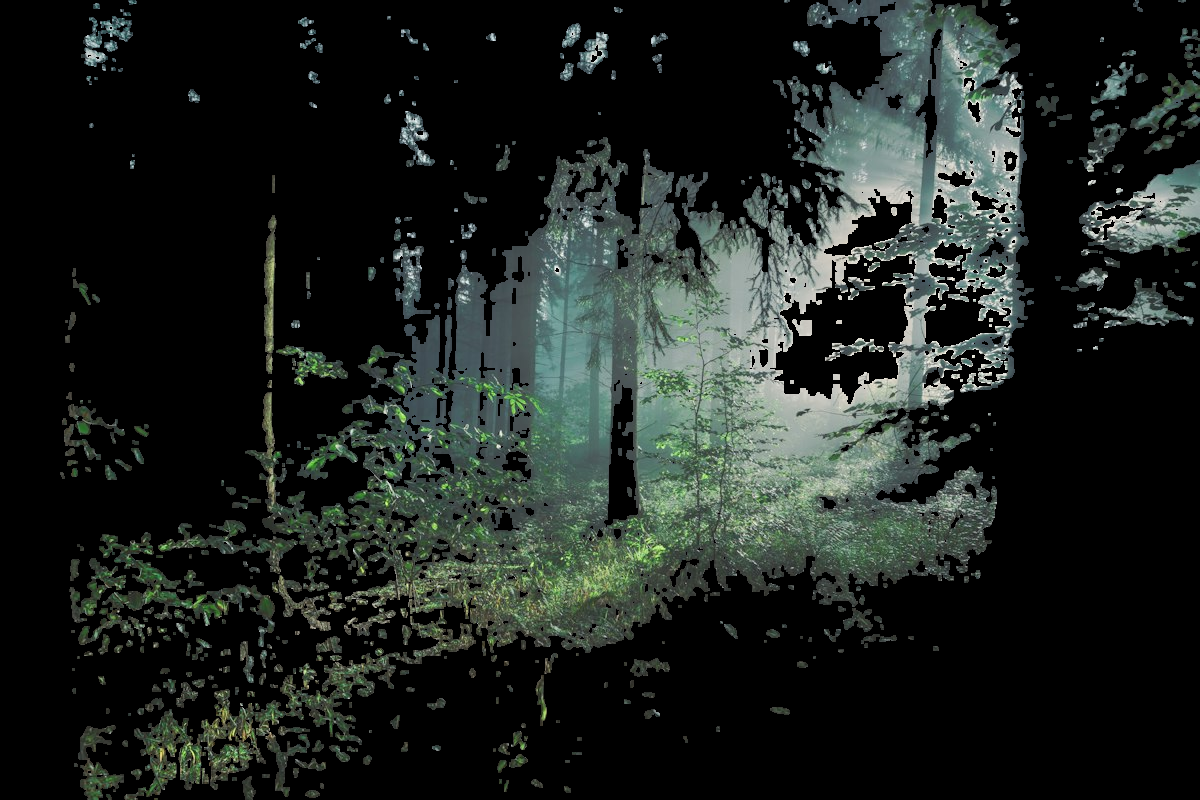

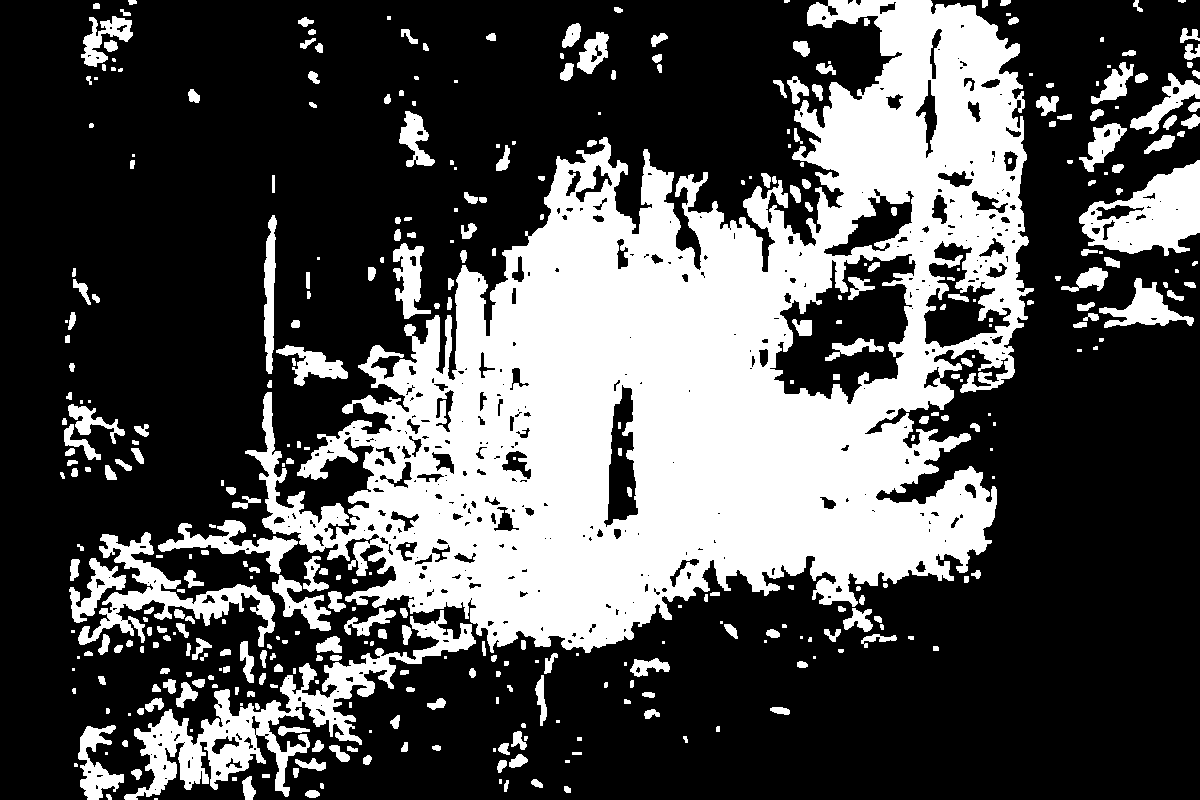

Roboflow forest provider failed: No module named 'supervision'
SAM3 forest provider failed: SAM3 did not return a readable mask.
========== ExG FALLBACK ==========
Coverage    : 28.28%


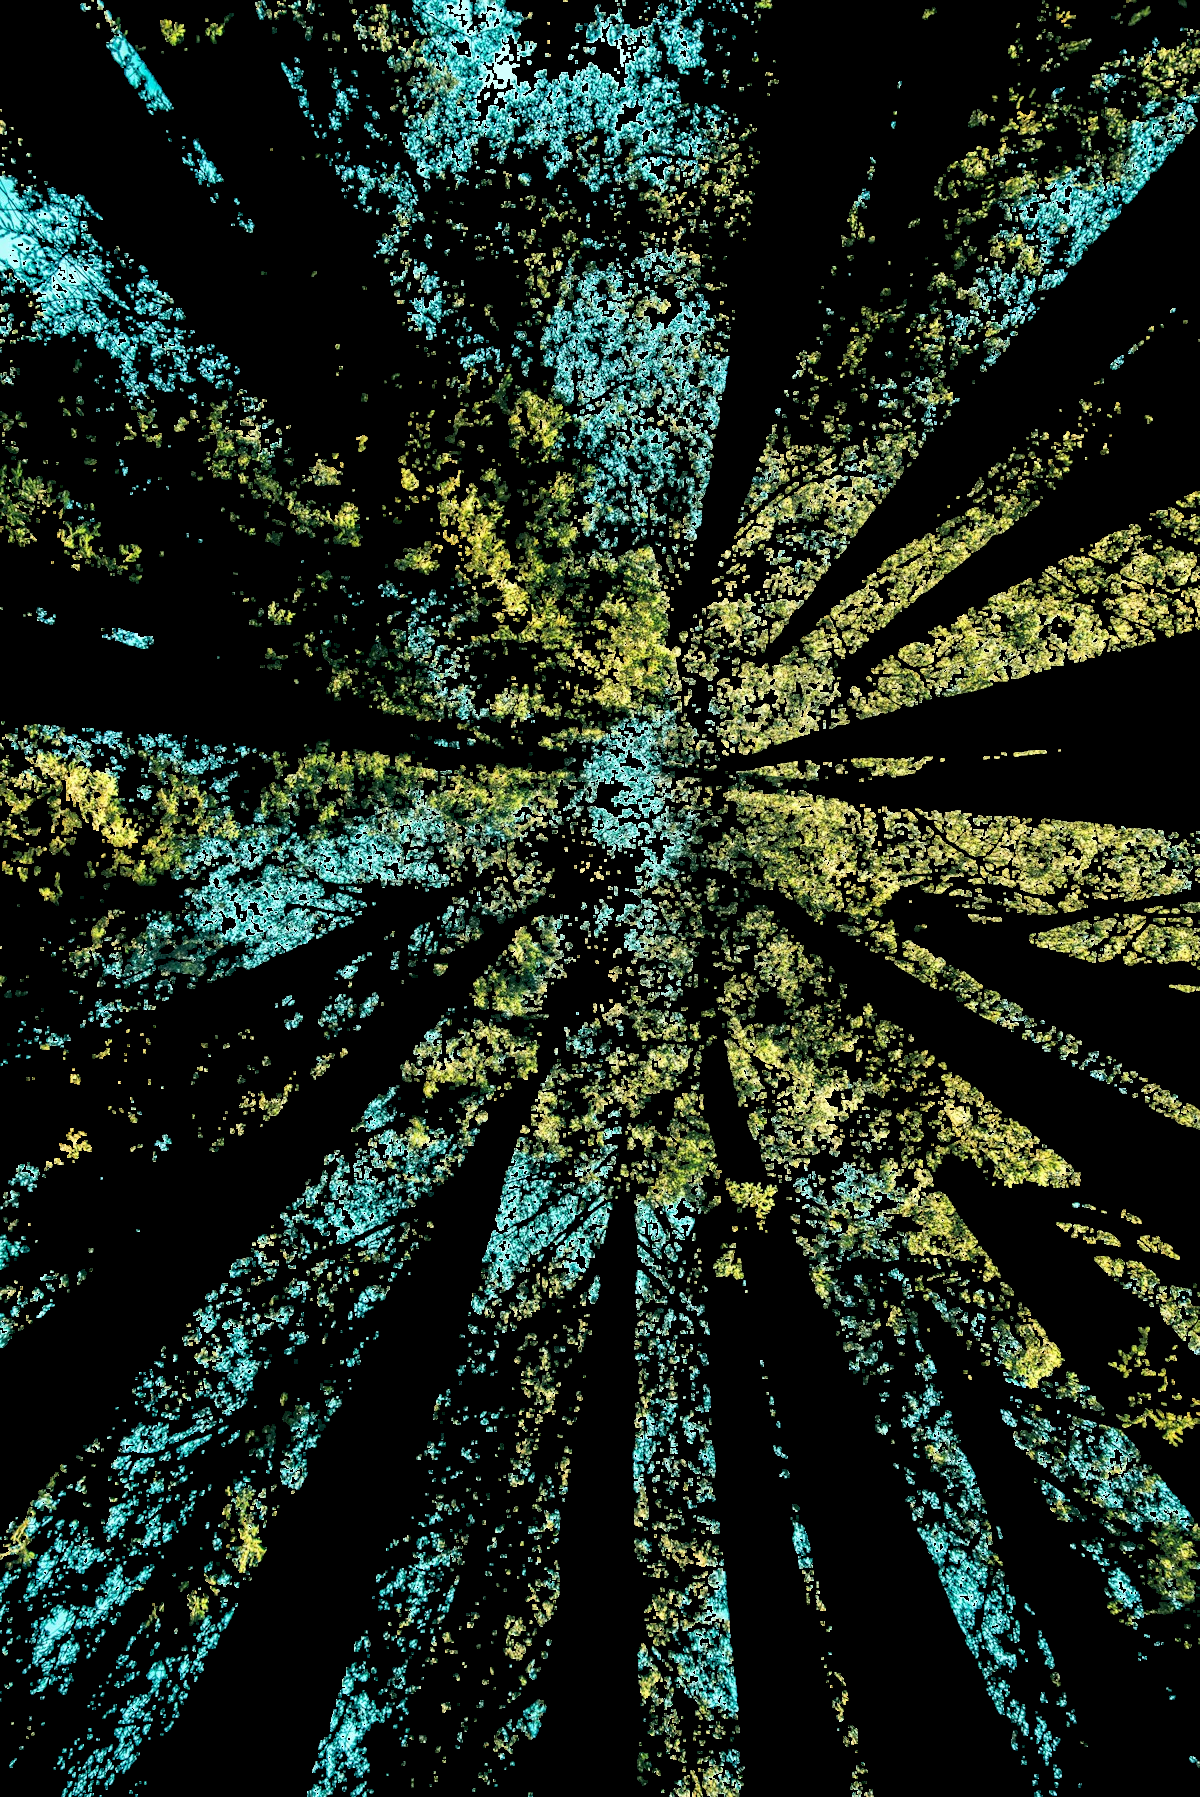

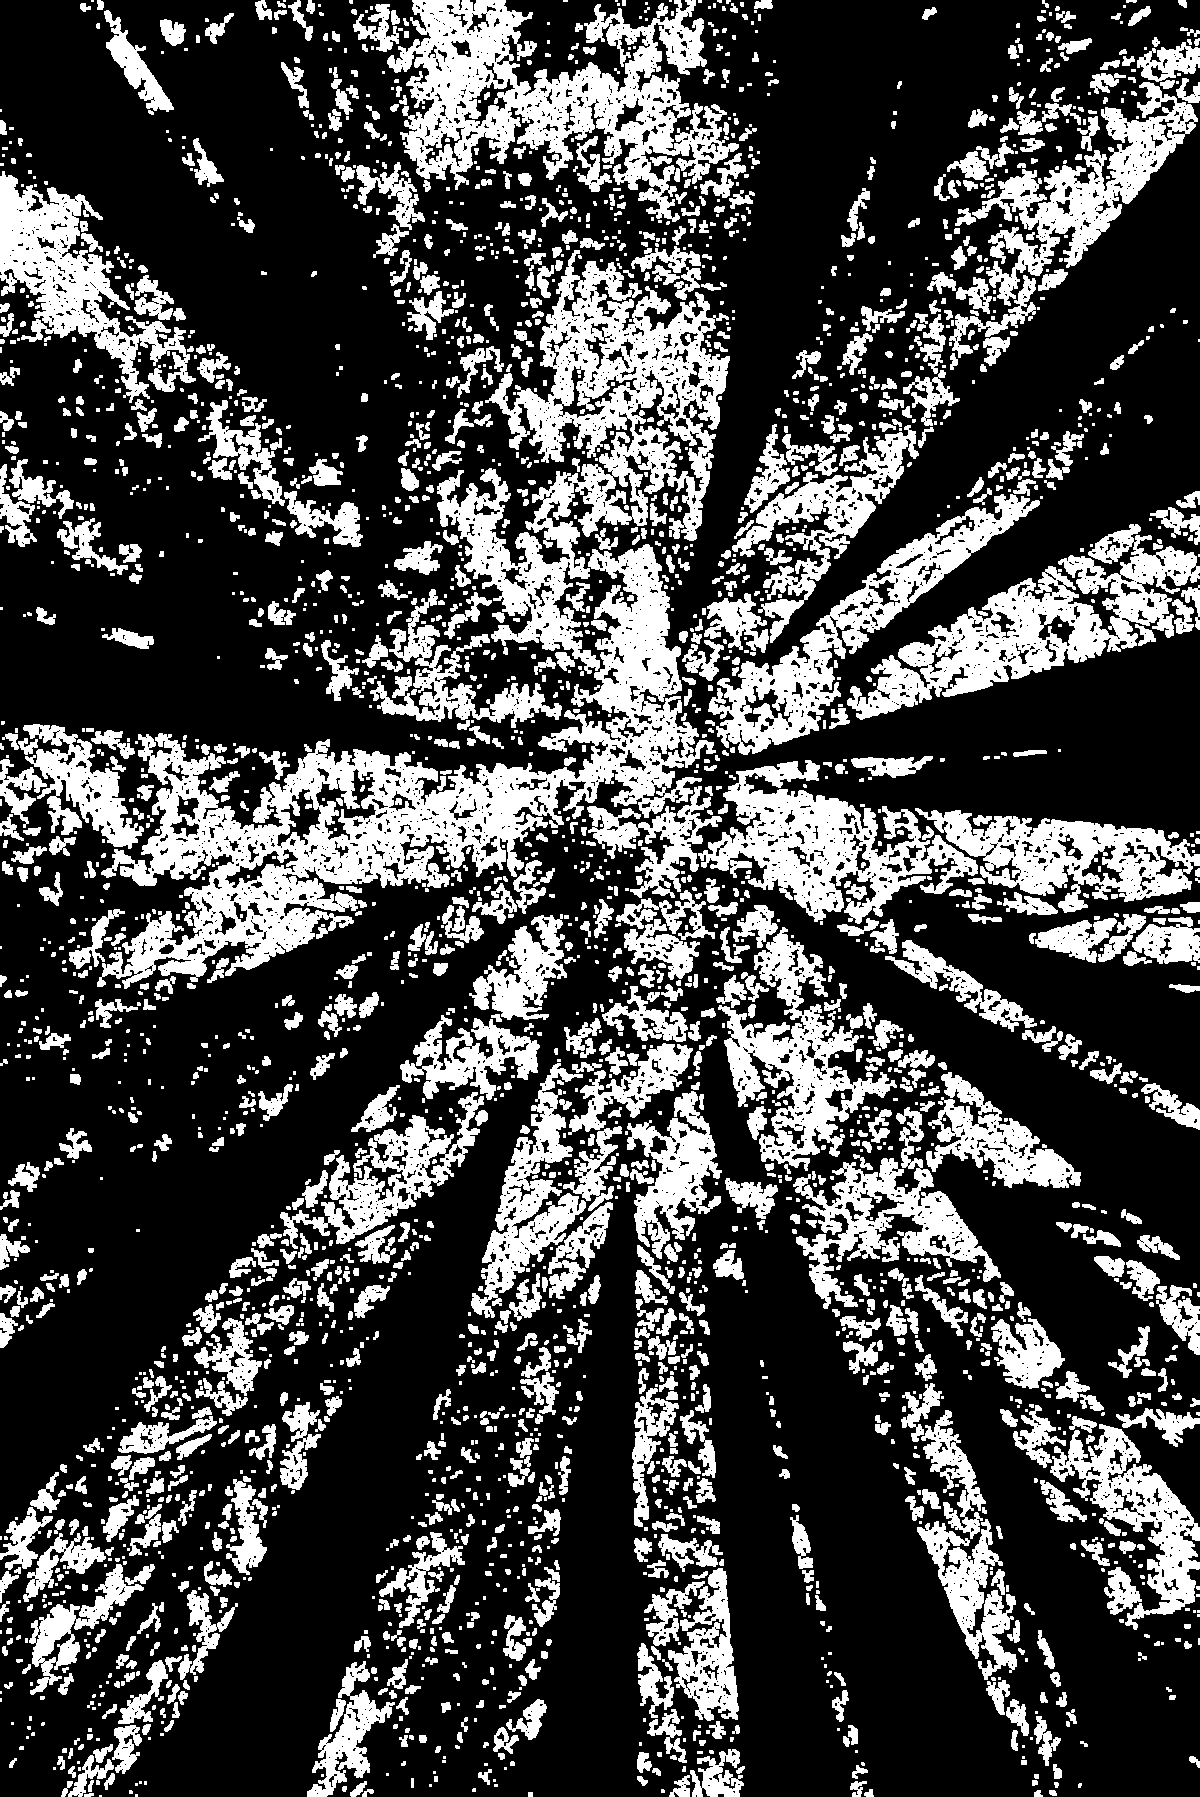

In [17]:
# 1. Install Supabase library if not installed
!pip install supabase requests

# 2. Connect to Supabase
from supabase import create_client, Client

SUPABASE_URL = "https://itpfveokpvzcbmoogcui.supabase.co"
# Paste your Secret key (sb_secret_IF4du...) below:
SUPABASE_SERVICE_ROLE_KEY = "https://itpfveokpvzcbmoogcui.supabase.co"

supabase: Client = create_client(SUPABASE_URL, SUPABASE_SERVICE_ROLE_KEY)
print("Connected to Supabase successfully! ✓")